In [ ]:
RANDOM_STATE: int = 42
CV_SPLITS: int = 5
N_JOBS: int = -1
SPLIT_SAMPLES_BY: int = 2
TEST_SIZE: float = 0.2
VERBOSE: int = 3
CACHE: int = 1000

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time
import os
from pathlib import Path
from seaborn import histplot, heatmap, boxplot, set_theme
from pandas import DataFrame, Series, read_csv, read_excel
from numpy import ndarray, dtype, uint8, uint16, uint32, uint
from numpy.typing import DTypeLike
from abc import ABC
from enum import Enum, auto
from google.colab import drive
from kagglehub import dataset_download

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, confusion_matrix, ConfusionMatrixDisplay, classification_report, accuracy_score
from sklearn.model_selection import train_test_split, cross_val_score, KFold, GridSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.svm import SVR, SVC
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from xgboost import XGBRegressor, XGBClassifier

print("Versão do Pandas:", pd.__version__)
print("Versão do Numpy:", np.__version__)
np.random.seed(RANDOM_STATE)
plt.rcParams["figure.figsize"] = (8, 5)
set_theme(style="whitegrid")
print("Bibliotecas importadas com sucesso!")

Versão do Pandas: 2.2.3
Versão do Numpy: 2.4.6
Bibliotecas importadas com sucesso!


# Literary Digest

In [ ]:
# 1. Conecta a VM do Google Colab ao armazenamento do Google Drive
drive.mount('/content/drive')
# 2. Define o caminho absoluto exato da planilha de dados no Google Drive
file_path: str = '/content/drive/MyDrive/SUMMIT/LitDigestFull.xlsx'
# file_path: str = 'LitDigestFull.xlsx'

# 3. Dicionário de metadados com anotação de tipos (dict[str, list[tuple[int, int]]]).
# A estrutura mapeia cada ano (aba da planilha) para uma lista de tuplas no formato (coluna_inicial, largura_do_bloco).
tables_indexes_sizes: dict[str, list[tuple[int, int]]] = {
    '1924': [
        (1, 1), # _electoral_votes
        (2, 8), # __candidates
        (13, 6), # __same_voters_1920
        (19, 1), # _total_per_state
        (22, 22), # _results
    ],
    '1928': [
        (1, 1), # _electoral_votes
        (2, 1), # __hoover
        (3, 6), # __hoover_voters_1924
        (10, 1), # __smith
        (11, 6), # __smith_voters_1924
        (20, 3), # __minor_candidates
        (23, 1), # __total_per_state
        (26, 19), # _results
    ],
    '1932': [
        (1, 1), # _electoral_votes
        (2, 1), # __hoover
        (3, 4), # __hoover_voters_1928
        (9, 1), # __roosevelt
        (10, 4), # __roosevelt_voters_1928
        (16, 7), # _minor_candidates
        (24, 1), # _total_per_state
        (28, 16), # _results
    ],
    '1936': [
        (1, 1), # _electoral_votes
        (2, 1), # __landon
        (3, 6), # __landon_voters_1932
        (10, 1), # __roosevelt
        (11, 6), # __roosevelt_voters_1932
        (18, 1), # __lemke
        (19, 6), # __lemke_voters_1932
        (26, 6), # __minor_candidates
        (32, 1), # _total_per_state
        (35, 19), # _results
    ]
}

discarded_lines: list[int] = [8, -2] # (Distrito de Columbia e Estados desconhecidos)

class StatesEnum(Enum):
    ALABAMA = auto(), 'AL'
    ARIZONA = auto(), 'AZ'
    ARKANSAS = auto(), 'AR'
    CALIFORNIA = auto(), 'CA'
    COLORADO = auto(), 'CO'
    CONNECTICUT = auto(), 'CT'
    DELAWARE = auto(), 'DE'
    FLORIDA = auto(), 'FL'
    GEORGIA = auto(), 'GA'
    IDAHO = auto(), 'ID'
    ILLINOIS = auto(), 'IL'
    INDIANA = auto(), 'IN'
    IOWA = auto(), 'IA'
    KANSAS = auto(), 'KS'
    KENTUCKY = auto(), 'KY'
    LOUISIANA = auto(), 'LA'
    MAINE = auto(), 'ME'
    MARYLAND = auto(), 'MD'
    MASSACHUSETTS = auto(), 'MA'
    MICHIGAN = auto(), 'MI'
    MINNESOTA = auto(), 'MN'
    MISSISSIPPI = auto(), 'MS'
    MISSOURI = auto(), 'MO'
    MONTANA = auto(), 'MT'
    NEBRASKA = auto(), 'NE'
    NEVADA = auto(), 'NV'
    NEW_HAMPSHIRE = auto(), 'NH'
    NEW_JERSEY = auto(), 'NJ'
    NEW_MEXICO = auto(), 'NM'
    NEW_YORK = auto(), 'NY'
    NORTH_CAROLINA = auto(), 'NC'
    NORTH_DAKOTA = auto(), 'ND'
    OHIO = auto(), 'OH'
    OKLAHOMA = auto(), 'OK'
    OREGON = auto(), 'OR'
    PENNSYLVANIA = auto(), 'PA'
    RHODE_ISLAND = auto(), 'RI'
    SOUTH_CAROLINA = auto(), 'SC'
    SOUTH_DAKOTA = auto(), 'SD'
    TENNESSEE = auto(), 'TN'
    TEXAS = auto(), 'TX'
    UTAH = auto(), 'UT'
    VERMONT = auto(), 'VT'
    VIRGINIA = auto(), 'VA'
    WASHINGTON = auto(), 'WA'
    WEST_VIRGINIA = auto(), 'WV'
    WISCONSIN = auto(), 'WI'
    WYOMING = auto(), 'WY'

def read_path(path: str) -> dict[str, pd.DataFrame]:
  # Lê a planilha Excel carrega só as abas necessárias em um único procedimento.
  #Trata erros de arquivo ausente ou com caminho incorreto.

    try:
  # Carrega em lote apenas as abas declaradas no dicionário de metadados
        excel_data = pd.read_excel(
            path,
            sheet_name=list(tables_indexes_sizes.keys()),
        )
    except (FileNotFoundError, ValueError, OSError) as error:
# Trata exceções exibindo mensagem amigável e retornando dicionário vazio
        print(f"\nArquivo inválido ou não encontrado: {path} ({error})\n")
        return {}
    else:
# Retorna o dicionário contendo os DataFrames brutos lidos
        return excel_data

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Gera um array NumPy de índices de colunas otimizado em memória usando o tipo uint8
# (inteiros sem sinal de 8 bits, alocando apenas 1 byte por número).
def create_columns_index(first: int, size: int) -> ndarray[tuple[int], dtype[uint8]]:

# Gera a sequência contínua de índices numéricos de colunas em baixo nível
    return np.array(range(size), dtype=uint8) + first

#Fatia a aba do Excel em sub-tabelas utilizando o método nativo em C 'take()' do Pandas.
#A extração posicional (axis='columns') garante alta performance e independência de nomes de colunas.

def tables_to_df(sheet: DataFrame, indexes_sizes: list[tuple[int, int]]) -> list[DataFrame]:

    return [
  # Aplica a extração de alta performance para cada tupla (índice, tamanho) da aba
        sheet.take(indices=create_columns_index(index, size), axis='columns') for index, size in indexes_sizes
    ]

In [ ]:
# 1. Carrega todas as abas do Excel para a memória em um dicionário de DataFrames brutos
sheets: dict[str, DataFrame] = read_path(file_path)

# 2. Executa a dictionary comprehension para fatiar todas as sub-tabelas de cada ano em lote,
# gerando a estrutura final higienizada em 'raw_tables'

raw_tables: dict[str, list[DataFrame]] = {
    name: tables_to_df(sheets[name], indexes)
    for name, indexes in tables_indexes_sizes.items()
}

del tables_indexes_sizes, sheets

In [ ]:
class Votes(ABC):
    __slots__ = ('_results', '_electoral_votes', '_total_per_state')
# __slots__ limita a criação de atributos dinâmicos (__dict__), reduzindo drasticamente
    _results: DataFrame
# Declaração das anotações de tipo dos atributos protegidos da classe base
    _electoral_votes: ndarray[tuple[int], dtype[uint8]] # Array NumPy (uint8: 0 a 255) para os votos eleitorais
    _total_per_state: ndarray[tuple[int], dtype[uint32]] # Array NumPy (uint32) para a contagem total de respostas por estado

    def _clean_lines(self, df: DataFrame) -> DataFrame:
# Método interno de higienização: Remove linhas que estejam completamente vazias (NaN em todas as colunas).
        return df.dropna(axis='index', how='all')

    def _series_to_nparray(self, df: DataFrame, dtype: DTypeLike = uint16) -> ndarray[tuple[int], dtype[uint]]:
# Converte uma coluna de DataFrame em um ndarray NumPy tipado, descartando cabeçalhos e a linha final de total.
        df = self._clean_lines(df)
# Higieniza o DataFrame removendo linhas totalmente nulas
        return np.asarray(df[df.columns[0]].to_numpy(), dtype)
# Seleciona a 1ª coluna, fatia a partir da linha de cabeçalho até a penúltima linha (exclui o total) e converte para array NumPy

    def _get_totals(self, df: DataFrame) -> ndarray[tuple[int], dtype[uint32]]:
# Método interno de higienização: Remove linhas que estejam completamente vazias (NaN em todas as colunas).
        return df.values[-1]

    def get_electoral_votes(self) -> ndarray[tuple[int], dtype[uint8]]:
# Getter público: Retorna a série de votos do Colégio Eleitoral por estado.
        return self._electoral_votes[:-1]

    def get_total_per_state(self) -> ndarray[tuple[int], dtype[uint32]]:
# Getter público: Retorna o total de respostas da pesquisa por estado (excluindo a linha final do somatório nacional).
        return self._total_per_state[:-1]

    def get_results(self) -> DataFrame:
# Getter público: Retorna a tabela de resultados das urnas por estado (excluindo a linha final de totalizador).
        return self._results[:-1]

    def get_total_results(self) -> ndarray[tuple[int], dtype[uint32]]:
# Getter público: Retorna apenas o vetor do somatório nacional dos resultados reais (última linha).
        return self._get_totals(self._results)

    def _set_header_from(self, df: DataFrame, line_index: int = 0) -> DataFrame:
        df.columns = df.values[line_index]
        return df.drop(index=line_index)

    def _discard_lines(self, source: DataFrame, indexes: list[int]) -> DataFrame:
        return source.drop(index=[source.index[index] for index in indexes])

    def _prepare_dataframe(self, df: DataFrame, header_index: int = -1, discard_indexes: list[int] = [], clean_lines: bool = True) -> DataFrame:
        if clean_lines: df = self._clean_lines(df)
        if header_index != -1: df = self._set_header_from(df, header_index)
        if not len(discarded_lines) == 0: df = self._discard_lines(df, discard_indexes)
        return df

    def _prepare_nparray(self, df: DataFrame, header_index: int = -1, discard_indexes: list[int] = [], clean_lines: bool = True, dtype: DTypeLike = uint32) -> ndarray[tuple[int], dtype[uint]]:
        return self._series_to_nparray(self._prepare_dataframe(df, header_index, discard_indexes, clean_lines), dtype)

In [ ]:
class Votes1924(Votes):
# __slots__ específico para os atributos privados exclusivos da eleição de 1924
    __slots__ = ('__candidates', '__same_voters_1920')
    __candidates: DataFrame
    __same_voters_1920: DataFrame

    def __init__(self, electoral_votes: DataFrame, candidates: DataFrame, same_voters_1920: DataFrame, total_per_state: DataFrame, results: DataFrame) -> None:
# Construtor da classe para o ano de 1924: Recebe as sub-tabelas fatiadas e inicializa os atributos tratados.
# Remove a última coluna da sub-tabela de candidatos (geralmente uma coluna duplicada de total)

        self.__candidates = self._prepare_dataframe(candidates, discard_indexes=discarded_lines)
# Atribui a sub-tabela do histórico do voto cruzado da eleição de 1920
        self.__same_voters_1920 = self._prepare_dataframe(same_voters_1920, discard_indexes=discarded_lines)
# Converte e armazena os votos eleitorais usando uint8 (economia de memória)
        self._electoral_votes = self._prepare_nparray(electoral_votes, discard_indexes=[discarded_lines[0]], dtype=uint16).astype(uint16)
# Atribui o DataFrame do total por estado
        self._total_per_state = self._prepare_nparray(total_per_state, discard_indexes=discarded_lines, dtype=uint32).astype(uint32)
# Atribui o DataFrame com os resultados reais de 1924 (Wikipedia)
        self._results = self._prepare_dataframe(results)

    def get_candidates(self) -> DataFrame:
 # Getter público: Retorna as intenções de voto dos candidatos de 1924 por estado (sem a linha de total).
        return self.__candidates[:-1]

    def get_total_candidates(self) -> ndarray[tuple[int], dtype[uint32]]:
# Getter público: Retorna o vetor com o somatório nacional de votos de cada candidato em 1924.
        return self._get_totals(self.__candidates)

    def get_same_voters_1920(self) -> DataFrame:
# Getter público: Retorna o histórico de como os eleitores de 1924 votaram em 1920 por estado (sem a linha de total).
        return self.__same_voters_1920[:-1]

    def get_total_same_voters_1920(self) -> ndarray[tuple[int], dtype[uint32]]:
# Getter público: Retorna o vetor com o somatório nacional do histórico de voto de 1920.
        return self._get_totals(self.__same_voters_1920)

In [ ]:
# Classe derivada concreta referente ao ano eleitoral de 1928 (Hoover x Smith)
class Votes1928(Votes):
# __slots__ limita dinamicamente os atributos da classe aos declarados, reduzindo o consumo de memória RAM
    __slots__ = ('__hoover', '__hoover_voters_1924', '__smith', '__smith_voters_1924', '__minor_candidates')
    __hoover: ndarray[tuple[int], dtype[uint32]]
    __hoover_voters_1924: DataFrame
    __smith: ndarray[tuple[int], dtype[uint32]]
    __smith_voters_1924: DataFrame
    __minor_candidates: DataFrame

# Construtor da classe de 1928: recebe os DataFrames fatiados e os converte para estruturas otimizadas
    def __init__(self, electoral_votes: DataFrame, hoover: DataFrame, hoover_voters_1924: DataFrame, smith: DataFrame, smith_voters_1924: DataFrame, minor_candidates: DataFrame, total_per_state: DataFrame, results: DataFrame) -> None:
# Converte a coluna de votos de Herbert Hoover em ndarray NumPy tipado (uint32)
        self.__hoover = self._prepare_nparray(hoover, header_index=0, discard_indexes=discarded_lines, dtype=uint32).astype(uint32)
# Armazena a sub-tabela com o histórico do voto de 1924 dos eleitores de Hoover
        self.__hoover_voters_1924 = self._prepare_dataframe(hoover_voters_1924, header_index=0, discard_indexes=discarded_lines)
# Converte a coluna de votos de Alfred Smith em ndarray NumPy tipado (uint32)
        self.__smith = self._prepare_nparray(smith, header_index=0, discard_indexes=discarded_lines, dtype=uint32).astype(uint32)
# Armazena a sub-tabela com o histórico do voto de 1924 dos eleitores de Smith
        self.__smith_voters_1924 = self._prepare_dataframe(smith_voters_1924, header_index=0, discard_indexes=discarded_lines)
# Armazena o DataFrame dos candidatos minoritários
        self.__minor_candidates = self._prepare_dataframe(minor_candidates, header_index=0, discard_indexes=discarded_lines)
# Converte os votos do Colégio Eleitoral em array NumPy tipado (uint8)
        self._electoral_votes = self._prepare_nparray(electoral_votes, header_index=0, discard_indexes=discarded_lines[1:], dtype=uint16).astype(uint16)
# Converte os totais por estado em array NumPy tipado (uint32)
        self._total_per_state = self._prepare_nparray(total_per_state, header_index=0, discard_indexes=discarded_lines, dtype=uint32).astype(uint32)
# Armazena a sub-tabela com os resultados reais das urnas de 1928
        self._results = self._prepare_dataframe(results)

    def get_hoover(self) -> ndarray[tuple[int], dtype[uint32]]:
# Getter público: retorna os votos em Hoover por estado (excluindo a linha final de totalizador)
        return self.__hoover[:-1]

    def get_total_hoover(self) -> uint32:
# Getter público: retorna o totalizador nacional de votos de Hoover
        return self.__hoover[-1]

    def get_hoover_voters_1924(self) -> DataFrame:
# Getter público: retorna o histórico do voto de 1924 dos eleitores de Hoover por estado (sem totalizador)
        return self.__hoover_voters_1924[:-1]

    def get_total_hoover_voters_1924(self) -> ndarray[tuple[int], dtype[uint32]]:
# Getter público: retorna o somatório nacional do histórico de 1924 dos eleitores de Hoover
        return self._get_totals(self.__hoover_voters_1924)

    def get_smith(self) -> ndarray[tuple[int], dtype[uint32]]:
# Getter público: retorna os votos em Smith por estado (excluindo a linha final de totalizador)
        return self.__smith[:-1]

    def get_total_smith(self) -> uint32:
# Getter público: retorna o totalizador nacional de votos de Smith
        return self.__smith[-1]

    def get_smith_voters_1924(self) -> DataFrame:
# Getter público: retorna o histórico do voto de 1924 dos eleitores de Smith por estado (sem totalizador)
        return self.__smith_voters_1924[:-1]

    def get_total_smith_voters_1924(self) -> ndarray[tuple[int], dtype[uint32]]:
# Getter público: retorna o somatório nacional do histórico de 1924 dos eleitores de Smith
        return self._get_totals(self.__smith_voters_1924)

    def get_minor_candidates(self) -> DataFrame:
# Getter público: retorna as votações dos candidatos minoritários por estado (sem totalizador)
        return self.__minor_candidates[:-1]

    def get_total_minor_candidates(self) -> ndarray[tuple[int], dtype[uint32]]:
# Getter público: retorna o somatório nacional dos candidatos minoritários
        return self._get_totals(self.__minor_candidates)

In [ ]:
# Classe derivada concreta referente ao ano eleitoral de 1932 (Hoover x Roosevelt)
class Votes1932(Votes):
# __slots__ limita dinamicamente os atributos da classe aos declarados, reduzindo o consumo de memória RAM
    __slots__ = ('__hoover', '__hoover_voters_1928', '__roosevelt', '__roosevelt_voters_1928', '__minor_candidates')
    __hoover: ndarray[tuple[int], dtype[uint32]]
    __hoover_voters_1928: DataFrame
    __roosevelt: ndarray[tuple[int], dtype[uint32]]
    __roosevelt_voters_1928: DataFrame
    __minor_candidates: DataFrame

# Construtor da classe de 1932: recebe os DataFrames fatiados e os converte para estruturas otimizadas
    def __init__(self, electoral_votes: DataFrame, hoover: DataFrame, hoover_voters_1928: DataFrame, roosevelt: DataFrame, roosevelt_voters_1928: DataFrame, minor_candidates: DataFrame, total_per_state: DataFrame, results: DataFrame) -> None:
# Converte a coluna de votos de Herbert Hoover em ndarray NumPy tipado (uint32)
        self.__hoover = self._prepare_nparray(hoover, header_index=0, discard_indexes=discarded_lines, dtype=uint32).astype(uint32)
# Armazena a sub-tabela com o histórico do voto de 1928 dos eleitores de Hoover
        self.__hoover_voters_1928 = self._prepare_dataframe(hoover_voters_1928, header_index=0, discard_indexes=discarded_lines)
# Converte a coluna de votos de Franklin D. Roosevelt em ndarray NumPy tipado (uint32)
        self.__roosevelt = self._prepare_nparray(roosevelt, header_index=0, discard_indexes=discarded_lines, dtype=uint32).astype(uint32)
# Armazena a sub-tabela com o histórico do voto de 1928 dos eleitores de Roosevelt
        self.__roosevelt_voters_1928 = self._prepare_dataframe(roosevelt_voters_1928, header_index=0, discard_indexes=discarded_lines)
# Armazena o DataFrame dos candidatos minoritários
        self.__minor_candidates = self._prepare_dataframe(minor_candidates, header_index=0, discard_indexes=discarded_lines)
# Converte os votos do Colégio Eleitoral em array NumPy tipado (uint8)
        self._electoral_votes = self._prepare_nparray(electoral_votes, header_index=0, discard_indexes=discarded_lines, dtype=uint16).astype(uint16)
# Converte os totais por estado em array NumPy tipado (uint32)
        self._total_per_state = self._prepare_nparray(total_per_state, header_index=0, discard_indexes=discarded_lines, dtype=uint32).astype(uint32)
# Armazena a sub-tabela com os resultados reais das urnas de 1932
        self._results = self._prepare_dataframe(results)

    def get_hoover(self) -> ndarray[tuple[int], dtype[uint32]]:
# Getter público: retorna os votos em Hoover por estado (excluindo a linha final de totalizador)
        return self.__hoover[:-1]

    def get_total_hoover(self) -> uint32:
# Getter público: retorna o totalizador nacional de votos de Hoover
        return self.__hoover[-1]

    def get_hoover_voters_1928(self) -> DataFrame:
# Getter público: retorna o histórico do voto de 1928 dos eleitores de Hoover por estado (sem totalizador)
        return self.__hoover_voters_1928[:-1]

    def get_total_hoover_voters_1928(self) -> ndarray[tuple[int], dtype[uint32]]:
# Getter público: retorna o somatório nacional do histórico de 1928 dos eleitores de Hoover
        return self._get_totals(self.__hoover_voters_1928)

    def get_roosevelt(self) -> ndarray[tuple[int], dtype[uint32]]:
# Getter público: retorna os votos em Roosevelt por estado (excluindo a linha final de totalizador)
        return self.__roosevelt[:-1]

    def get_total_roosevelt(self) -> uint32:
# Getter público: retorna o totalizador nacional de votos de Roosevelt
        return self.__roosevelt[-1]

    def get_roosevelt_voters_1928(self) -> DataFrame:
# Getter público: retorna o histórico do voto de 1928 dos eleitores de Roosevelt por estado (sem totalizador)
        return self.__roosevelt_voters_1928[:-1]

    def get_total_roosevelt_voters_1928(self) -> ndarray[tuple[int], dtype[uint32]]:
# Getter público: retorna o somatório nacional do histórico de 1928 dos eleitores de Roosevelt
        return self._get_totals(self.__roosevelt_voters_1928)

    def get_minor_candidates(self) -> DataFrame:
# Getter público: retorna as votações dos candidatos minoritários por estado (sem totalizador)
        return self.__minor_candidates[:-1]

    def get_total_minor_candidates(self) -> ndarray[tuple[int], dtype[uint32]]:
# Getter público: retorna o somatório nacional dos candidatos minoritários
        return self._get_totals(self.__minor_candidates)

In [ ]:
# Classe derivada concreta referente ao ano eleitoral decisivo de 1936 (Landon x Roosevelt x Lemke)
class Votes1936(Votes):
# __slots__ limita dinamicamente os atributos da classe aos declarados, reduzindo o consumo de memória RAM
    __slots__ = ('__landon', '__landon_voters_1932', '__roosevelt', '__roosevelt_voters_1932', '__lemke', '__lemke_voters_1932', '__minor_candidates')
    __landon: ndarray[tuple[int], dtype[uint32]]
    __landon_voters_1932: DataFrame
    __roosevelt: ndarray[tuple[int], dtype[uint32]]
    __roosevelt_voters_1932: DataFrame
    __lemke: ndarray[tuple[int], dtype[uint32]]
    __lemke_voters_1932: DataFrame
    __minor_candidates: DataFrame

# Converte a coluna de votos de Alf Landon em ndarray NumPy tipado (uint32)
    def __init__(self, electoral_votes: DataFrame, landon: DataFrame, landon_voters_1932: DataFrame, roosevelt: DataFrame, roosevelt_voters_1932: DataFrame, lemke: DataFrame, lemke_voters_1932: DataFrame, minor_candidates: DataFrame, total_per_state: DataFrame, results: DataFrame) -> None:
# Armazena a sub-tabela com o histórico do voto de 1932 dos eleitores de Landon
        self.__landon = self._prepare_nparray(landon, header_index=0, discard_indexes=discarded_lines[1:], dtype=uint32).astype(uint32)
# Converte a coluna de votos de Franklin D. Roosevelt em ndarray NumPy tipado (uint32)
        self.__landon_voters_1932 = self._prepare_dataframe(landon_voters_1932, header_index=0, discard_indexes=discarded_lines[1:])
# Armazena a sub-tabela com o histórico do voto de 1932 dos eleitores de Roosevelt
        self.__roosevelt = self._prepare_nparray(roosevelt, header_index=0, discard_indexes=discarded_lines[1:], dtype=uint32).astype(uint32)
        self.__roosevelt_voters_1932 = self._prepare_dataframe(roosevelt_voters_1932, header_index=0, discard_indexes=discarded_lines[1:])
# Converte a coluna de votos de William Lemke (terceiro partido) em ndarray NumPy tipado (uint32)
        self.__lemke = self._prepare_nparray(lemke, header_index=0, discard_indexes=discarded_lines[1:], dtype=uint32).astype(uint32)
# Armazena a sub-tabela com o histórico do voto de 1932 dos eleitores de Lemke
        self.__lemke_voters_1932 = self._prepare_dataframe(lemke_voters_1932, header_index=0, discard_indexes=discarded_lines[1:])
# Armazena o DataFrame dos candidatos minoritários
        self.__minor_candidates = self._prepare_dataframe(minor_candidates, header_index=0, discard_indexes=discarded_lines[1:])
# Converte os votos do Colégio Eleitoral em array NumPy tipado (uint8)
        self._electoral_votes = self._prepare_nparray(electoral_votes, header_index=0, discard_indexes=discarded_lines[1:], dtype=uint16).astype(uint16)
# Converte os totais por estado em array NumPy tipado (uint32)
        self._total_per_state = self._prepare_nparray(total_per_state, header_index=0, discard_indexes=discarded_lines[1:], dtype=uint32).astype(uint32)
# Armazena a sub-tabela com os resultados reais das urnas de 1936
        self._results = self._prepare_dataframe(results)

    def get_landon(self) -> ndarray[tuple[int], dtype[uint32]]:
# Getter público: retorna os votos em Landon por estado (excluindo a linha final de totalizador)
        return self.__landon[:-1]

    def get_total_landon(self) -> uint32:
# Getter público: retorna o totalizador nacional de votos de Landon
        return self.__landon[-1]

    def get_landon_voters_1932(self) -> DataFrame:
# Getter público: retorna o histórico do voto de 1932 dos eleitores de Landon por estado (sem totalizador)
        return self.__landon_voters_1932[:-1]

    def get_total_landon_voters_1932(self) -> ndarray[tuple[int], dtype[uint32]]:
# Getter público: retorna o somatório nacional do histórico de 1932 dos eleitores de Landon
        return self._get_totals(self.__landon_voters_1932)

    def get_roosevelt(self) -> ndarray[tuple[int], dtype[uint32]]:
# Getter público: retorna os votos em Roosevelt por estado (excluindo a linha final de totalizador)
        return self.__roosevelt[:-1]

    def get_total_roosevelt(self) -> uint32:
# Getter público: retorna o totalizador nacional de votos de Roosevelt
        return self.__roosevelt[-1]

    def get_roosevelt_voters_1932(self) -> DataFrame:
# Getter público: retorna o histórico do voto de 1932 dos eleitores de Roosevelt por estado (sem totalizador)
        return self.__roosevelt_voters_1932[:-1]

    def get_total_roosevelt_voters_1932(self) -> ndarray[tuple[int], dtype[uint32]]:
# Getter público: retorna o somatório nacional do histórico de 1932 dos eleitores de Roosevelt
        return self._get_totals(self.__roosevelt_voters_1932)

    def get_lemke(self) -> ndarray[tuple[int], dtype[uint32]]:
# Getter público: retorna os votos em Lemke por estado (excluindo a linha final de totalizador)
        return self.__lemke[:-1]

    def get_total_lemke(self) -> uint32:
# Getter público: retorna o totalizador nacional de votos de Lemke
        return self.__lemke[-1]

    def get_lemke_voters_1932(self) -> DataFrame:
# Getter público: retorna o histórico do voto de 1932 dos eleitores de Lemke por estado (sem totalizador)
        return self.__lemke_voters_1932[:-1]

    def get_total_lemke_voters_1932(self) -> ndarray[tuple[int], dtype[uint32]]:
# Getter público: retorna o somatório nacional do histórico de 1932 dos eleitores de Lemke
        return self._get_totals(self.__lemke_voters_1932)

    def get_minor_candidates(self) -> DataFrame:
# Getter público: retorna as votações dos candidatos minoritários por estado (sem totalizador)
        return self.__minor_candidates[:-1]

    def get_total_minor_candidates(self) -> ndarray[tuple[int], dtype[uint32]]:
# Getter público: retorna o somatório nacional dos candidatos minoritários
        return self._get_totals(self.__minor_candidates)

In [ ]:
# Instancia o objeto 'votes1924' da classe Votes1924 utilizando o operador de desempacotamento posicional (*),
# repassando a lista de sub-tabelas do dicionário 'raw_tables['1924']' diretamente para o construtor __init__
votes1924: Votes1924 = Votes1924(*raw_tables['1924'])

# Instancia o objeto 'votes1928' da classe Votes1928 via desempacotamento posicional (*raw_tables['1928']),
# alimentando os parâmetros de candidatos e votação cruzada de 1924 com tipagem estrita
votes1928: Votes1928 = Votes1928(*raw_tables['1928'])

# Instancia o objeto 'votes1932' da classe Votes1932 via desempacotamento posicional (*raw_tables['1932']),
# mapeando as sub-tabelas de Hoover e Roosevelt e o histórico de 1928 para a estrutura estática
votes1932: Votes1932 = Votes1932(*raw_tables['1932'])

# Instancia o objeto 'votes1936' da classe Votes1936 via desempacotamento posicional (*raw_tables['1936']),
# inicializando o modelo trifurcado (Landon, Roosevelt e Lemke) com os dados das urnas e pesquisas
votes1936: Votes1936 = Votes1936(*raw_tables['1936'])

# Apaga explicitamente do ambiente Python o dicionário 'raw_tables' contendo a lista de DataFrames intermediários,
# acionando o Garbage Collector e liberando memória RAM após a conversão dos dados para os objetos tipados
del raw_tables

In [ ]:
# --- 1. Preparacao dos Dados de Treino (144 observacoes estaduais previas) ---
# x_train: Porcentagem prevista pela pesquisa Literary Digest em eleicoes passadas
# y_train: Porcentagem real obtida nas urnas nas mesmas eleicoes

rep_1924: ndarray[tuple[int], dtype[np.float32]] = votes1924.get_candidates()[votes1924.get_candidates().columns[0]].values.astype(np.float32)
rep_1928: ndarray[tuple[int], dtype[np.float32]] = votes1928.get_hoover().astype(np.float32)
rep_1932: ndarray[tuple[int], dtype[np.float32]] = votes1932.get_hoover().astype(np.float32)
rep_1936: ndarray[tuple[int], dtype[np.float32]] = votes1936.get_landon().astype(np.float32)

total_per_state_1924 = votes1924.get_total_per_state()
total_per_state_1928 = votes1928.get_total_per_state()
total_per_state_1932 = votes1932.get_total_per_state()
total_per_state_1936 = votes1936.get_total_per_state()

expected_rep_1924 = rep_1924 / total_per_state_1924
expected_rep_1928 = rep_1928 / total_per_state_1928
expected_rep_1932 = rep_1932 / total_per_state_1932
expected_rep_1936 = rep_1936 / total_per_state_1936

rep_total_expected_1924 = votes1924.get_total_candidates()[0]
rep_total_expected_1928 = votes1928.get_total_hoover()
rep_total_expected_1932 = votes1932.get_total_hoover()

results_1924 = votes1924.get_results()
results_1928 = votes1928.get_results()
results_1932 = votes1932.get_results()
results_1936 = votes1936.get_results()

total_results_1924 = votes1924.get_total_results()
total_results_1928 = votes1928.get_total_results()
total_results_1932 = votes1932.get_total_results()

In [ ]:
# =======
expected_prop_1924 = rep_total_expected_1924 / total_per_state_1924.sum()
expected_prop_1928 = rep_total_expected_1928 / total_per_state_1928.sum()
expected_prop_1932 = rep_total_expected_1932 / total_per_state_1932.sum()

actual_prop_1924 = total_results_1924[2] / 100
actual_prop_1928 = total_results_1928[2] / 100
actual_prop_1932 = total_results_1932[5] / 100

relative_scale_1924 = expected_prop_1924 - actual_prop_1924
relative_scale_1928 = expected_prop_1928 - actual_prop_1928
relative_scale_1932 = expected_prop_1932 - actual_prop_1932
# =======

# =======
rep_votes_from_1924 = votes1928.get_total_hoover_voters_1924()[0] + votes1928.get_total_smith_voters_1924()[0]
rep_votes_from_1928 = votes1932.get_total_hoover_voters_1928()[0] + votes1932.get_total_roosevelt_voters_1928()[0]
rep_votes_from_1932 = votes1936.get_total_landon_voters_1932()[0] + votes1936.get_total_roosevelt_voters_1932()[0] + votes1936.get_total_lemke_voters_1932()[0]

indicated_votes_from_1924 = votes1928.get_total_hoover_voters_1924()[:-1].sum() + votes1928.get_total_smith_voters_1924()[:-1].sum()
indicated_votes_from_1928 = votes1932.get_total_hoover_voters_1928()[:-1].sum() + votes1932.get_total_roosevelt_voters_1928()[:-1].sum()
indicated_votes_from_1932 = votes1936.get_total_landon_voters_1932()[:-2].sum() + votes1936.get_total_roosevelt_voters_1932()[:-2].sum() + votes1936.get_total_lemke_voters_1932()[:-2].sum()

collected_prop_1924 = rep_votes_from_1924 / indicated_votes_from_1924
collected_prop_1928 = rep_votes_from_1928 / indicated_votes_from_1928
collected_prop_1932 = rep_votes_from_1932 / indicated_votes_from_1932

deviation_from_1924 = actual_prop_1924 / collected_prop_1924
deviation_from_1928 = actual_prop_1928 / collected_prop_1928
deviation_from_1932 = actual_prop_1932 / collected_prop_1932
# =======

# print(deviation_from_1924, deviation_from_1928, deviation_from_1932)
# print(relative_scale_1924, relative_scale_1928, relative_scale_1932)

x_1924 = expected_rep_1924.reshape(-1, 1)
y_1924 = np.array(results_1924[results_1924.columns[2]].values) / 100

x_1928 = ((expected_rep_1928 + relative_scale_1924) * deviation_from_1924).reshape(-1, 1)
y_1928 = np.array(results_1928[results_1928.columns[2]].values) / 100

x_1932 = ((expected_rep_1932 + relative_scale_1928) * deviation_from_1928).reshape(-1, 1)
y_1932 = np.array(results_1932[results_1932.columns[5]].values) / 100

x_1936 = ((expected_rep_1936 + relative_scale_1932) * deviation_from_1932).reshape(-1, 1)
y_1936 = np.array(results_1936[results_1936.columns[5]].values) / 100

# print(DataFrame([x_1924[:10].reshape(1, -1)[0], y_1924[:10], x_1924[:10].reshape(1, -1)[0] - y_1924[:10], x_1928[:10].reshape(1, -1)[0], y_1928[:10], x_1928[:10].reshape(1, -1)[0] - y_1928[:10]]).transpose())
# print(DataFrame([x_1932[:10].reshape(1, -1)[0], y_1932[:10], x_1932[:10].reshape(1, -1)[0] - y_1932[:10], x_1936[:10].reshape(1, -1)[0], y_1936[:10], x_1936[:10].reshape(1, -1)[0] - y_1936[:10]]).transpose())
# print(x, y)

x = np.concat((x_1924, x_1928, x_1932))
y = np.concat((y_1924, y_1928, y_1932))

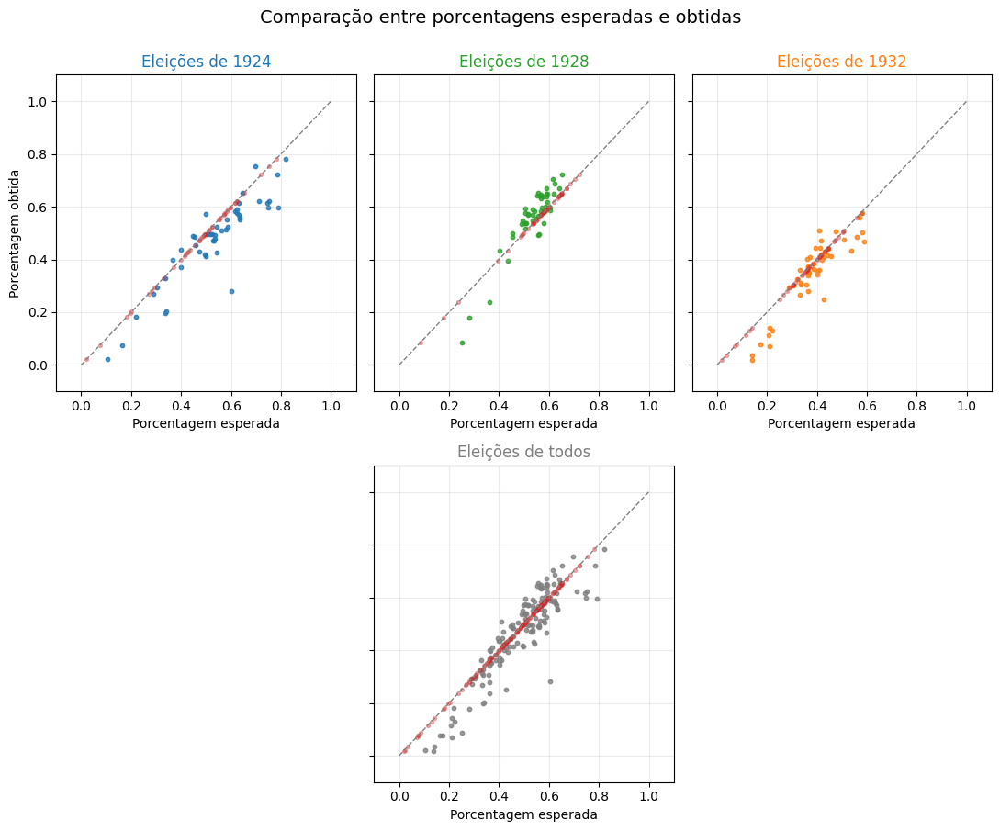

In [ ]:
# Scatter plots comparativos entre porcentagem esperada e porcentagem obtida
fig, axes = plt.subplots(2, 3, figsize=(11, 9), sharey=True)
axes = axes.ravel()
colors = ["tab:blue", "tab:green", "tab:orange", "tab:cyan", "tab:gray"]

comparative_data = [
    ("1924", x_1924, y_1924),
    ("1928", x_1928, y_1928),
    ("1932", x_1932, y_1932),
    ("1936", x_1936, y_1936),
    ("todos", x, y),
]

for ax, (year, expected, actual), color in zip(axes, comparative_data, colors):
    ax.scatter(expected, actual, s=10, alpha=0.8, color=color)
    ax.scatter(actual, actual, s=8, color='tab:red', alpha=0.35, label='Real')
    # min_val = min(float(expected.min()), float(actual.min()))
    # max_val = max(float(expected.max()), float(actual.max()))
    # pad = max(0.05, (max_val - min_val) * 0.15)
    # line_min, line_max = max(0.0, min_val - pad), min(1.0, max_val + pad)
    line_min, line_max = 0, 1
    ax.plot([line_min, line_max], [line_min, line_max], linestyle="--", color="gray", linewidth=1)
    ax.set_title(f"Eleições de {year}", color=color)
    ax.set_xlabel("Porcentagem esperada")
    if ax is axes[0]:
        ax.set_ylabel("Porcentagem obtida")
    ax.set_xlim(-0.1, 1.1)
    ax.set_ylim(-0.1, 1.1)
    ax.grid(True, alpha=0.25)

axes[-1].set_visible(False)
axes[-3].set_visible(False)
fig.suptitle("Comparação entre porcentagens esperadas e obtidas", fontsize=14, y=1)
fig.tight_layout()
plt.show()

In [ ]:
def scatter_predictions(y_pred):
    # Scatter plot comparativo entre resultados reais e previstos pelo modelo para 1936
    plt.figure(figsize=(8, 6))
    plt.scatter(y_1936, y_1936, s=15, color='tab:red', alpha=0.25, label='Real')
    plt.scatter(y_1936, y_pred, s=30, color='tab:blue', alpha=0.8, label='Previsto pelo modelo')

    min_val: float = min(float(y_1936.min()), float(y_pred.min()))
    max_val: float = max(float(y_1936.max()), float(y_pred.max()))
    margin: float = max(0.05, (max_val - min_val) * 0.12)
    line_min, line_max = max(0.0, min_val - margin), min(1.0, max_val + margin)
    plt.plot([line_min, line_max], [line_min, line_max], linestyle='--', color='black', linewidth=1.2, label='Referência y = x', alpha=0.25)

    plt.title('Comparação entre resultados reais e previstos para 1936')
    plt.xlabel('Resultado real')
    plt.ylabel('Resultado previsto')
    plt.xlim(-0.1, 1.0)
    plt.ylim(-0.1, 1.0)
    plt.grid(True, alpha=0.25)
    plt.legend()
    plt.tight_layout()
    plt.show()

def histplot_predictions(y_pred):
    plt.figure(figsize=(8, 5))
    histplot(y_1936, color='tab:red', label='Valores Reais (y_1936)', kde=True, alpha=0.6, bins=30)
    histplot(y_pred, color='tab:blue', label='Valores Previstos (y_pred)', kde=True, alpha=0.6, bins=30)
    plt.title('Distribuição dos Valores Reais vs. Previstos para 1936')
    plt.xlabel('Valores de Porcentagem')
    plt.ylabel('Frequência')
    plt.legend()
    plt.grid(True, alpha=0.25)
    plt.tight_layout()
    plt.show()

=============== Treinando SVR_LINEAR... ===============
Fitting 5 folds for each of 8 candidates, totalling 40 fits
[Pipeline] .............. (step 1 of 2) Processing prep, total=   0.0s
[Pipeline] ............... (step 2 of 2) Processing clf, total=   0.0s
Modelo treinado em 0.05s


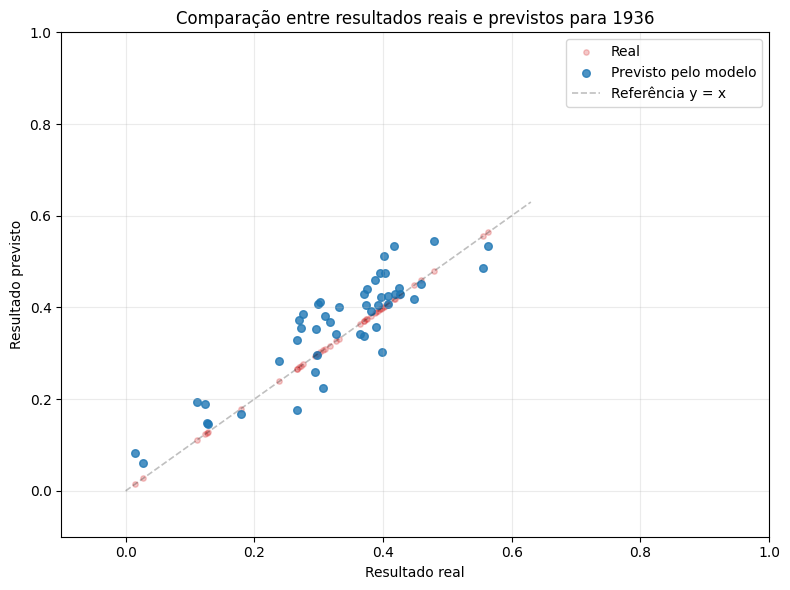

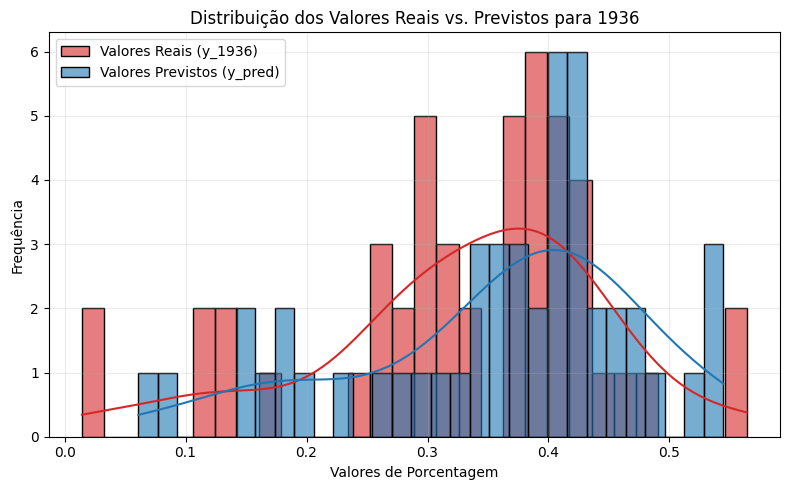

,MAE,RMSE,R2,Média,Desvio-padrão
0,0.051701,0.062008,0.724711,0.358316,0.117449


,2,4,3,7,6
param_clf__C,0.100000,5.000000,1.000000,100.000000,50.000000
split0_test_score,-0.068634,-0.068823,-0.068823,-0.068821,-0.068822
split1_test_score,-0.068470,-0.068470,-0.068470,-0.068470,-0.068470
split2_test_score,-0.088198,-0.088198,-0.088198,-0.088199,-0.088199
split3_test_score,-0.055814,-0.055774,-0.055776,-0.055815,-0.055815
split4_test_score,-0.062391,-0.062980,-0.062980,-0.062976,-0.062978
mean_test_score,-0.068702,-0.068849,-0.068849,-0.068856,-0.068857
rank_test_score,1.000000,2.000000,3.000000,4.000000,5.000000


None

=============== Treinando SVR_SIGMOID... ===============
Fitting 5 folds for each of 80 candidates, totalling 400 fits
[Pipeline] .............. (step 1 of 2) Processing prep, total=   0.0s
[Pipeline] ............... (step 2 of 2) Processing clf, total=   0.0s
Modelo treinado em 0.13s


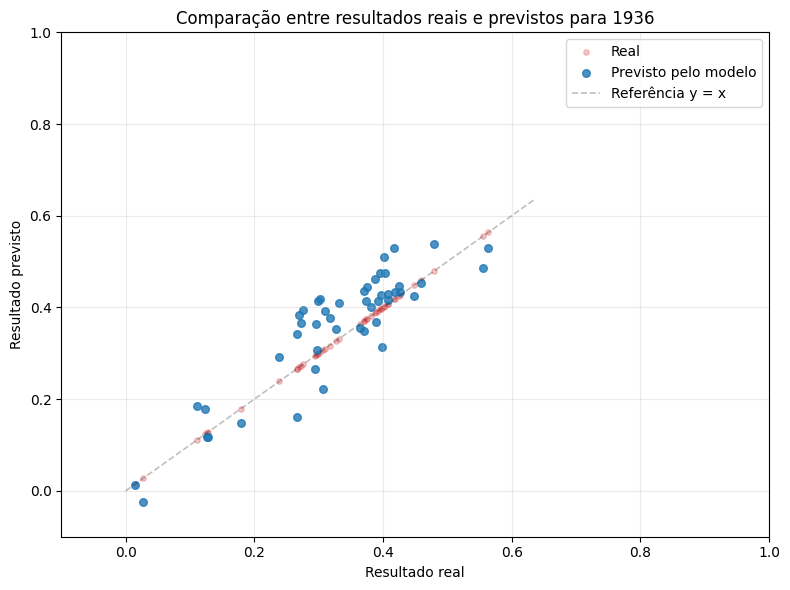

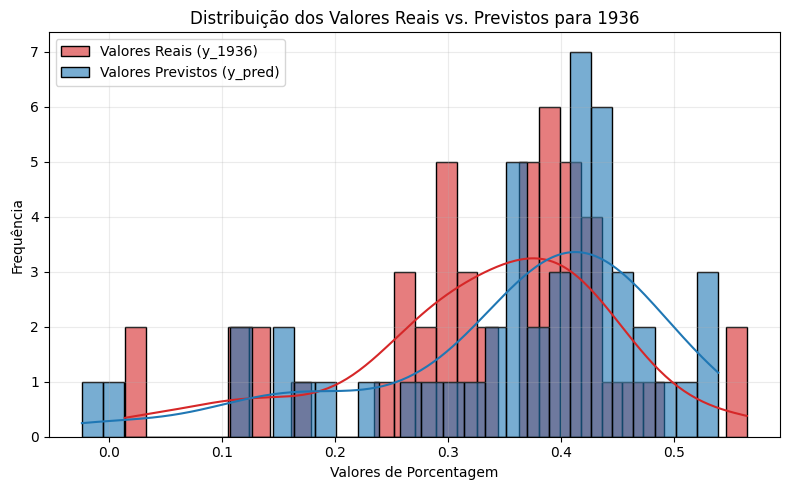

,MAE,RMSE,R2,Média,Desvio-padrão
0,0.053159,0.063998,0.706756,0.357538,0.129976


,62,2,41,42,22
param_clf__C,1.000000,0.250000,0.750000,0.750000,0.500000
param_clf__coef0,0.000000,0.000000,0.000000,0.000000,0.000000
param_clf__gamma,0.100000,0.100000,0.050000,0.100000,0.100000
split0_test_score,-0.069533,-0.068779,-0.068534,-0.068331,-0.068407
split1_test_score,-0.068067,-0.068123,-0.069702,-0.069912,-0.067667
split2_test_score,-0.086813,-0.086345,-0.086262,-0.086926,-0.087544
split3_test_score,-0.054040,-0.054269,-0.053960,-0.054042,-0.055673
split4_test_score,-0.062768,-0.063789,-0.063169,-0.062477,-0.062443
mean_test_score,-0.068244,-0.068261,-0.068325,-0.068338,-0.068347
rank_test_score,1.000000,2.000000,3.000000,4.000000,5.000000


None

=============== Treinando SVR_RBF... ===============
Fitting 5 folds for each of 42 candidates, totalling 210 fits
[Pipeline] .............. (step 1 of 2) Processing prep, total=   0.0s
[Pipeline] ............... (step 2 of 2) Processing clf, total=   0.0s
Modelo treinado em 0.10s


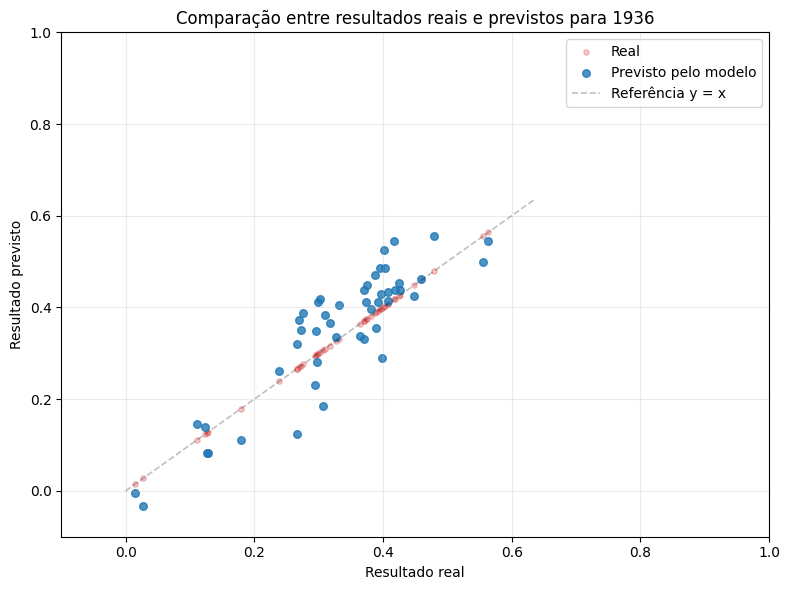

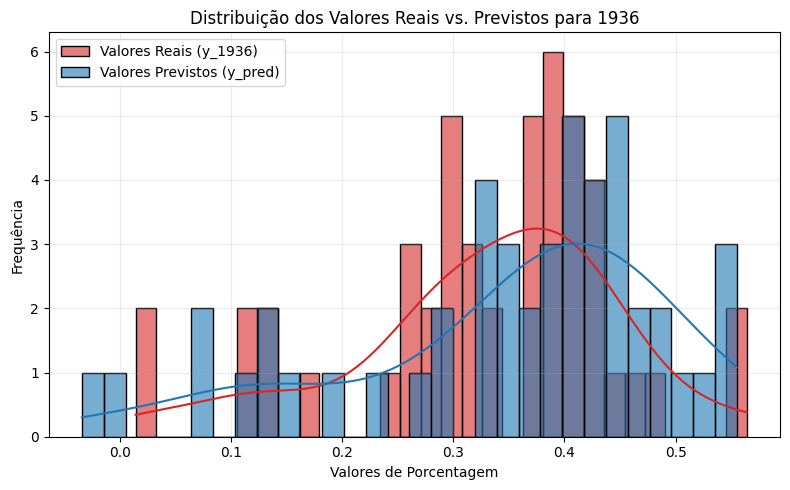

,MAE,RMSE,R2,Média,Desvio-padrão
0,0.05686,0.0683,0.666,0.348635,0.144182


,16,23,30,37,17
param_clf__C,10.0,75.0,100.0,1000.0,10.0
param_clf__gamma,0.01,0.01,0.01,0.01,0.1
split0_test_score,-0.058662,-0.058064,-0.058054,-0.058073,-0.060502
split1_test_score,-0.058759,-0.058779,-0.058784,-0.059264,-0.060201
split2_test_score,-0.083771,-0.085737,-0.086083,-0.087048,-0.088575
split3_test_score,-0.050553,-0.049893,-0.049888,-0.049941,-0.052718
split4_test_score,-0.058163,-0.058037,-0.058032,-0.058194,-0.057084
mean_test_score,-0.061982,-0.062102,-0.062168,-0.062504,-0.063816
rank_test_score,1,2,3,4,5


None

=============== Treinando DECISION_TREE... ===============
Fitting 5 folds for each of 144 candidates, totalling 720 fits
[Pipeline] .............. (step 1 of 2) Processing prep, total=   0.0s
[Pipeline] ............... (step 2 of 2) Processing clf, total=   0.0s
Modelo treinado em 0.22s


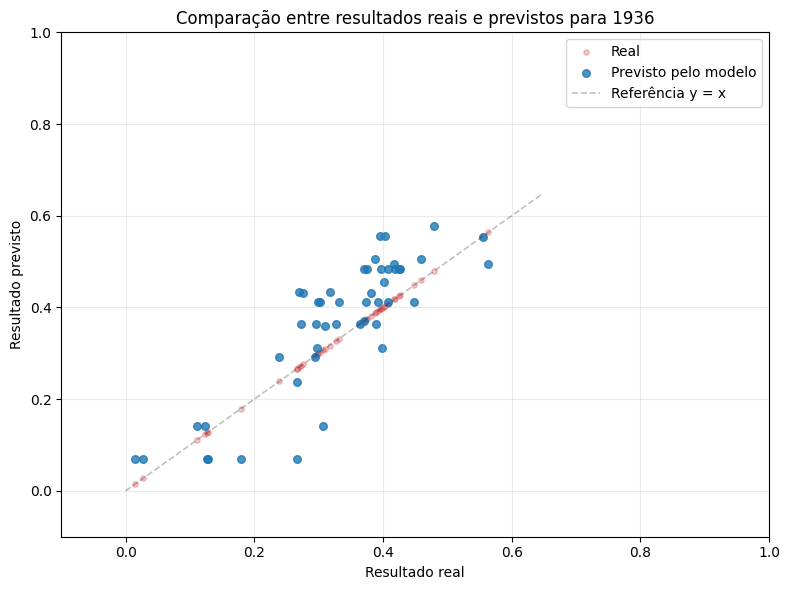

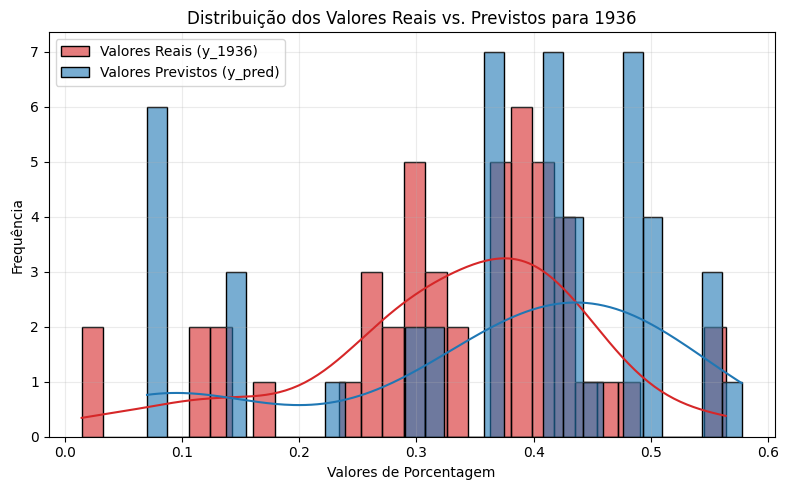

,MAE,RMSE,R2,Média,Desvio-padrão
0,0.071278,0.086461,0.464773,0.365449,0.14955


,51,50,54,55,63
param_clf__criterion,absolute_error,absolute_error,absolute_error,absolute_error,absolute_error
param_clf__max_depth,None,None,None,None,10
param_clf__max_features,None,None,sqrt,sqrt,None
param_clf__min_samples_leaf,4,4,4,4,4
param_clf__min_samples_split,5,2,2,5,5
split0_test_score,-0.070029,-0.070029,-0.070029,-0.070029,-0.070029
split1_test_score,-0.075189,-0.075189,-0.075189,-0.075189,-0.075189
split2_test_score,-0.085718,-0.085718,-0.085718,-0.085718,-0.085718
split3_test_score,-0.056423,-0.056423,-0.056423,-0.056423,-0.056423
split4_test_score,-0.061686,-0.061686,-0.061686,-0.061686,-0.061686


None

=============== Treinando RANDOM_FOREST... ===============
Fitting 5 folds for each of 48 candidates, totalling 240 fits
[Pipeline] .............. (step 1 of 2) Processing prep, total=   0.0s
[Pipeline] ............... (step 2 of 2) Processing clf, total=   0.2s
Modelo treinado em 6.45s


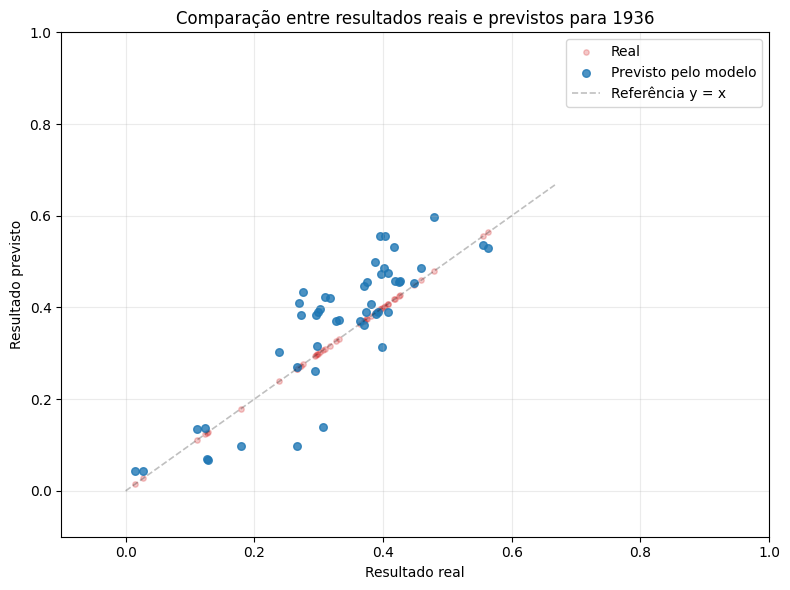

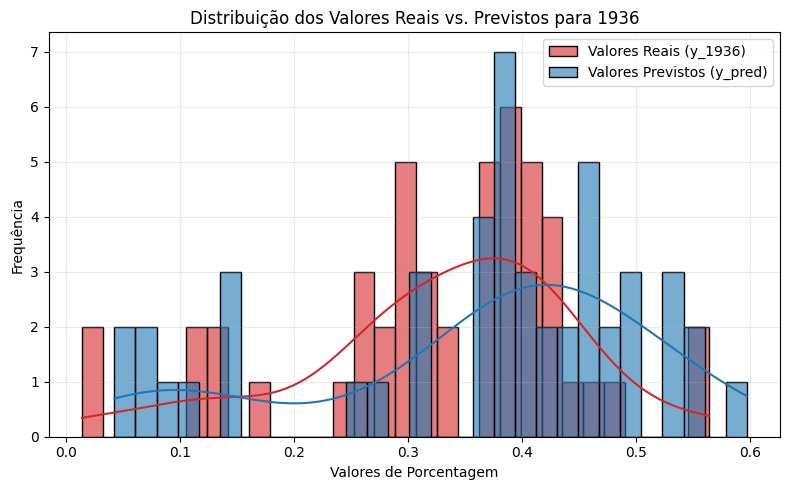

,MAE,RMSE,R2,Média,Desvio-padrão
0,0.064691,0.081369,0.525956,0.363017,0.148626


,23,7,31,15,47
param_clf__max_depth,20,None,20,None,50
param_clf__max_features,sqrt,sqrt,log2,log2,log2
param_clf__min_samples_leaf,2,2,2,2,2
param_clf__min_samples_split,5,5,5,5,5
param_clf__n_estimators,500,500,500,500,500
split0_test_score,-0.069249,-0.069249,-0.069249,-0.069249,-0.069249
split1_test_score,-0.068514,-0.068514,-0.068514,-0.068514,-0.068514
split2_test_score,-0.082252,-0.082252,-0.082252,-0.082252,-0.082252
split3_test_score,-0.051828,-0.051828,-0.051828,-0.051828,-0.051828
split4_test_score,-0.06886,-0.06886,-0.06886,-0.06886,-0.06886


None

=============== Treinando XGBOOST... ===============
Fitting 5 folds for each of 48 candidates, totalling 240 fits
[Pipeline] .............. (step 1 of 2) Processing prep, total=   0.0s


/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [23:55:51] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "cache_size", "predictor" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


[Pipeline] ............... (step 2 of 2) Processing clf, total=   0.2s
Modelo treinado em 2.63s


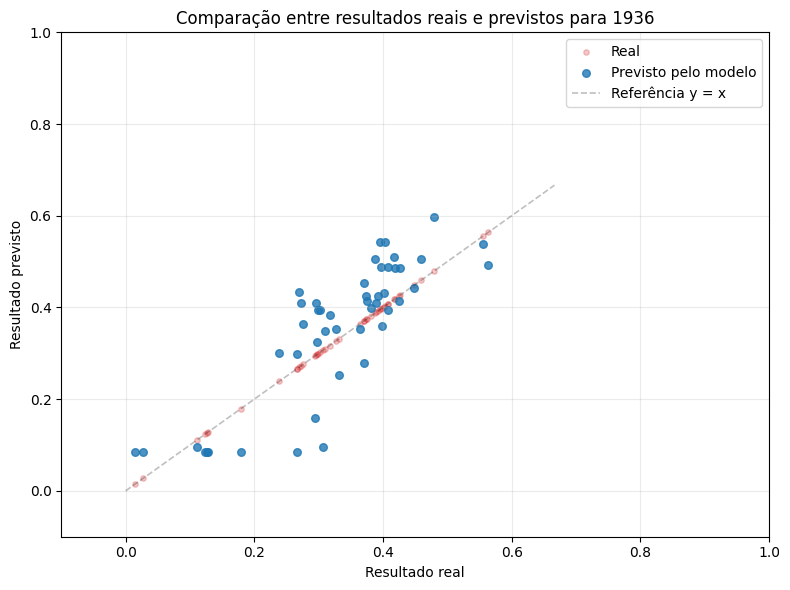

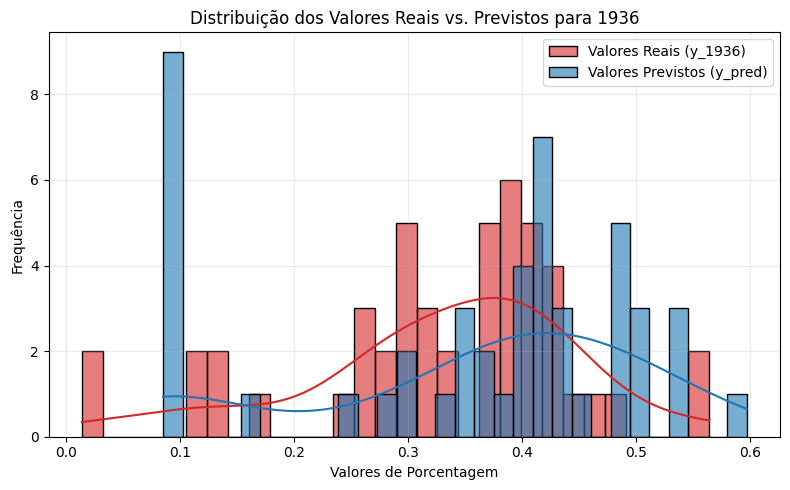

,MAE,RMSE,R2,Média,Desvio-padrão
0,0.070794,0.085576,0.475674,0.354287,0.150543


,3,27,25,1,5
param_clf__colsample_bytree,0.010000,0.100000,0.100000,0.010000,0.010000
param_clf__learning_rate,0.500000,0.500000,0.500000,0.500000,0.500000
param_clf__max_depth,6.000000,6.000000,6.000000,6.000000,10.000000
param_clf__n_estimators,500.000000,500.000000,500.000000,500.000000,500.000000
param_clf__reg_lambda,1.000000,1.000000,0.500000,0.500000,0.500000
param_clf__subsample,1.000000,1.000000,1.000000,1.000000,1.000000
split0_test_score,-0.079749,-0.079749,-0.079867,-0.079867,-0.079915
split1_test_score,-0.075620,-0.075620,-0.075872,-0.075872,-0.075905
split2_test_score,-0.094650,-0.094650,-0.094569,-0.094569,-0.094674
split3_test_score,-0.084483,-0.084483,-0.084121,-0.084121,-0.084405


None

In [ ]:
params_dict: dict[str, tuple] = {
    "svr_linear": (SVR(kernel="linear", cache_size=CACHE), {
        "clf__C": [0.001, 0.01, 0.1, 1, 5, 10, 50, 100],
    }),
    "svr_sigmoid": (SVR(kernel="sigmoid", cache_size=CACHE), {
        "clf__C": [0.25, 0.5, 0.75, 1],
        "clf__coef0": [0, 0.5, 1, 1.5, 2],
        "clf__gamma": [0.01, 0.05, 0.1, 1],
    }),
    "svr_rbf": (SVR(kernel="rbf", cache_size=CACHE), {
        "clf__C": [0.1, 1, 10, 75, 100, 1000],
        "clf__gamma": ["scale", "auto", 0.01, 0.1, 1, 5, 10],
    }),
    "decision_tree": (DecisionTreeRegressor(random_state=RANDOM_STATE), {
        'clf__criterion': ['squared_error', 'absolute_error', 'poisson'],
        'clf__max_depth': [None, 10, 20, 40],
        'clf__max_features': [None, 'sqrt', 'log2'],
        'clf__min_samples_leaf': [2, 4],
        'clf__min_samples_split': [2, 5],
    }),
    "random_forest": (RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=N_JOBS), {
        'clf__max_depth': [None, 20, 50],
        'clf__max_features': ['sqrt', 'log2'],
        'clf__min_samples_leaf': [1, 2],
        'clf__min_samples_split': [2, 5],
        'clf__n_estimators': [200, 500],
    }),
    "xgboost": (XGBRegressor(
        objective='binary:logistic',
        predictor='gpu_predictor',
        eval_metric='mlogloss',
        tree_method='hist',   # fast and Kaggle-friendly
        random_state=RANDOM_STATE,
        n_jobs=N_JOBS,
        cache_size=CACHE,
    ), {
        'clf__colsample_bytree': [0.01, 0.1],
        'clf__learning_rate': [0.5, 1, 2],
        'clf__max_depth': [6, 10],
        'clf__n_estimators': [500],
        'clf__reg_lambda': [0.5, 1.0],
        'clf__subsample': [0.5, 1.0],
    }),
}

# Pré-processamento das colunas numéricas para aplicar escalonamento
preprocessing: ColumnTransformer = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), [0])
    ]
)

cv: KFold = KFold(n_splits=CV_SPLITS, shuffle=True, random_state=RANDOM_STATE)
results: list = []
cv_tables: dict[str, DataFrame] = {}
predictions: dict[str, ndarray[tuple[int], dtype[np.float64]]] = {}

for classifier, (clf, params_grid) in params_dict.items():
    print("=" * 15, f"Treinando {classifier.upper()}...", "=" * 15)

    # Pipeline para pré-processamento
    pipeline = Pipeline([
        ("prep", preprocessing),
        ("clf", clf),
    ], verbose=True)

    # Prepara GridSearchCV com pontuação baseada em erro quadrático médio
    search = GridSearchCV(pipeline, param_grid=params_grid, cv=cv, scoring="neg_root_mean_squared_error", n_jobs=N_JOBS, refit=True, verbose=VERBOSE)

    # Treina e cronometra o modelo
    start = time.monotonic()
    search.fit(x, y)
    elapsed = time.monotonic() - start

    print(f"Modelo treinado em {elapsed:.2f}s")

    # Utiliza o modelo para prever as amostras de teste e apresenta as métricas
    # Previsão de resultados de eleições com amostras e resultados já conhecidos
    y_pred: ndarray[tuple[int], dtype[np.float64]] = search.predict(x_1936)

    # Funções que criam gráficos das previsões comparadas ao resultado real
    scatter_predictions(y_pred)
    histplot_predictions(y_pred)

    cv_tables[classifier] = DataFrame(search.cv_results_).sort_values(by="rank_test_score")
    predictions[classifier] = y_pred

    # Matrizes de confusão são apenas para tarefas de classificação
    # As métricas para tarefas de regressão estão abaixo
    reg_metrics: DataFrame = DataFrame({
      "MAE": [mean_absolute_error(y_1936, y_pred)],
      "RMSE": [np.sqrt(mean_squared_error(y_1936, y_pred))],
      "R2": [r2_score(y_1936, y_pred)],
      "Média": [y_pred.mean()],
      "Desvio-padrão": [y_pred.std()],
    })

    display(
        reg_metrics.head(),
        cv_tables[classifier].drop(columns=["params", "mean_fit_time", "std_fit_time", "mean_score_time", "std_score_time", "std_test_score"])[:5].transpose(),
        # search.best_estimator_,
        plt.show()
    )

    results.append({
        "classifier": classifier,
        "cv_best_score": search.best_score_,
    })

Melhores pontuações de cada modelo, baseadas na média dos erros quadráticos:


,cv_best_score
classifier,
svr_rbf,-0.061982
random_forest,-0.068140
svr_sigmoid,-0.068244
svr_linear,-0.068702
decision_tree,-0.069809
xgboost,-0.090021


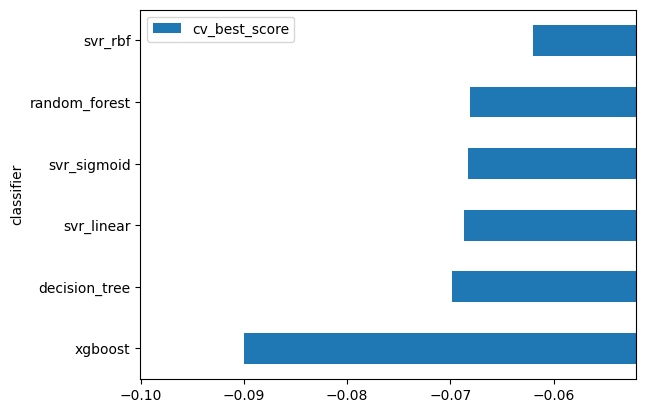

In [ ]:
results_df: DataFrame = DataFrame(results)

print("Melhores pontuações de cada modelo, baseadas na média dos erros quadráticos:")
display(results_df.set_index(keys="classifier").sort_values(by=["cv_best_score"], ascending=False))
results_df.set_index(keys="classifier").sort_values(by=["cv_best_score"], ascending=True).plot(kind="barh").set_xlim(results_df["cv_best_score"].min() - 0.01, results_df["cv_best_score"].max() + 0.01)

plt.show()

In [ ]:
best_predictions: dict[str, dict] = {}

for classifier, predicted in predictions.items():
  print("=" * 15, f"Acertos da regressão {classifier.upper()}", "=" * 15)
  actual_prop_1936: DataFrame = DataFrame([y_1936, predicted]).transpose()
  df_results: DataFrame = DataFrame(
      {
        'state': StatesEnum._member_names_,
        'predicted_winner': ['Republicano' if rep > 0.5 else 'Democrata' for rep in predicted],
        'actual_winner': ['Republicano' if rep > 0.5 else 'Democrata' for rep in y_1936],
      })

  df_results['correct'] = df_results.iloc[:, 1].eq(df_results.iloc[:, 2])
  df_results['predicted'] = predicted * 100
  df_results['actual'] = actual_prop_1936[actual_prop_1936.columns[0]] * 100
  df_results['diff'] = (predicted * 100) - (y_1936 * 100)

  guesses: DataFrame = df_results['correct'].value_counts()

  best_predictions[classifier] = {
    "correct": guesses.values[0],
    "wrong": guesses.values[1],
    "percentage": guesses.values[0] / len(df_results),
    "diff_mean": df_results['diff'].mean(),
    "corrcoef": np.corrcoef(y_1936, predicted)[0, 1],
  }

  display(guesses.to_frame())
  display(df_results["predicted_winner"].value_counts().to_frame().head())
  print(f"\nAcertos:\n{best_predictions[classifier]["percentage"] * 100:.2f}%")
  print(f"\nMédia das diferenças:\n{best_predictions[classifier]["diff_mean"]:.2f}\n")

  correlation_1936 = np.corrcoef(y_1936, predicted)[0, 1]
  print(f"Correlação entre valores reais e previstos para 1936:\n{best_predictions[classifier]["corrcoef"] * 100:.2f}%\n")

  print("Classificações incorretas:")
  display(df_results.sort_values(by=["correct"]).head(guesses.values[1]))


=============== Acertos da regressão SVR_LINEAR ===============


,count
correct,
True,44
False,4


,count
predicted_winner,
Democrata,44
Republicano,4



Acertos:
91.67%

Média das diferenças:
2.93

Correlação entre valores reais e previstos para 1936:
89.24%

Classificações incorretas:


,state,predicted_winner,actual_winner,correct,predicted,actual,diff
18,MASSACHUSETTS,Republicano,Democrata,False,53.479765,41.76,11.719765
16,MAINE,Democrata,Republicano,False,48.677072,55.49,-6.812928
36,RHODE_ISLAND,Republicano,Democrata,False,51.311172,40.18,11.131172
26,NEW_HAMPSHIRE,Republicano,Democrata,False,54.460254,47.98,6.480254


=============== Acertos da regressão SVR_SIGMOID ===============


... (20 outputs left out)

,count
correct,
True,41
False,7


,count
predicted_winner,
Democrata,41
Republicano,7



Acertos:
85.42%

Média das diferenças:
2.52

Correlação entre valores reais e previstos para 1936:
84.15%

Classificações incorretas:


,state,predicted_winner,actual_winner,correct,predicted,actual,diff
26,NEW_HAMPSHIRE,Republicano,Democrata,False,59.672565,47.98,11.692565
42,VERMONT,Democrata,Republicano,False,49.262749,56.39,-7.127251
5,CONNECTICUT,Republicano,Democrata,False,54.231232,40.35,13.881232
19,MICHIGAN,Republicano,Democrata,False,50.532650,38.76,11.772650
18,MASSACHUSETTS,Republicano,Democrata,False,51.008953,41.76,9.248953
27,NEW_JERSEY,Republicano,Democrata,False,54.231232,39.57,14.661232
13,KANSAS,Republicano,Democrata,False,50.532650,45.95,4.582650


In [ ]:
summary = DataFrame(best_predictions).T.astype({
  "correct": np.uint8,
  "wrong": np.uint8,
  "percentage": np.float32,
  "diff_mean": np.float32,
  "corrcoef": np.float32,
})

summary = summary.sort_values(by=["percentage", "diff_mean", "corrcoef"], ascending=[False, True, False])

summary

,correct,wrong,percentage,diff_mean,corrcoef
svr_rbf,44,4,0.916667,1.958665,0.894209
svr_sigmoid,44,4,0.916667,2.848999,0.897632
svr_linear,44,4,0.916667,2.926769,0.892373
random_forest,44,4,0.916667,3.396892,0.870760
decision_tree,42,6,0.875000,3.640104,0.853841
xgboost,41,7,0.854167,2.523884,0.841525


In [ ]:
del actual, actual_prop_1924, actual_prop_1928, actual_prop_1932, actual_prop_1936, ax, axes, best_predictions, classifier, clf, collected_prop_1924, collected_prop_1928, collected_prop_1932, color, colors, comparative_data, correlation_1936, cv, cv_tables, deviation_from_1924, deviation_from_1928, deviation_from_1932, df_results, discarded_lines, elapsed, expected, expected_prop_1924, expected_prop_1928, expected_prop_1932, expected_rep_1924, expected_rep_1928, expected_rep_1932, expected_rep_1936, fig, file_path, guesses, indicated_votes_from_1924, indicated_votes_from_1928, indicated_votes_from_1932, line_max, line_min, params_dict, params_grid, pipeline, predicted, predictions, preprocessing, reg_metrics, relative_scale_1924, relative_scale_1928, relative_scale_1932, rep_1924, rep_1928, rep_1932, rep_1936, rep_total_expected_1924, rep_total_expected_1928, rep_total_expected_1932, rep_votes_from_1924, rep_votes_from_1928, rep_votes_from_1932, results, results_1924, results_1928, results_1932, results_1936, results_df, search, start, summary, total_per_state_1924, total_per_state_1928, total_per_state_1932, total_per_state_1936, total_results_1924, total_results_1928, total_results_1932, votes1924, votes1928, votes1932, votes1936, x_1924, x_1928, x_1932, x_1936, y_1924, y_1928, y_1932, y_1936, y_pred, year

NameError: name 'votes1924' is not defined

# Vinho

In [38]:
# Caminho dos arquivos: tento primeiro na mesma pasta do notebook, depois na pasta Downloads

# Determina o path do arquivo do dataset
caminho_csv = "/kaggle/input/datasets/sergionefedov/wine-price-vs-blind-qualitydo-you-pay-for-taste/"
if not os.path.exists(caminho_csv): caminho_csv = dataset_download("sergionefedov/wine-price-vs-blind-qualitydo-you-pay-for-taste")
# caminho_csv = "."

print(f"Usando arquivo: {caminho_csv}wine_price_vs_blind_quality.csv")  # mostra qual arquivo foi encontrado

# Lê a tabela principal com o pandas (read_csv = "leia o csv")
# df = pd.read_csv(caminho_csv + "wine_price_vs_blind_quality.csv")  # df é o nome que damos para a tabela principal (df = DataFrame)
df = pd.read_csv(caminho_csv + "/wine_price_vs_blind_quality.csv")  # df é o nome que damos para a tabela principal (df = DataFrame)

# Determina o path do caminho do dict
dicionario = pd.read_csv(caminho_csv + "/data_dictionary (2).csv")

# Mostra o tamanho da tabela: (linhas, colunas)
print("\nDimensão da tabela principal (linhas, colunas):", df.shape)

# Mostra as 5 primeiras linhas para espiar os dados
df.head()

Using Colab cache for faster access to the 'wine-price-vs-blind-qualitydo-you-pay-for-taste' dataset.
Usando arquivo: /kaggle/input/wine-price-vs-blind-qualitydo-you-pay-for-tastewine_price_vs_blind_quality.csv

Dimensão da tabela principal (linhas, colunas): (40000, 19)


,wine_id,region,grape,price,vintage_quality,winemaking_score,region_prestige,region_terroir,scarcity,oak_months,residual_sugar,alcohol,true_quality,blind_rating_expert,blind_rating_novice,blind_rating,sighted_rating,overpriced,value_wine
0,WIN000000,generic_new_world,blend,8.59,7.36,1.88,3.0,5.0,4.81,3,5.0,12.7,79.6,79.0,91.8,85.4,79.3,0,1
1,WIN000001,Mendoza,malbec,49.25,3.76,4.76,5.0,6.0,8.67,18,2.1,14.6,78.8,74.7,84.1,79.4,84.0,1,0
2,WIN000002,Tuscany,sangiovese,8.24,7.02,0.18,7.0,7.0,3.60,6,12.9,12.5,80.8,81.0,86.0,83.5,80.1,0,0
3,WIN000003,Tuscany,sangiovese,18.99,7.50,5.40,7.0,7.0,5.70,10,2.8,13.9,85.5,82.9,87.3,85.1,83.7,0,0
4,WIN000004,Mendoza,sangiovese,57.69,2.86,3.92,5.0,6.0,9.85,17,1.0,15.2,76.0,76.7,72.1,74.4,77.8,1,0


In [39]:
# Retorno a quantidade de linhas e colunas do dataframe
print(f"Formato: {df.shape}\n")

# info() retorna nome da coluna, quantidade de valores não-nulos e o tipo (object=texto, float64=número com vírgula, int64=inteiro)
print(df.info())

Formato: (40000, 19)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 19 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   wine_id              40000 non-null  object 
 1   region               40000 non-null  object 
 2   grape                40000 non-null  object 
 3   price                40000 non-null  float64
 4   vintage_quality      40000 non-null  float64
 5   winemaking_score     40000 non-null  float64
 6   region_prestige      40000 non-null  float64
 7   region_terroir       40000 non-null  float64
 8   scarcity             40000 non-null  float64
 9   oak_months           40000 non-null  int64  
 10  residual_sugar       40000 non-null  float64
 11  alcohol              40000 non-null  float64
 12  true_quality         40000 non-null  float64
 13  blind_rating_expert  40000 non-null  float64
 14  blind_rating_novice  40000 non-null  float64
 15  blind_rating  

In [40]:
# Retorno a quantidade de células vazias por coluna
print("Valores faltantes por coluna:")  # isnull() marca True onde está vazio; sum() conta quantos por coluna
print(df.isnull().sum())

# Retorno a quantidade de linhas duplicadas, para verificar se algum vinho é repetido dentre as linhas
print("\nLinhas duplicadas:", df.duplicated().sum())  # duplicated() acha linhas idênticas; sum() conta

Valores faltantes por coluna:
wine_id                0
region                 0
grape                  0
price                  0
vintage_quality        0
winemaking_score       0
region_prestige        0
region_terroir         0
scarcity               0
oak_months             0
residual_sugar         0
alcohol                0
true_quality           0
blind_rating_expert    0
blind_rating_novice    0
blind_rating           0
sighted_rating         0
overpriced             0
value_wine             0
dtype: int64

Linhas duplicadas: 0


In [42]:
# Retorno dados básicos, como quantidade (count), mean (média), std (standard deviation, ou desvio padrão),
# valor mínimo (min), 25%, 50% (mediana), 75%, e o valor máximo
df.describe()

,price,vintage_quality,winemaking_score,region_prestige,region_terroir,scarcity,oak_months,residual_sugar,alcohol,true_quality,blind_rating_expert,blind_rating_novice,blind_rating,sighted_rating,overpriced,value_wine
count,40000.000000,40000.000000,40000.000000,40000.000000,40000.000000,40000.000000,40000.000000,40000.000000,40000.000000,40000.000000,40000.000000,40000.000000,40000.000000,40000.000000,40000.000000,40000.000000
mean,33.472059,5.012889,4.995309,6.328175,6.359500,6.774724,11.994975,3.010625,13.499825,81.997213,82.016500,82.005632,82.011462,82.038508,0.165175,0.104725
std,30.624976,1.982137,1.985396,2.182200,0.932701,2.187676,8.416378,2.457241,1.203876,4.942299,5.434911,4.806245,4.556418,5.495620,0.371343,0.306203
min,4.000000,0.000000,0.000000,3.000000,5.000000,0.000000,0.000000,0.000000,8.500000,70.000000,70.000000,70.000000,70.000000,70.000000,0.000000,0.000000
25%,14.070000,3.670000,3.630000,5.000000,6.000000,5.270000,6.000000,1.200000,12.700000,78.600000,78.200000,78.700000,78.800000,78.200000,0.000000,0.000000
50%,24.490000,5.000000,4.990000,6.000000,6.000000,6.870000,10.000000,2.400000,13.500000,82.000000,82.000000,82.000000,82.000000,82.000000,0.000000,0.000000
75%,42.392500,6.370000,6.340000,8.000000,7.000000,8.500000,16.000000,4.100000,14.300000,85.400000,85.700000,85.300000,85.200000,85.800000,0.000000,0.000000
max,636.080000,10.000000,10.000000,9.000000,8.000000,10.000000,48.000000,22.900000,17.000000,100.000000,100.000000,100.000000,98.400000,100.000000,1.000000,1.000000


In [ ]:
# Retorno a contagem de vinhos por região
print("Contagem por REGIÃO:")  # value_counts() conta quantas vezes cada valor aparece
print(df["region"].value_counts())

# Retorno a contagem de vinhos por uva, mostrando qual uva é mais comum no dataset
print("\nContagem por UVA:")
print(df["grape"].value_counts())

Contagem por REGIÃO:
region
generic_new_world    8799
Bordeaux             5569
Napa                 5279
Rioja                4360
Tuscany              4343
Mendoza              4066
Burgundy             3994
Barossa              3590
Name: count, dtype: int64

Contagem por UVA:
grape
cab_sauv       7138
blend          6697
merlot         4812
pinot_noir     4780
tempranillo    4481
malbec         4091
sangiovese     4027
shiraz         3974
Name: count, dtype: int64


In [ ]:
# Definindo quantos vinhos são overpriced (acima do preço)
print("overpriced (1 = caro e mediano):")  # 0 = preço justo, 1 = pagou pelo rótulo
print(df["overpriced"].value_counts())

# Definindo quantos vinhos são custo-benefício (barato e excelente)
print("\nvalue_wine (1 = barato e ótimo):")  # 0 = não é achado, 1 = achado
print(df["value_wine"].value_counts())

# Retorno também em porcentagem (normalize=True transforma em fração; *100 vira %)
print("\nPorcentagem overpriced:")
print(df["overpriced"].value_counts(normalize=True) * 100)

overpriced (1 = caro e mediano):
overpriced
0    33393
1     6607
Name: count, dtype: int64

value_wine (1 = barato e ótimo):
value_wine
0    35811
1     4189
Name: count, dtype: int64

Porcentagem overpriced:
overpriced
0    83.4825
1    16.5175
Name: proportion, dtype: float64


In [ ]:
# Buscando outliers (valores totalmente fora da média)
print("Maiores preços:")  # nlargest(5, 'price') pega os 5 maiores preços
print(df.nlargest(5, "price")[["wine_id", "region", "price", "blind_rating", "sighted_rating"]])

# Retorno apenas os dados descritos da coluna "price"
print("\nResumo do preço:")
print(df["price"].describe())

Maiores preços:
         wine_id    region   price  blind_rating  sighted_rating
26583  WIN026583  Bordeaux  636.08          77.0            87.2
34563  WIN034563  Burgundy  454.23          81.1            85.2
7586   WIN007586  Bordeaux  453.90          86.6            94.2
21677  WIN021677      Napa  451.76          78.2            87.3
34828  WIN034828  Burgundy  416.65          84.2            91.8

Resumo do preço:
count    40000.000000
mean        33.472059
std         30.624976
min          4.000000
25%         14.070000
50%         24.490000
75%         42.392500
max        636.080000
Name: price, dtype: float64


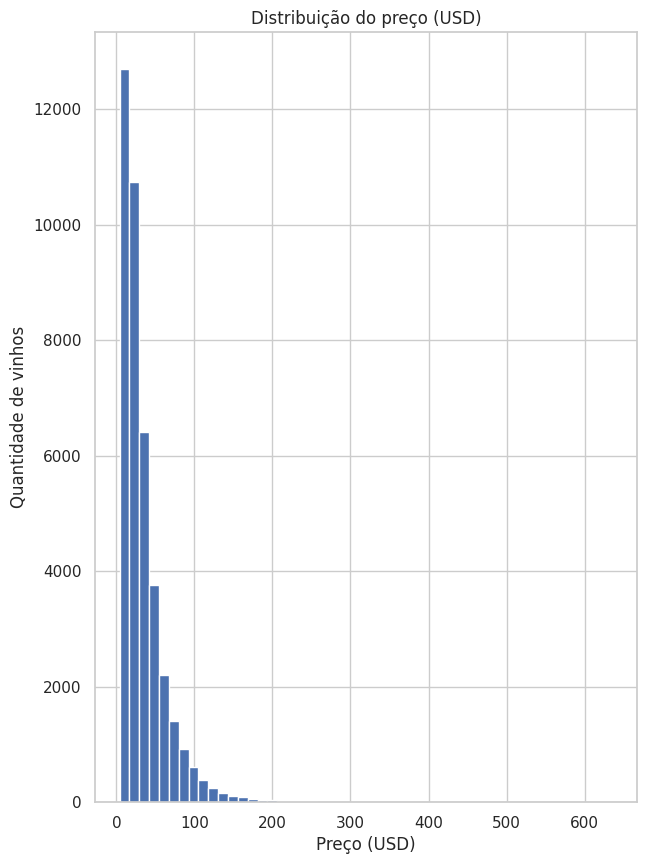

In [ ]:
# Crio um histograma do preço, para entender se a maioria dos vinhos é barato ou caro
plt.figure(figsize=(7,10))  # cria uma figura nova
plt.hist(df["price"], bins=50)  # o comando '.hist()' divide os preços em 50 faixas e conta quantos vinhos caem em cada faixa
plt.title("Distribuição do preço (USD)")  # título do gráfico
plt.xlabel("Preço (USD)")  # nome do eixo x
plt.ylabel("Quantidade de vinhos")  # nome do eixo y
plt.show()  # retorna o gráfico

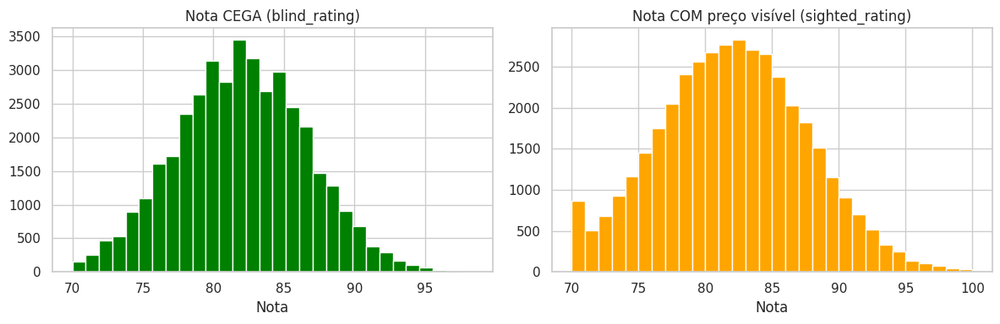

In [43]:
# Crio histogramas que retornam a comparação das notas dos os testadores que viram o preço com as dos testadores que não viram
fig, axes = plt.subplots(1, 2, figsize=(12, 4))  # cria 2 gráficos lado a lado

# Primeiro, criando o histograma dos testadores que não viram o preço
axes[0].hist(df["blind_rating"], bins=30, color="green") # separado em 30 faixas
axes[0].set_title("Nota CEGA (blind_rating)")  # título
axes[0].set_xlabel("Nota")  # título do eixo x

# Depois, criando o histograma dos testadores que viram o preço
axes[1].hist(df["sighted_rating"], bins=30, color="orange")  # também separado em 30 faixas
axes[1].set_title("Nota COM preço visível (sighted_rating)")  # título
axes[1].set_xlabel("Nota")  # título eixo x

plt.tight_layout()  # ajusta o espaço para os gráficos não se sobreporem
plt.show() # retorna os gráficos

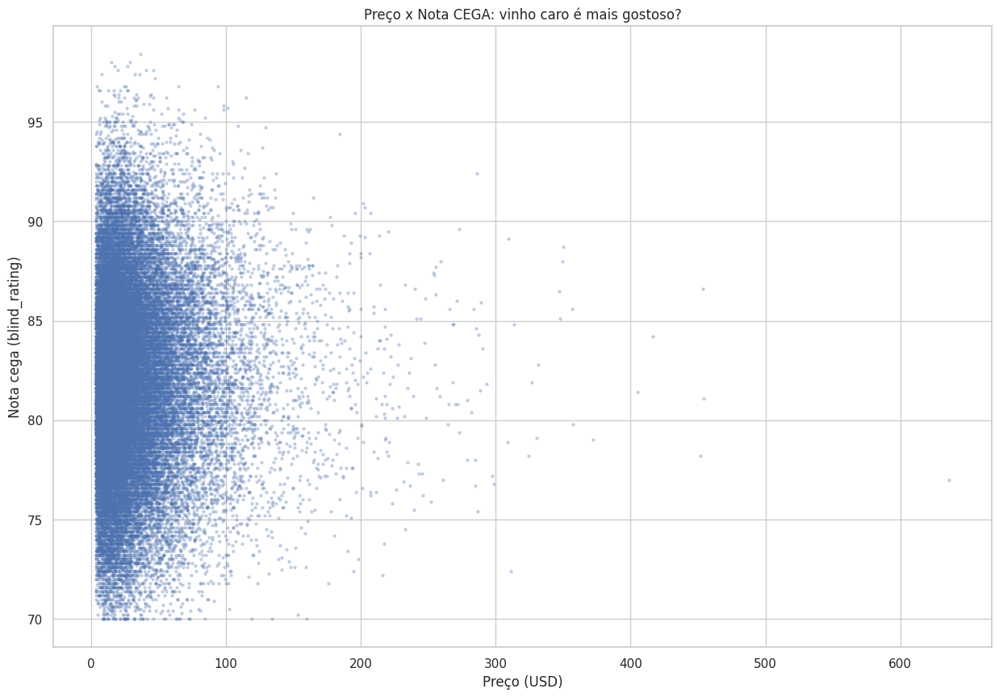

Correlação preço x nota CEGA: 0.03509190773322331
Correlação preço x nota COM preço visível: 0.43158737364467936


In [ ]:
# Gráfico de dispersão, que responderá se o preço prevê corretamente o gosto (dispersão do com preço x sem preço)
plt.figure(figsize=(15,10))  # nova figura
plt.scatter(df["price"], df["blind_rating"], alpha=0.25, s=5)  # scatter = pontos; alpha=0.25 deixa transparente
plt.title("Preço x Nota CEGA: vinho caro é mais gostoso?")  # título
plt.xlabel("Preço (USD)")  # eixo x = preço
plt.ylabel("Nota cega (blind_rating)")  # eixo y = nota honesta
plt.show() # retorna o gráfico dde dispersão

# Calcula a correlação (de -1 a 1): -1 = inversamente proporcional, 0 = sem relação, 1 = diretamente proporcional
print("Correlação preço x nota CEGA:", df["price"].corr(df["blind_rating"]))  # o comando '.corr()' mede a força da relação
print("Correlação preço x nota COM preço visível:", df["price"].corr(df["sighted_rating"]))

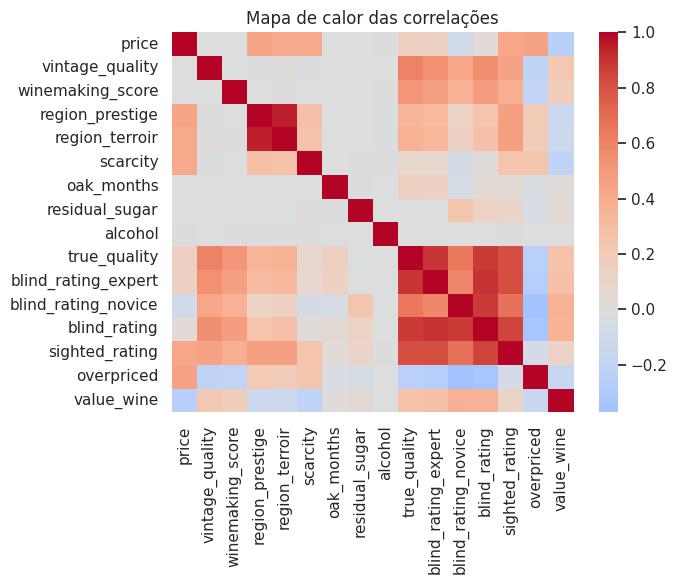

Correlação de cada coluna com blind_rating:
overpriced            -0.346980
alcohol                0.002273
scarcity               0.017916
price                  0.035092
oak_months             0.055308
residual_sugar         0.130582
region_prestige        0.252082
region_terroir         0.273464
value_wine             0.361082
winemaking_score       0.475774
vintage_quality        0.552599
sighted_rating         0.841815
blind_rating_novice    0.874348
true_quality           0.879184
blind_rating_expert    0.903242
blind_rating           1.000000
Name: blind_rating, dtype: float64


In [ ]:
# Mapa de calor (heatmap) das correlações, para verificar o que é relacionado com o que e em qual nível.
colunas_numericas = df.select_dtypes(include="number").columns  # o comando '.select_dtypes' pega só as colunas de números
correlacao = df[colunas_numericas].corr()  # o comando '.corr()' calcula a correlação de cada par de colunas

plt.figure(figsize=(7, 6))  # aumento da figura
heatmap(correlacao, annot=False, cmap="coolwarm", center=0)  # azul = correlação negativa, vermelho = correlação positiva
plt.title("Mapa de calor das correlações")  # título
plt.tight_layout()
plt.show()

# Mostra as correlações ordenadas com a nota cega (do menor para o maior)
print("Correlação de cada coluna com blind_rating:")
print(correlacao["blind_rating"].sort_values())

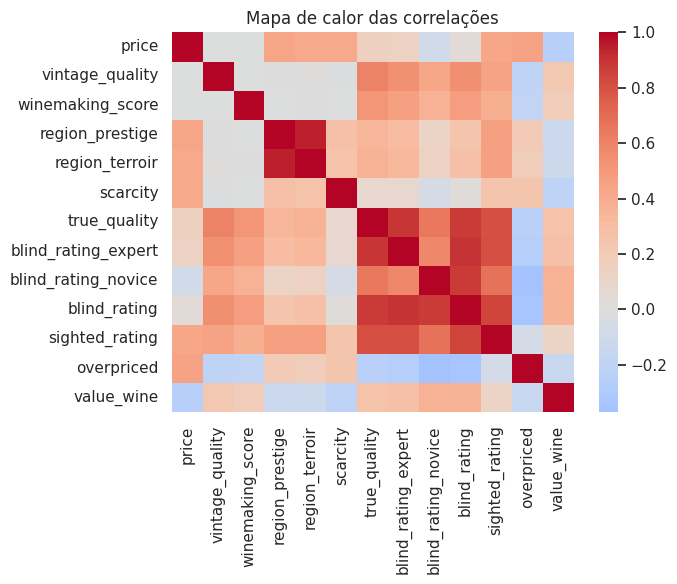

Correlação de cada coluna com blind_rating:
overpriced            -0.346980
scarcity               0.017916
price                  0.035092
region_prestige        0.252082
region_terroir         0.273464
value_wine             0.361082
winemaking_score       0.475774
vintage_quality        0.552599
sighted_rating         0.841815
blind_rating_novice    0.874348
true_quality           0.879184
blind_rating_expert    0.903242
blind_rating           1.000000
Name: blind_rating, dtype: float64


In [ ]:
irrelevant_columns = ["alcohol", "oak_months", "residual_sugar"]

df = df.drop(columns=irrelevant_columns)

# Mapa de calor (heatmap) das correlações, para verificar o que é relacionado com o que e em qual nível.
colunas_numericas = df.select_dtypes(include="number").columns  # o comando '.select_dtypes' pega só as colunas de números
correlacao = df[colunas_numericas].corr()  # o comando '.corr()' calcula a correlação de cada par de colunas

plt.figure(figsize=(7, 6))  # aumento da figura
heatmap(correlacao, annot=False, cmap="coolwarm", center=0)  # azul = correlação negativa, vermelho = correlação positiva
plt.title("Mapa de calor das correlações")  # título
plt.tight_layout()
plt.show()

# Mostra as correlações ordenadas com a nota cega (do menor para o maior)
print("Correlação de cada coluna com blind_rating:")
print(correlacao["blind_rating"].sort_values())

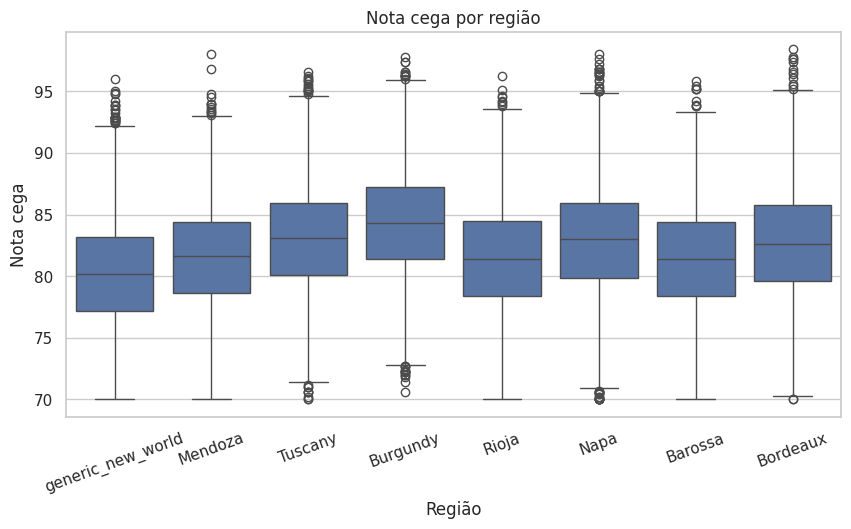

Preço médio por região:
region
Bordeaux             53.088959
Burgundy             52.886748
Napa                 42.790205
Tuscany              34.940449
Barossa              28.768758
Rioja                27.750468
Mendoza              23.286904
generic_new_world    15.389021
Name: price, dtype: float64


In [ ]:
# Criando um boxplot, para verificar se a nota cega se altera dependendo da região
plt.figure(figsize=(10, 5))  # figura mais larga (são 8 regiões)
boxplot(data=df, x="region", y="blind_rating")  # boxplot mostra mediana, quartis e outliers por grupo
plt.title("Nota cega por região")  # título
plt.xlabel("Região")  # eixo x
plt.ylabel("Nota cega")  # eixo y
plt.xticks(rotation=20)  # gira os nomes das regiões para não se sobreporem
plt.show()

# Retornando o preço médio por região, para verificar qual região cobra mais caro
print("Preço médio por região:")
# o comando '.groupby('region')' agrupa por região; '['price'].mean()' tira a média do preço; '.sort_values()' ordena do maior para o menor
print(df.groupby("region")["price"].mean().sort_values(ascending=False))

                price  blind_rating  sighted_rating
overpriced                                         
0           27.428393     82.714692       82.189782
1           64.017866     78.457212       81.273937


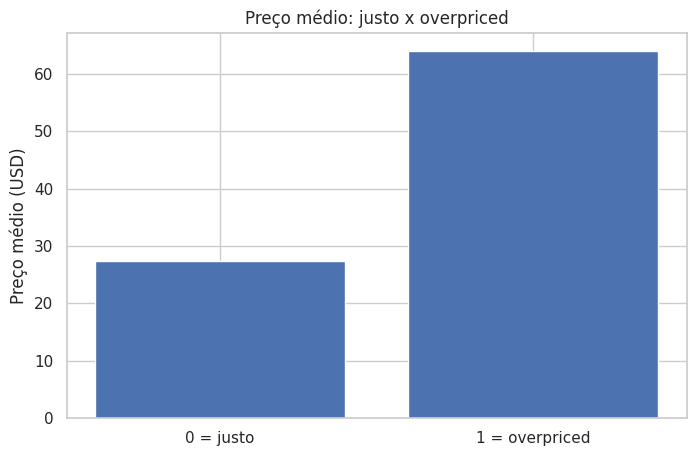

In [ ]:
# Agora, com um gráfico de barras simples, é comparada a média do preço do vinho superfaturado do justo, para verificar se o rótulo engana de fato
# Agrupa pela coluna overpriced (0 = justo, 1 = caro e mediano), e tira a média de preço, nota cega e nota com preço
print(df.groupby("overpriced")[["price", "blind_rating", "sighted_rating"]].mean())

# Criação do gráfico de barras, comparando os preços
medias = df.groupby("overpriced")["price"].mean()  # média de preço por grupo
plt.figure()  # nova figura
plt.bar(["0 = justo", "1 = overpriced"], medias.values)  # o comando '.bar()' faz um gráfico de barras
plt.title("Preço médio: justo x overpriced")  # título
plt.ylabel("Preço médio (USD)")  # título do eixo y
plt.show() # é retornado o gráfico

In [ ]:
# 5.1 Separando X (características = pergunta) e y (resposta = overpriced)
# Primeiro, o X (características) é separado do y (rótulos)
colunas_num = ["price", "vintage_quality", "winemaking_score", "region_prestige",
               "region_terroir", "scarcity", "true_quality", "blind_rating_expert",
               "blind_rating_novice", "blind_rating", "sighted_rating"]  # todas as numéricas úteis
colunas_cat = ["region", "grape"]  # as duas linhas de texto

X = df[colunas_num + colunas_cat]  # X = tudo que o modelo pode olhar
y = df["overpriced"]  # y = a resposta a ser prevista (0 ou 1)

print("Tamanho de X:", X.shape)  # mostra quantas linhas e colunas o modelo vai usar
print("Tamanho de y:", y.shape)  # y tem o mesmo número de linhas
print("\nProporção das classes:")  # retorna o desbalanceamento
print(y.value_counts(normalize=True))

Tamanho de X: (40000, 13)
Tamanho de y: (40000,)

Proporção das classes:
overpriced
0    0.834825
1    0.165175
Name: proportion, dtype: float64


In [ ]:
# Para não sobrecarregar o SVM usando todas as amostras, vou utilizar 1/5 da quantidade das amostras (8000 vinhos)
df_amostra = df.sample(n=len(df.values)//5, random_state=RANDOM_STATE, replace=False)  # o comando '.sample()' sorteia 8000 linhas; e 'random_state=42' fixa o sorteio para repetir igualmente

X = df_amostra[colunas_num + colunas_cat]  # refaz X só com a amostra
y = df_amostra["overpriced"]  # refaz y só com a amostra
print("Amostra para o SVM:", X.shape)  # confirma o novo tamanho

# Agora, dividindo os dados de treino (80%) e os dados de teste (20%)
# 'train_test_split' separa: o modelo aprende no treino, e é avaliado no teste (que ele não tem os dados, para não enviesar)
# 'stratify=y' mantém a proporção de overpriced nos dois grupos; 'random_state=42' mantém o sorteio repetível
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)

# Retorno o tamanho do treino e do teste
print("Treino:", X_train.shape)  # 6400 linhas para aprender
print("Teste:", X_test.shape)  # 1600 linhas para avaliar

Amostra para o SVM: (8000, 13)
Treino: (6400, 13)
Teste: (1600, 13)


In [ ]:
params_dict = {
    "svm_linear": (SVC(kernel="linear", cache_size=CACHE, random_state=RANDOM_STATE), {
        "clf__C": [0.001, 0.01, 0.1, 1, 5, 10],
        "clf__class_weight": [None, "balanced"]
    }),
    "svm_sigmoid": (SVC(kernel="sigmoid", cache_size=CACHE, random_state=RANDOM_STATE), {
        "clf__C": [0.25, 0.5, 0.75, 1],
        "clf__class_weight": [None, "balanced"],
        "clf__coef0": [0, 0.5, 1, 1.5, 2],
        "clf__gamma": [0.01, 0.05, 0.1, 1],
    }),
    "svm_rbf": (SVC(kernel="rbf", cache_size=CACHE, random_state=RANDOM_STATE), {
        "clf__C": [0.1, 1, 10, 75, 100],
        "clf__class_weight": [None],
        "clf__gamma": ["scale", "auto", 0.1, 1, 5, 10],
    }),
    "decision_tree": (DecisionTreeClassifier(random_state=RANDOM_STATE), {
        'clf__class_weight': [None, 'balanced'],
        'clf__criterion': ['gini', 'entropy'],
        'clf__max_depth': [None, 10, 20, 40],
        'clf__max_features': [None, 'sqrt', 'log2'],
        'clf__min_samples_leaf': [2, 4],
        'clf__min_samples_split': [2, 5],
    }),
    "random_forest": (RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=N_JOBS), {
        'clf__class_weight': [None],
        'clf__max_depth': [None, 20, 50],
        'clf__max_features': ['sqrt', 'log2'],
        'clf__min_samples_leaf': [1, 2],
        'clf__min_samples_split': [2, 5],
        'clf__n_estimators': [200, 500],
    }),
    "xgboost": (XGBClassifier(
        objective='binary:logistic',
        predictor='gpu_predictor',
        eval_metric='mlogloss',
        tree_method='hist',   # fast and Kaggle-friendly
        random_state=RANDOM_STATE,
        n_jobs=N_JOBS,
        cache_size=CACHE,
    ), {
        'clf__colsample_bytree': [0.01, 0.1],
        'clf__learning_rate': [0.5, 1, 2],
        'clf__max_depth': [6, 10],
        'clf__n_estimators': [500],
        'clf__reg_lambda': [0.5, 1.0],
        'clf__subsample': [0.5, 1.0],
    }),
}

# Pré-processando os dados e aplicando o modelo SVM dentro de um Pipeline
preprocessamento = ColumnTransformer( # 'ColumnTransformer' aplica 'StandardScaler' nos números e 'OneHotEncoder' nos textos
    transformers=[
        ("num", StandardScaler(), colunas_num),  # padroniza as colunas numéricas
        ("cat", OneHotEncoder(handle_unknown="ignore"), colunas_cat),  # transforma region/grape em colunas 0/1
    ]
)

# Pipeline: primeiro preprocessa, depois treina o SVM (tudo de uma vez, para que não haja vazamento de dados)

def get_cv(clf, param_grid):
  pipeline = Pipeline(steps=[
      ("prep", preprocessamento),  # preparando os dados
      ("clf", clf),
  ], verbose=True)

  return GridSearchCV(
      pipeline,
      param_grid=param_grid,
      cv=CV_SPLITS,
      n_jobs=N_JOBS,
      scoring="accuracy",
      refit=True,
      verbose=VERBOSE,
  )

Treinando modelo SVM_LINEAR...
Fitting 5 folds for each of 12 candidates, totalling 60 fits
[Pipeline] .............. (step 1 of 2) Processing prep, total=   0.0s
[Pipeline] ............... (step 2 of 2) Processing clf, total=   0.1s
Modelos treinados! (3.02s)


,0 = justo,1 = overpriced,accuracy,macro avg,weighted avg
precision,0.913043,0.746193,0.8925,0.829618,0.884992
recall,0.962434,0.546468,0.8925,0.754451,0.892500
f1-score,0.937089,0.630901,0.8925,0.783995,0.885611
support,1331.000000,269.000000,0.8925,1600.000000,1600.000000


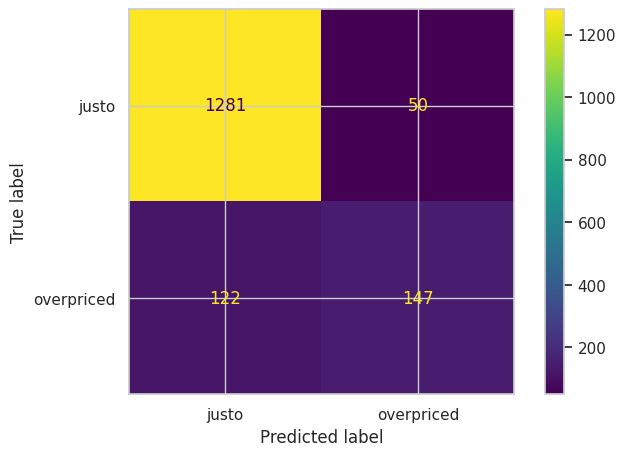

,4,6,10,8,2
param_clf__C,0.1,1.0,10.0,5.0,0.01
param_clf__class_weight,None,None,None,None,None
split0_test_score,0.9,0.898438,0.896094,0.896875,0.895312
split1_test_score,0.903125,0.901563,0.9,0.9,0.900781
split2_test_score,0.883594,0.882031,0.882031,0.882031,0.883594
split3_test_score,0.892188,0.892188,0.892969,0.892188,0.885156
split4_test_score,0.90625,0.907031,0.90625,0.90625,0.900781
mean_test_score,0.897031,0.89625,0.895469,0.895469,0.893125
rank_test_score,1,2,3,4,5


None

Treinando modelo SVM_SIGMOID...
Fitting 5 folds for each of 160 candidates, totalling 800 fits
[Pipeline] .............. (step 1 of 2) Processing prep, total=   0.0s
[Pipeline] ............... (step 2 of 2) Processing clf, total=   0.3s
Modelos treinados! (41.35s)


,0 = justo,1 = overpriced,accuracy,macro avg,weighted avg
precision,0.900914,0.723164,0.88125,0.812039,0.871029
recall,0.963186,0.475836,0.88125,0.719511,0.881250
f1-score,0.931009,0.573991,0.88125,0.752500,0.870986
support,1331.000000,269.000000,0.88125,1600.000000,1600.000000


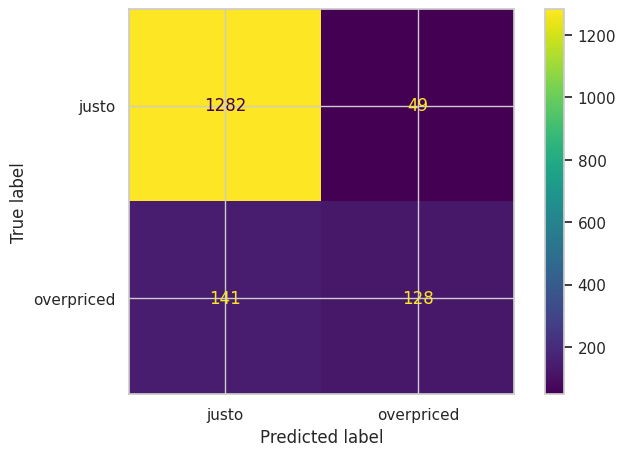

,120,80,40,0,100
param_clf__C,1.0,0.75,0.5,0.25,0.75
param_clf__class_weight,None,None,None,None,balanced
param_clf__coef0,0.0,0.0,0.0,0.0,0.0
param_clf__gamma,0.01,0.01,0.01,0.01,0.01
split0_test_score,0.89375,0.889062,0.889062,0.882031,0.8375
split1_test_score,0.896094,0.896094,0.892969,0.882812,0.846875
split2_test_score,0.874219,0.877344,0.880469,0.878125,0.85
split3_test_score,0.88125,0.878125,0.877344,0.867969,0.857031
split4_test_score,0.895312,0.89375,0.891406,0.879687,0.870313
mean_test_score,0.888125,0.886875,0.88625,0.878125,0.852344


None

Treinando modelo SVM_RBF...
Fitting 5 folds for each of 30 candidates, totalling 150 fits
[Pipeline] .............. (step 1 of 2) Processing prep, total=   0.0s
[Pipeline] ............... (step 2 of 2) Processing clf, total=   0.1s
Modelos treinados! (9.83s)


,0 = justo,1 = overpriced,accuracy,macro avg,weighted avg
precision,0.986446,0.922794,0.975625,0.954620,0.975744
recall,0.984222,0.933086,0.975625,0.958654,0.975625
f1-score,0.985333,0.927911,0.975625,0.956622,0.975679
support,1331.000000,269.000000,0.975625,1600.000000,1600.000000


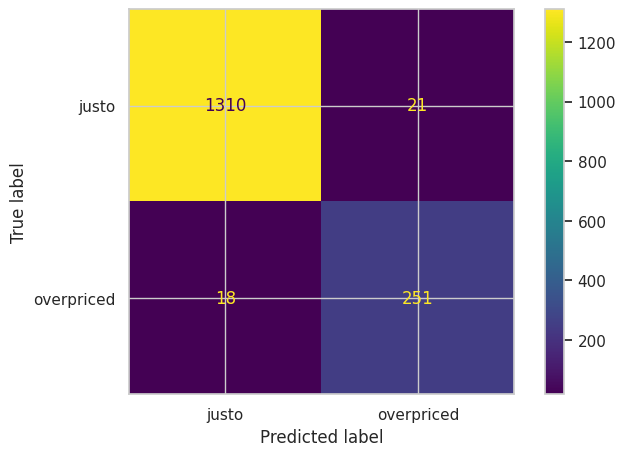

,25,19,13,24,18
param_clf__C,100.0,75.0,10.0,100.0,75.0
param_clf__class_weight,None,None,None,None,None
param_clf__gamma,auto,auto,auto,scale,scale
split0_test_score,0.978906,0.979688,0.979688,0.973437,0.972656
split1_test_score,0.975,0.975781,0.974219,0.971094,0.971094
split2_test_score,0.972656,0.973437,0.967187,0.971094,0.969531
split3_test_score,0.978906,0.975781,0.972656,0.973437,0.973437
split4_test_score,0.978906,0.978906,0.977344,0.974219,0.974219
mean_test_score,0.976875,0.976719,0.974219,0.972656,0.972188
rank_test_score,1,2,3,4,5


None

Treinando modelo DECISION_TREE...
Fitting 5 folds for each of 192 candidates, totalling 960 fits
[Pipeline] .............. (step 1 of 2) Processing prep, total=   0.0s
[Pipeline] ............... (step 2 of 2) Processing clf, total=   0.0s
Modelos treinados! (1.52s)


,0 = justo,1 = overpriced,accuracy,macro avg,weighted avg
precision,1.0,1.0,1.0,1.0,1.0
recall,1.0,1.0,1.0,1.0,1.0
f1-score,1.0,1.0,1.0,1.0,1.0
support,1331.0,269.0,1.0,1600.0,1600.0


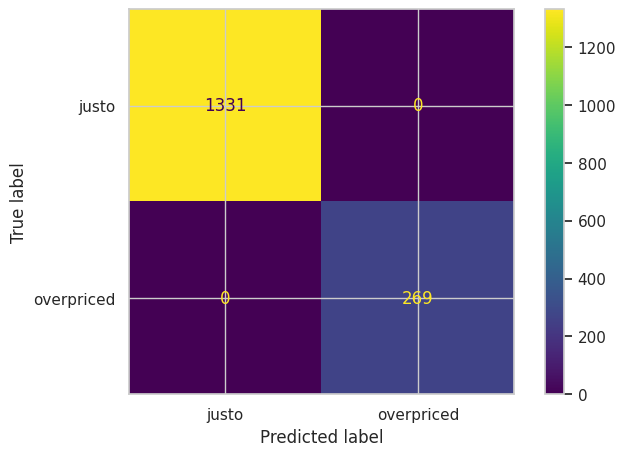

,0,1,2,3,12
param_clf__class_weight,None,None,None,None,None
param_clf__criterion,gini,gini,gini,gini,gini
param_clf__max_depth,None,None,None,None,10
param_clf__max_features,None,None,None,None,None
param_clf__min_samples_leaf,2,2,4,4,2
param_clf__min_samples_split,2,5,2,5,2
split0_test_score,0.999219,0.999219,0.999219,0.999219,0.999219
split1_test_score,1.0,1.0,1.0,1.0,1.0
split2_test_score,1.0,1.0,1.0,1.0,1.0
split3_test_score,1.0,1.0,1.0,1.0,1.0


None

Treinando modelo RANDOM_FOREST...
Fitting 5 folds for each of 48 candidates, totalling 240 fits
[Pipeline] .............. (step 1 of 2) Processing prep, total=   0.0s
[Pipeline] ............... (step 2 of 2) Processing clf, total=   0.2s
Modelos treinados! (10.92s)


,0 = justo,1 = overpriced,accuracy,macro avg,weighted avg
precision,1.0,1.0,1.0,1.0,1.0
recall,1.0,1.0,1.0,1.0,1.0
f1-score,1.0,1.0,1.0,1.0,1.0
support,1331.0,269.0,1.0,1600.0,1600.0


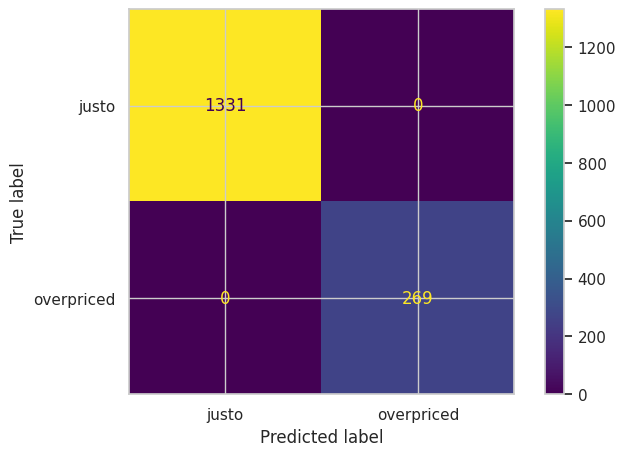

,0,6,22,16,38
param_clf__class_weight,None,None,None,None,None
param_clf__max_depth,None,None,20,20,50
param_clf__max_features,sqrt,sqrt,sqrt,sqrt,sqrt
param_clf__min_samples_leaf,1,2,2,1,2
param_clf__min_samples_split,2,5,5,2,5
param_clf__n_estimators,200,200,200,200,200
split0_test_score,1.0,1.0,1.0,1.0,1.0
split1_test_score,1.0,1.0,1.0,1.0,1.0
split2_test_score,1.0,1.0,1.0,1.0,1.0
split3_test_score,1.0,1.0,1.0,1.0,1.0


None

Treinando modelo XGBOOST...
Fitting 5 folds for each of 48 candidates, totalling 240 fits
[Pipeline] .............. (step 1 of 2) Processing prep, total=   0.0s
[Pipeline] ............... (step 2 of 2) Processing clf, total=   0.2s
Modelos treinados! (4.82s)


/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [00:03:04] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "cache_size", "predictor" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


,0 = justo,1 = overpriced,accuracy,macro avg,weighted avg
precision,1.0,1.0,1.0,1.0,1.0
recall,1.0,1.0,1.0,1.0,1.0
f1-score,1.0,1.0,1.0,1.0,1.0
support,1331.0,269.0,1.0,1600.0,1600.0


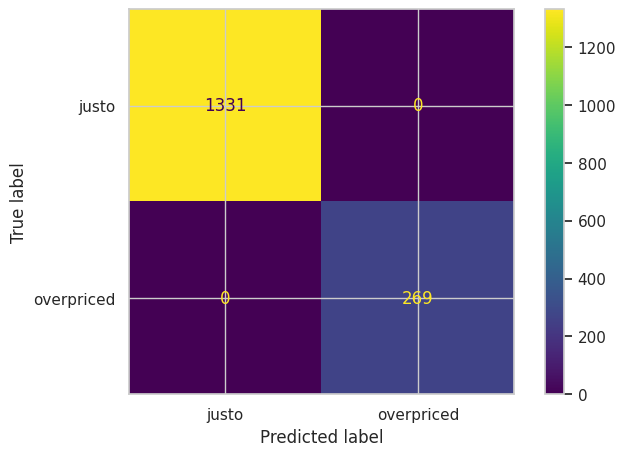

,1,3,6,5,7
param_clf__colsample_bytree,0.010000,0.010000,0.010000,0.010000,0.010000
param_clf__learning_rate,0.500000,0.500000,0.500000,0.500000,0.500000
param_clf__max_depth,6.000000,6.000000,10.000000,10.000000,10.000000
param_clf__n_estimators,500.000000,500.000000,500.000000,500.000000,500.000000
param_clf__reg_lambda,0.500000,1.000000,1.000000,0.500000,1.000000
param_clf__subsample,1.000000,1.000000,0.500000,1.000000,1.000000
split0_test_score,1.000000,1.000000,1.000000,1.000000,1.000000
split1_test_score,1.000000,1.000000,1.000000,1.000000,1.000000
split2_test_score,1.000000,1.000000,1.000000,1.000000,1.000000
split3_test_score,1.000000,1.000000,1.000000,1.000000,1.000000


None

In [30]:
results, cv_tables = [], {}

# Agora, treinando os dados (o comando '.fit()' treina o modelo com os dados de treino,
# fazendo o algoritmo aprender a melhor forma de manter a linha de separação)
for classifier, (clf, param_grid) in params_dict.items():
  print(f"Treinando modelo {classifier.upper()}...")

  start = time.monotonic()
  cv = get_cv(clf, param_grid=param_grid).fit(X_train, y_train)
  elapsed = time.monotonic() - start

  print(f"Modelos treinados! ({elapsed:.2f}s)")

  # Fazendo um teste com o modelo treinado, o comando '.predict() retorna 0 ou 1 para cada vinho do teste
  y_pred = cv.best_estimator_.predict(X_test)

  results.append({
    "kernel": classifier,
    "cv_best_score": cv.best_score_,
  })

  # Relatório de precision (acurácia dos testes de overpriced), recall (acurácia dos overpriced reais) e f1 (média do 'precision' e do 'recall')
  display(pd.DataFrame(classification_report(y_test, y_pred, target_names=["0 = justo", "1 = overpriced"], digits=4, output_dict=True)))

  cv_tables[classifier] = pd.DataFrame(cv.cv_results_).drop(columns=["mean_fit_time", "std_fit_time", "mean_score_time", "std_score_time", "params", "std_test_score"]).sort_values(by="rank_test_score")
  ConfusionMatrixDisplay(confusion_matrix=confusion_matrix(y_test, y_pred), display_labels=["justo", "overpriced"]).plot()

  display(
    cv_tables[classifier][:5].transpose(),
    plt.show()
  )

In [31]:
# Relatório de precision (acurácia dos testes de overpriced), recall (acurácia dos overpriced reais) e f1 (média do 'precision' e do 'recall')
display(pd.DataFrame(classification_report(y_test, y_pred, target_names=["0 = justo", "1 = overpriced"], digits=4, output_dict=True)))

,0 = justo,1 = overpriced,accuracy,macro avg,weighted avg
precision,1.0,1.0,1.0,1.0,1.0
recall,1.0,1.0,1.0,1.0,1.0
f1-score,1.0,1.0,1.0,1.0,1.0
support,1331.0,269.0,1.0,1600.0,1600.0


Melhores pontuações de cada modelo, baseadas em acurácia média das validações cruzadas:


,cv_best_score
kernel,
random_forest,1.000000
decision_tree,0.999844
xgboost,0.999687
svm_rbf,0.976875
svm_linear,0.897031
svm_sigmoid,0.888125


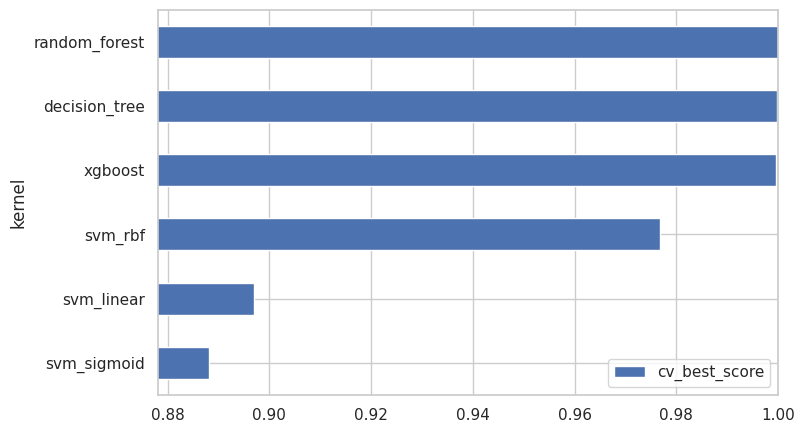

In [32]:
results_df = pd.DataFrame(results)

print("Melhores pontuações de cada modelo, baseadas em acurácia média das validações cruzadas:")
display(results_df.set_index(keys="kernel").sort_values(by=["cv_best_score"], ascending=False))
results_df.set_index(keys="kernel").sort_values(by=["cv_best_score"], ascending=True).plot(kind="barh").set_xlim(results_df["cv_best_score"].min() - 0.01, 1.00)

plt.show()



In [45]:
del X, X_test, X_train, axes, caminho_csv, classifier, clf, colunas_cat, colunas_num, colunas_numericas, correlacao, cv, cv_tables, df, df_amostra, dicionario, elapsed, fig, irrelevant_columns, medias, param_grid, params_dict, preprocessamento, results, results_df, start, y, y_pred, y_test, y_train

# Prova Turma A - Heart Dataset

In [52]:
path = dataset_download("mfarhaannazirkhan/heart-dataset")

df = pd.read_csv(path + "/cleaned_merged_heart_dataset.csv", dtype={
    "sex": np.uint8,
    "fbs": np.uint8,
    "exang": np.uint8,
    "target":np.uint8,
    "chol": np.uint16,
    "age": np.uint8,
    "cp": np.uint8,
    "restecg": np.uint8,
    "thalachh": np.uint8,
    "oldpeak": np.float32,
    "slope": np.uint8,
    "ca": np.uint8,
    "thal": np.uint8,
    "trestbps": np.uint8,
})

display(
    df.head(),
    df.info(),
)

Using Colab cache for faster access to the 'heart-dataset' dataset.
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1888 entries, 0 to 1887
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1888 non-null   uint8  
 1   sex       1888 non-null   uint8  
 2   cp        1888 non-null   uint8  
 3   trestbps  1888 non-null   uint8  
 4   chol      1888 non-null   uint16 
 5   fbs       1888 non-null   uint8  
 6   restecg   1888 non-null   uint8  
 7   thalachh  1888 non-null   uint8  
 8   exang     1888 non-null   uint8  
 9   oldpeak   1888 non-null   float32
 10  slope     1888 non-null   uint8  
 11  ca        1888 non-null   uint8  
 12  thal      1888 non-null   uint8  
 13  target    1888 non-null   uint8  
dtypes: float32(1), uint16(1), uint8(12)
memory usage: 33.3 KB


,age,sex,cp,trestbps,chol,fbs,restecg,thalachh,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


None

In [53]:
TARGET = "target"

df = df.sample(n=len(df)//SPLIT_SAMPLES_BY, random_state=RANDOM_STATE)

x = df.drop(columns=[TARGET])
y = df[TARGET]

display(
    x.shape,
    x,
    y.shape,
    y,
)

(944, 13)

,age,sex,cp,trestbps,chol,fbs,restecg,thalachh,exang,oldpeak,slope,ca,thal
1185,57,1,0,130,131,0,1,115,1,1.2,1,1,3
1054,65,0,2,160,360,0,0,151,0,0.8,2,0,2
1743,76,0,2,140,197,0,2,116,0,1.1,1,0,2
1512,42,0,3,102,265,0,2,122,0,0.6,2,0,3
1460,66,1,3,112,212,0,2,132,1,0.1,1,1,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...
281,52,1,0,128,204,1,1,156,1,1.0,1,0,0
1813,56,1,0,125,249,1,0,144,1,1.2,1,1,2
1124,62,0,0,140,268,0,0,160,0,3.6,0,2,2
1421,54,1,3,124,266,0,2,109,1,2.2,2,1,7


(944,)

,target
1185,0
1054,1
1743,1
1512,0
1460,1
...,...
281,0
1813,0
1124,0
1421,1


<Axes: >

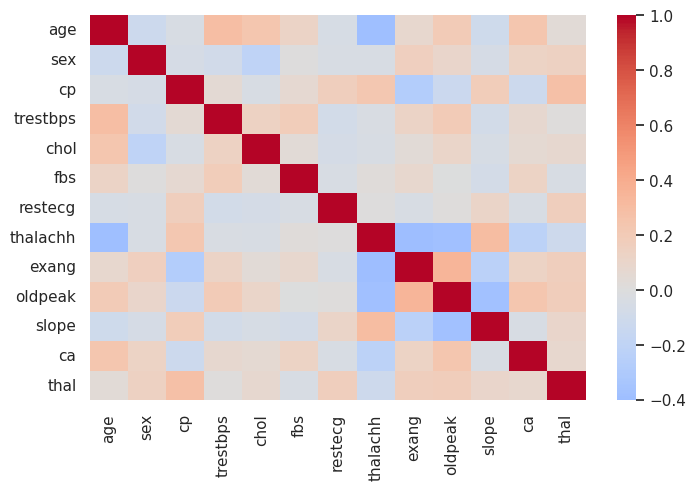

In [54]:
correlation = x.corr()

heatmap(correlation, cmap="coolwarm", center=0)

<Axes: >

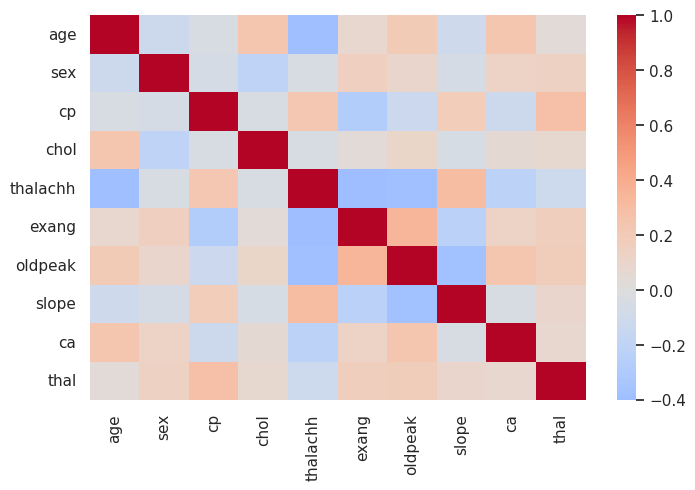

In [55]:
x = x.drop(columns=["restecg", "fbs", "trestbps"])

correlation = x.corr()

heatmap(correlation, cmap="coolwarm", center=0)

In [56]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y)

display(
    x_train.shape,
    x_train.info(),
)

<class 'pandas.core.frame.DataFrame'>
Index: 755 entries, 1847 to 767
Data columns (total 10 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       755 non-null    uint8  
 1   sex       755 non-null    uint8  
 2   cp        755 non-null    uint8  
 3   chol      755 non-null    uint16 
 4   thalachh  755 non-null    uint8  
 5   exang     755 non-null    uint8  
 6   oldpeak   755 non-null    float32
 7   slope     755 non-null    uint8  
 8   ca        755 non-null    uint8  
 9   thal      755 non-null    uint8  
dtypes: float32(1), uint16(1), uint8(8)
memory usage: 16.2 KB


(755, 10)

None

=============== Treinando SVM LINEAR... ===============
Fitting 5 folds for each of 6 candidates, totalling 30 fits
[Pipeline] .............. (step 1 of 2) Processing prep, total=   0.0s
[Pipeline] ............... (step 2 of 2) Processing clf, total=   0.0s
Modelo treinado em 0.63s


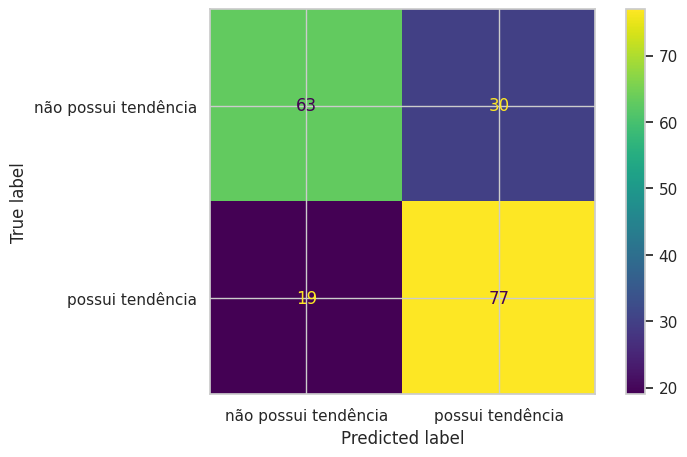

,1,3,5,0,4
mean_fit_time,0.009585,0.03453,0.250346,0.009595,0.222294
std_fit_time,0.001851,0.013426,0.092343,0.001623,0.047727
mean_score_time,0.002122,0.001912,0.001928,0.002123,0.002145
std_score_time,0.000457,0.00015,0.000116,0.000416,0.000269
param_clf__C,1,10,100,1,100
param_clf__class_weight,balanced,balanced,balanced,None,None
params,"{'clf__C': 1, 'clf__class_weight': 'balanced'}","{'clf__C': 10, 'clf__class_weight': 'balanced'}","{'clf__C': 100, 'clf__class_weight': 'balanced'}","{'clf__C': 1, 'clf__class_weight': None}","{'clf__C': 100, 'clf__class_weight': None}"
split0_test_score,0.748344,0.748344,0.748344,0.741722,0.741722
split1_test_score,0.741722,0.741722,0.741722,0.741722,0.741722
split2_test_score,0.728477,0.728477,0.728477,0.735099,0.735099


Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['age', 'sex', 'cp', 'chol',
                                                   'thalachh', 'exang',
                                                   'oldpeak', 'slope', 'ca',
                                                   'thal'])])),
                ('clf',
                 SVC(C=1, cache_size=1000, class_weight='balanced',
                     kernel='linear', random_state=42))],
         verbose=True)

None

=============== Treinando SVM RBF... ===============
Fitting 5 folds for each of 4 candidates, totalling 20 fits
[Pipeline] .............. (step 1 of 2) Processing prep, total=   0.0s
[Pipeline] ............... (step 2 of 2) Processing clf, total=   0.0s
Modelo treinado em 0.05s


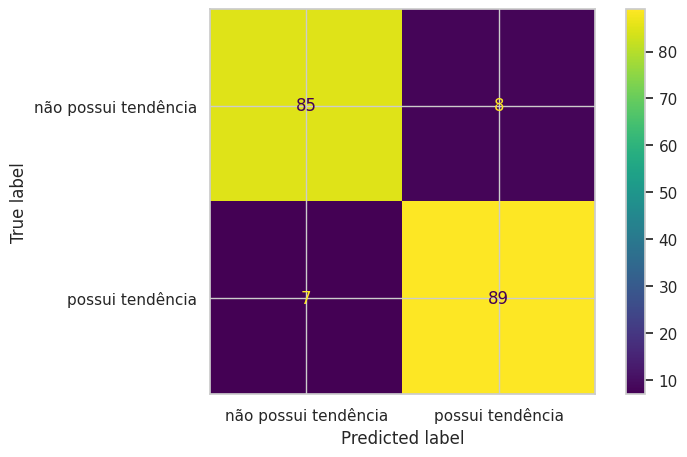

,1,2,3,0
mean_fit_time,0.009083,0.008214,0.008073,0.007743
std_fit_time,0.002064,0.001537,0.001762,0.000321
mean_score_time,0.002622,0.002512,0.00213,0.002161
std_score_time,0.000506,0.000378,0.000145,0.000015
param_clf__C,100,125,200,75
param_clf__class_weight,None,None,None,None
param_clf__gamma,scale,scale,scale,scale
params,"{'clf__C': 100, 'clf__class_weight': None, 'cl...","{'clf__C': 125, 'clf__class_weight': None, 'cl...","{'clf__C': 200, 'clf__class_weight': None, 'cl...","{'clf__C': 75, 'clf__class_weight': None, 'clf..."
split0_test_score,0.940397,0.933775,0.927152,0.92053
split1_test_score,0.89404,0.89404,0.907285,0.900662


Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['age', 'sex', 'cp', 'chol',
                                                   'thalachh', 'exang',
                                                   'oldpeak', 'slope', 'ca',
                                                   'thal'])])),
                ('clf', SVC(C=100, cache_size=1000, random_state=42))],
         verbose=True)

None

=============== Treinando SVM POLY... ===============
Fitting 5 folds for each of 18 candidates, totalling 90 fits
[Pipeline] .............. (step 1 of 2) Processing prep, total=   0.0s
[Pipeline] ............... (step 2 of 2) Processing clf, total=   0.0s
Modelo treinado em 0.16s


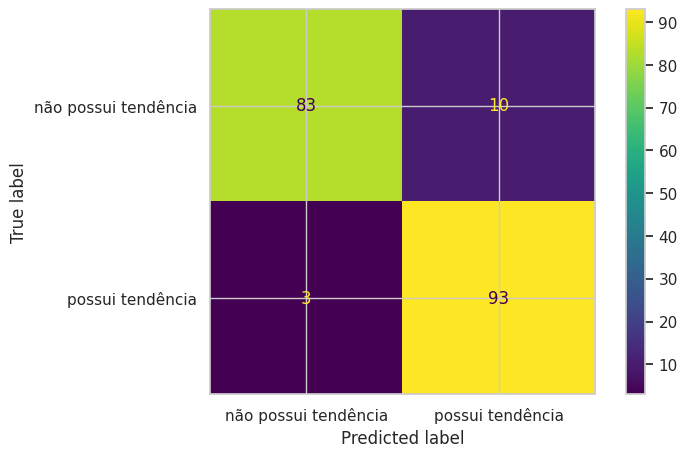

,3,9,15,5,11
mean_fit_time,0.008911,0.008515,0.008023,0.009885,0.008172
std_fit_time,0.001961,0.00103,0.000501,0.002355,0.000577
mean_score_time,0.001911,0.001753,0.001736,0.002096,0.001771
std_score_time,0.000341,0.000051,0.000045,0.000442,0.000059
param_clf__C,1,10,20,1,10
param_clf__class_weight,None,None,None,None,None
param_clf__coef0,3,3,3,4,4
param_clf__gamma,5,5,5,5,5
params,"{'clf__C': 1, 'clf__class_weight': None, 'clf_...","{'clf__C': 10, 'clf__class_weight': None, 'clf...","{'clf__C': 20, 'clf__class_weight': None, 'clf...","{'clf__C': 1, 'clf__class_weight': None, 'clf_...","{'clf__C': 10, 'clf__class_weight': None, 'clf..."
split0_test_score,0.900662,0.900662,0.900662,0.900662,0.900662


Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['age', 'sex', 'cp', 'chol',
                                                   'thalachh', 'exang',
                                                   'oldpeak', 'slope', 'ca',
                                                   'thal'])])),
                ('clf',
                 SVC(C=1, cache_size=1000, coef0=3, gamma=5, kernel='poly',
                     random_state=42))],
         verbose=True)

None

=============== Treinando SVM SIGMOID... ===============
Fitting 5 folds for each of 36 candidates, totalling 180 fits
[Pipeline] .............. (step 1 of 2) Processing prep, total=   0.0s
[Pipeline] ............... (step 2 of 2) Processing clf, total=   0.0s
Modelo treinado em 0.38s


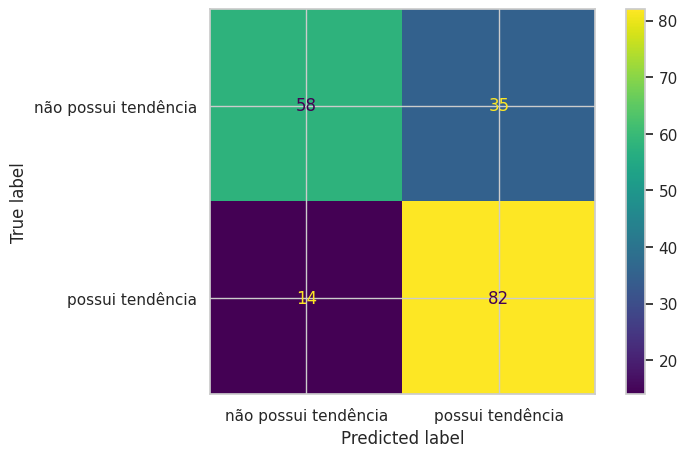

,27,1,24,12,13
mean_fit_time,0.009992,0.009532,0.008009,0.009376,0.007872
std_fit_time,0.000179,0.000102,0.000154,0.000063,0.000139
mean_score_time,0.003231,0.003389,0.002665,0.003086,0.002617
std_score_time,0.000057,0.000254,0.000046,0.000035,0.000027
param_clf__C,10.0,0.1,10.0,1.0,1.0
param_clf__class_weight,None,None,None,None,None
param_clf__coef0,1,0,0,0,0
param_clf__gamma,0.001,0.01,0.001,0.001,0.01
params,"{'clf__C': 10, 'clf__class_weight': None, 'clf...","{'clf__C': 0.1, 'clf__class_weight': None, 'cl...","{'clf__C': 10, 'clf__class_weight': None, 'clf...","{'clf__C': 1, 'clf__class_weight': None, 'clf_...","{'clf__C': 1, 'clf__class_weight': None, 'clf_..."
split0_test_score,0.721854,0.721854,0.715232,0.721854,0.708609


Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['age', 'sex', 'cp', 'chol',
                                                   'thalachh', 'exang',
                                                   'oldpeak', 'slope', 'ca',
                                                   'thal'])])),
                ('clf',
                 SVC(C=10, cache_size=1000, coef0=1, gamma=0.001,
                     kernel='sigmoid', random_state=42))],
         verbose=True)

None

=============== Treinando XGBOOST... ===============
Fitting 5 folds for each of 96 candidates, totalling 480 fits
[Pipeline] .............. (step 1 of 2) Processing prep, total=   0.0s
[Pipeline] ............... (step 2 of 2) Processing clf, total=   0.1s
Modelo treinado em 6.15s


/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [00:06:57] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "cache_size", "predictor" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


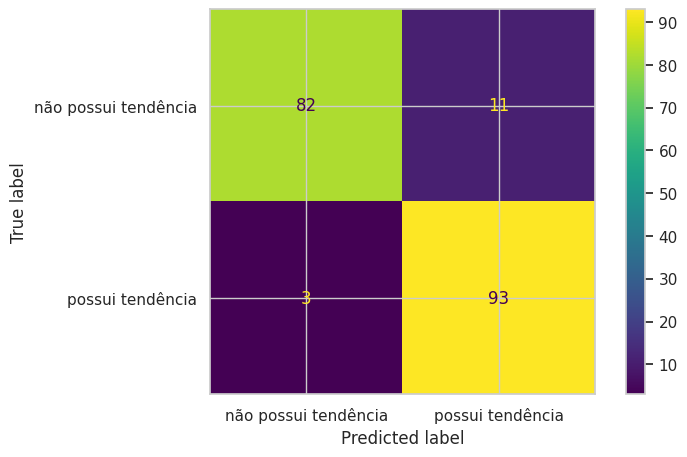

,11,17,15,47,80
mean_fit_time,0.059151,0.064868,0.133261,0.175597,0.060656
std_fit_time,0.000528,0.000747,0.002934,0.031845,0.002896
mean_score_time,0.003051,0.003169,0.00372,0.003721,0.003146
std_score_time,0.00021,0.000049,0.000199,0.000073,0.000089
param_clf__colsample_bytree,0.8,0.8,0.8,0.8,1.0
param_clf__learning_rate,0.1,0.1,0.1,0.05,0.05
param_clf__max_depth,6,8,6,8,6
param_clf__n_estimators,200,200,500,500,200
param_clf__reg_lambda,5.0,1.0,5.0,5.0,1.0
param_clf__subsample,1.0,1.0,1.0,1.0,0.8


Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['age', 'sex', 'cp', 'chol',
                                                   'thalachh', 'exang',
                                                   'oldpeak', 'slope', 'ca',
                                                   'thal'])])),
                ('clf',
                 XGBClassifier(base_score=None, booster=None, cache_size=1000,
                               callbacks=None, colsample_bylevel=None,
                               colsample_bynode=None, colsample_bytree=0.8,
                               device=None, early_stopping_rounds=None,
                               enabl...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.1,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=6, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=200, n_jobs=8, ...))],
         verbose=True)

None

=============== Treinando DECISION TREE... ===============
Fitting 5 folds for each of 432 candidates, totalling 2160 fits
[Pipeline] .............. (step 1 of 2) Processing prep, total=   0.0s
[Pipeline] ............... (step 2 of 2) Processing clf, total=   0.0s
Modelo treinado em 1.24s


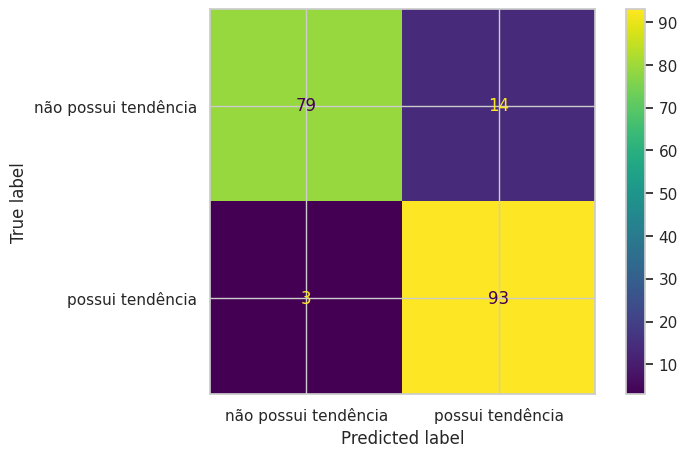

,0,81,54,279,315
mean_fit_time,0.003905,0.003097,0.002909,0.00276,0.002575
std_fit_time,0.000396,0.000182,0.00005,0.000188,0.000029
mean_score_time,0.001598,0.001434,0.001293,0.001331,0.001302
std_score_time,0.000226,0.000108,0.000012,0.000015,0.000016
param_clf__class_weight,None,None,None,balanced,balanced
param_clf__criterion,gini,gini,gini,gini,gini
param_clf__max_depth,None,40,20,20,40
param_clf__max_features,None,None,None,sqrt,log2
param_clf__min_samples_leaf,1,1,1,1,1
param_clf__min_samples_split,2,2,2,2,2


Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['age', 'sex', 'cp', 'chol',
                                                   'thalachh', 'exang',
                                                   'oldpeak', 'slope', 'ca',
                                                   'thal'])])),
                ('clf', DecisionTreeClassifier(random_state=42))],
         verbose=True)

None

=============== Treinando RANDOM FOREST... ===============
Fitting 5 folds for each of 96 candidates, totalling 480 fits
[Pipeline] .............. (step 1 of 2) Processing prep, total=   0.0s
[Pipeline] ............... (step 2 of 2) Processing clf, total=   0.2s
Modelo treinado em 17.13s


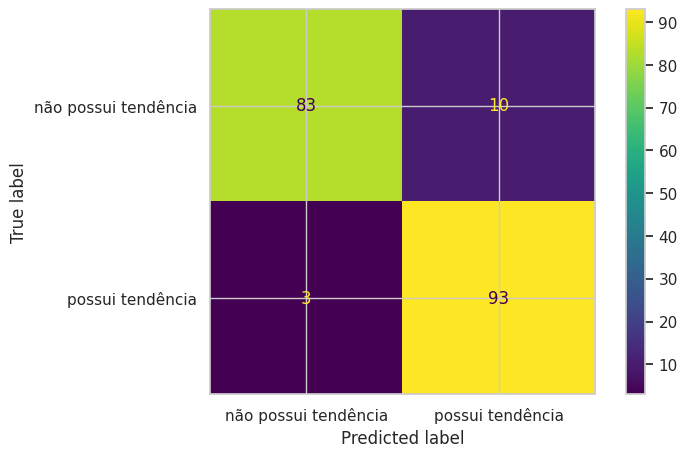

,48,56,80,88,41
mean_fit_time,0.145374,0.14905,0.142568,0.150784,0.339595
std_fit_time,0.007427,0.009032,0.005038,0.009419,0.010983
mean_score_time,0.022445,0.024833,0.022246,0.025005,0.043729
std_score_time,0.004484,0.00027,0.004476,0.000507,0.004433
param_clf__class_weight,balanced,balanced,balanced,balanced,None
param_clf__max_depth,None,None,20,20,20
param_clf__max_features,sqrt,log2,sqrt,log2,log2
param_clf__min_samples_leaf,1,1,1,1,1
param_clf__min_samples_split,2,2,2,2,2
param_clf__n_estimators,200,200,200,200,500


Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['age', 'sex', 'cp', 'chol',
                                                   'thalachh', 'exang',
                                                   'oldpeak', 'slope', 'ca',
                                                   'thal'])])),
                ('clf',
                 RandomForestClassifier(class_weight='balanced',
                                        n_estimators=200, n_jobs=8,
                                        random_state=42))],
         verbose=True)

None

In [57]:
params_dict = {
  "svm linear": (SVC(
      kernel="linear",
      cache_size=CACHE,
      random_state=RANDOM_STATE,
  ), {
        "clf__C": [1, 10, 100],
        "clf__class_weight": [None, "balanced"],
  }),
  "svm rbf": (SVC(
      kernel="rbf",
      cache_size=CACHE,
      random_state=RANDOM_STATE
  ), {
      "clf__C": [75, 100, 125, 200],
      "clf__gamma": ["scale"],
      "clf__class_weight": [None],
  }),
  "svm poly": (SVC(
      kernel="poly",
      cache_size=CACHE,
      random_state=RANDOM_STATE
  ), {
      "clf__C": [1, 10, 20],
      "clf__gamma": [1, 5],
      "clf__coef0": [2, 3, 4],
      "clf__class_weight": [None],
  }),
  "svm sigmoid": (SVC(
      kernel="sigmoid",
      cache_size=CACHE,
      random_state=RANDOM_STATE
  ), {
      "clf__C": [0.1, 1, 10],
      "clf__gamma": [0.001, 0.01, 0.1],
      "clf__coef0": [0, 1],
      "clf__class_weight": [None, "balanced"],
  }),
  "xgboost": (XGBClassifier(
    objective='binary:logistic',
    predictor='gpu_predictor',
    eval_metric='mlogloss',
    random_state=RANDOM_STATE,
    tree_method='hist',   # fast and Kaggle-friendly
    n_jobs=N_JOBS,
    cache_size=CACHE,
  ), {
    'clf__n_estimators': [200, 500],
    'clf__max_depth': [4, 6, 8],
    'clf__learning_rate': [0.1, 0.05],
    'clf__subsample': [0.8, 1.0],
    'clf__colsample_bytree': [0.8, 1.0],
    'clf__reg_lambda': [1.0, 5.0],
  }),
  "decision tree": (DecisionTreeClassifier(
      random_state=RANDOM_STATE,
    ), {
    'clf__criterion': ['gini', 'entropy'],
    'clf__max_depth': [None, 10, 20, 40],
    'clf__min_samples_split': [2, 5, 10],
    'clf__min_samples_leaf': [1, 2, 4],
    'clf__max_features': [None, 'sqrt', 'log2'],
    'clf__class_weight': [None, 'balanced'],
  }),
  "random forest": (RandomForestClassifier(
        random_state=RANDOM_STATE,
        n_jobs=N_JOBS,
    ), {
    'clf__n_estimators': [200, 500],
    'clf__max_depth': [None, 10, 20],
    'clf__min_samples_split': [2, 5],
    'clf__min_samples_leaf': [1, 2],
    'clf__max_features': ['sqrt', 'log2'],
    'clf__class_weight': [None, 'balanced'],
  }),
}

preprocessing = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), list(x.select_dtypes(include=["number"]).columns))
    ]
)

cv = StratifiedKFold(n_splits=CV_SPLITS, shuffle=True, random_state=RANDOM_STATE)
results, cv_tables = [], {}

for classifier, (clf, params_grid) in params_dict.items():
    print("=" * 15, f"Treinando {classifier.upper()}...", "=" * 15)

    pipeline = Pipeline([
        ("prep", preprocessing),
        ("clf", clf),
    ], verbose=True)

    search = GridSearchCV(pipeline,  param_grid=params_grid, cv=cv, scoring="accuracy", n_jobs=N_JOBS, refit=True, verbose=VERBOSE)

    start = time.monotonic()
    search.fit(x_train, y_train)
    elapsed = time.monotonic() - start

    print(f"Modelo treinado em {elapsed:.2f}s")

    y_pred = search.predict(x_test)

    cv_tables[classifier] = pd.DataFrame(search.cv_results_).sort_values(by="rank_test_score")

    ConfusionMatrixDisplay(confusion_matrix=confusion_matrix(y_test, y_pred), display_labels=["não possui tendência", "possui tendência"]).plot()

    display(
        cv_tables[classifier][:5].transpose(),
        search.best_estimator_,
        plt.show()
    )

    results.append({
        "classifier": classifier,
        "cv_best_score": search.best_score_,
    })

In [58]:
results_df = pd.DataFrame(results)

results_df.set_index(keys="classifier").sort_values(by=["cv_best_score"], ascending=False)

,cv_best_score
classifier,
random forest,0.925828
xgboost,0.923179
svm rbf,0.915232
decision tree,0.915232
svm poly,0.901987
svm linear,0.750993
svm sigmoid,0.744371


In [60]:
del classifier, clf, correlation, cv, cv_tables, df, elapsed, params_dict, params_grid, path, pipeline, preprocessing, results, results_df, search, start, x, x_test, x_train, y, y_pred, y_test, y_train

# Prova Turma B - Student Stress Factors

In [66]:
path = dataset_download("rxnach/student-stress-factors-a-comprehensive-analysis")

df = pd.read_csv(path + "/StressLevelDataset.csv", dtype={ # Ao definir previamente os tipos de dados de cada coluna para inteiros positivos de 8 bits, diminui-se o consumo de memória para 30.2 KB
    "anxiety_level": np.uint8,
    "self_esteem": np.uint8,
    "mental_health_history": np.uint8,
    "depression": np.uint8,
    "headache": np.uint8,
    "blood_pressure": np.uint8,
    "sleep_quality": np.uint8,
    "breathing_problem": np.uint8,
    "noise_level": np.uint8,
    "living_conditions": np.uint8,
    "basic_needs": np.uint8,
    "academic_performance": np.uint8,
    "study_load": np.uint8,
    "teacher_student_relationship": np.uint8,
    "future_career_concerns": np.uint8,
    "social_support": np.uint8,
    "peer_pressure": np.uint8,
    "extracurricular_activities": np.uint8,
    "bullying": np.uint8,
    "stress_level": np.uint8,
})

display(
    df.head(),
    df.info(),
    df.describe(),
)

Using Colab cache for faster access to the 'student-stress-factors-a-comprehensive-analysis' dataset.
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1100 entries, 0 to 1099
Data columns (total 21 columns):
 #   Column                        Non-Null Count  Dtype
---  ------                        --------------  -----
 0   anxiety_level                 1100 non-null   uint8
 1   self_esteem                   1100 non-null   uint8
 2   mental_health_history         1100 non-null   uint8
 3   depression                    1100 non-null   uint8
 4   headache                      1100 non-null   uint8
 5   blood_pressure                1100 non-null   uint8
 6   sleep_quality                 1100 non-null   uint8
 7   breathing_problem             1100 non-null   uint8
 8   noise_level                   1100 non-null   uint8
 9   living_conditions             1100 non-null   uint8
 10  safety                        1100 non-null   int64
 11  basic_needs                   1100 non-null  

,anxiety_level,self_esteem,mental_health_history,depression,headache,blood_pressure,sleep_quality,breathing_problem,noise_level,living_conditions,...,basic_needs,academic_performance,study_load,teacher_student_relationship,future_career_concerns,social_support,peer_pressure,extracurricular_activities,bullying,stress_level
0,14,20,0,11,2,1,2,4,2,3,...,2,3,2,3,3,2,3,3,2,1
1,15,8,1,15,5,3,1,4,3,1,...,2,1,4,1,5,1,4,5,5,2
2,12,18,1,14,2,1,2,2,2,2,...,2,2,3,3,2,2,3,2,2,1
3,16,12,1,15,4,3,1,3,4,2,...,2,2,4,1,4,1,4,4,5,2
4,16,28,0,7,2,3,5,1,3,2,...,3,4,3,1,2,1,5,0,5,1


None

,anxiety_level,self_esteem,mental_health_history,depression,headache,blood_pressure,sleep_quality,breathing_problem,noise_level,living_conditions,...,basic_needs,academic_performance,study_load,teacher_student_relationship,future_career_concerns,social_support,peer_pressure,extracurricular_activities,bullying,stress_level
count,1100.000000,1100.000000,1100.000000,1100.000000,1100.000000,1100.000000,1100.000000,1100.000000,1100.000000,1100.000000,...,1100.000000,1100.000000,1100.000000,1100.000000,1100.000000,1100.000000,1100.000000,1100.000000,1100.000000,1100.000000
mean,11.063636,17.777273,0.492727,12.555455,2.508182,2.181818,2.660000,2.753636,2.649091,2.518182,...,2.772727,2.772727,2.621818,2.648182,2.649091,1.881818,2.734545,2.767273,2.617273,0.996364
std,6.117558,8.944599,0.500175,7.727008,1.409356,0.833575,1.548383,1.400713,1.328127,1.119208,...,1.433761,1.414594,1.315781,1.384579,1.529375,1.047826,1.425265,1.417562,1.530958,0.821673
min,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,6.000000,11.000000,0.000000,6.000000,1.000000,1.000000,1.000000,2.000000,2.000000,2.000000,...,2.000000,2.000000,2.000000,2.000000,1.000000,1.000000,2.000000,2.000000,1.000000,0.000000
50%,11.000000,19.000000,0.000000,12.000000,3.000000,2.000000,2.500000,3.000000,3.000000,2.000000,...,3.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.500000,3.000000,1.000000
75%,16.000000,26.000000,1.000000,19.000000,3.000000,3.000000,4.000000,4.000000,3.000000,3.000000,...,4.000000,4.000000,3.000000,4.000000,4.000000,3.000000,4.000000,4.000000,4.000000,2.000000
max,21.000000,30.000000,1.000000,27.000000,5.000000,3.000000,5.000000,5.000000,5.000000,5.000000,...,5.000000,5.000000,5.000000,5.000000,5.000000,3.000000,5.000000,5.000000,5.000000,2.000000


In [67]:
TARGET = "stress_level"

# Embaralha as amostras e as particiona para economia de memória, se necessário
df = df.sample(n=len(df)//SPLIT_SAMPLES_BY, random_state=RANDOM_STATE)

x = df.drop(columns=[TARGET])
y = df[TARGET]

print("Formato das amostras:", x.shape)
print("Formato das rótulos:", y.shape)

print("Amostras:")
display(x)

print("Classes de rótulo:")
display(y.unique())

Formato das amostras: (550, 20)
Formato das rótulos: (550,)
Amostras:


,anxiety_level,self_esteem,mental_health_history,depression,headache,blood_pressure,sleep_quality,breathing_problem,noise_level,living_conditions,safety,basic_needs,academic_performance,study_load,teacher_student_relationship,future_career_concerns,social_support,peer_pressure,extracurricular_activities,bullying
328,21,15,1,26,3,3,1,5,3,1,2,1,2,5,1,5,1,5,5,5
688,3,26,0,1,1,2,5,2,2,3,4,5,4,1,5,1,3,2,1,1
413,11,15,1,9,2,1,2,4,3,3,3,2,3,3,3,2,3,3,2,2
788,10,24,0,12,2,1,2,2,2,3,2,3,3,2,2,2,2,3,2,3
244,6,26,0,3,1,2,4,1,2,4,5,4,4,1,4,1,3,1,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
557,15,11,1,24,4,3,1,4,3,2,2,1,1,3,2,4,1,4,4,5
572,19,0,1,27,5,3,1,5,3,2,1,1,1,4,2,4,1,4,5,4
631,19,13,1,25,3,3,1,3,5,1,1,1,1,3,2,5,1,4,4,4
912,3,27,0,7,1,2,5,2,1,4,5,4,4,2,5,1,3,1,1,1


Classes de rótulo:


array([2, 0, 1], dtype=uint8)

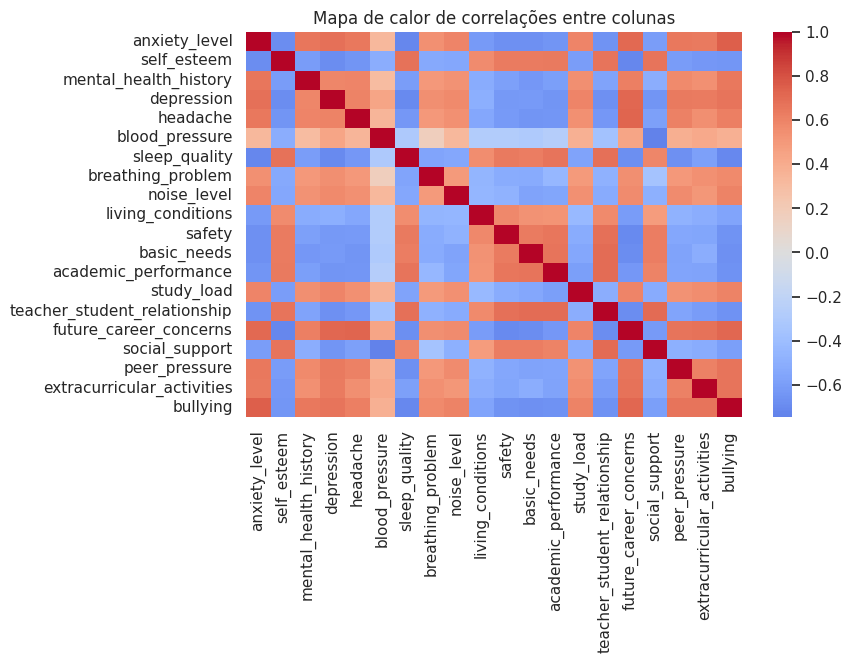

In [68]:
correlation = x.corr()

heatmap(correlation, cmap="coolwarm", center=0)
plt.title("Mapa de calor de correlações entre colunas")
plt.show()

In [69]:
# Divisão de amostras de treino e teste
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y)

display(
    x_train.shape,
    x_train.info(),
)

<class 'pandas.core.frame.DataFrame'>
Index: 440 entries, 413 to 861
Data columns (total 20 columns):
 #   Column                        Non-Null Count  Dtype
---  ------                        --------------  -----
 0   anxiety_level                 440 non-null    uint8
 1   self_esteem                   440 non-null    uint8
 2   mental_health_history         440 non-null    uint8
 3   depression                    440 non-null    uint8
 4   headache                      440 non-null    uint8
 5   blood_pressure                440 non-null    uint8
 6   sleep_quality                 440 non-null    uint8
 7   breathing_problem             440 non-null    uint8
 8   noise_level                   440 non-null    uint8
 9   living_conditions             440 non-null    uint8
 10  safety                        440 non-null    int64
 11  basic_needs                   440 non-null    uint8
 12  academic_performance          440 non-null    uint8
 13  study_load                    440 non-

(440, 20)

None

=============== Treinando SVM_LINEAR... ===============
Fitting 5 folds for each of 12 candidates, totalling 60 fits
[Pipeline] .............. (step 1 of 2) Processing prep, total=   0.0s
[Pipeline] ............... (step 2 of 2) Processing clf, total=   0.0s
Modelo treinado em 0.08s


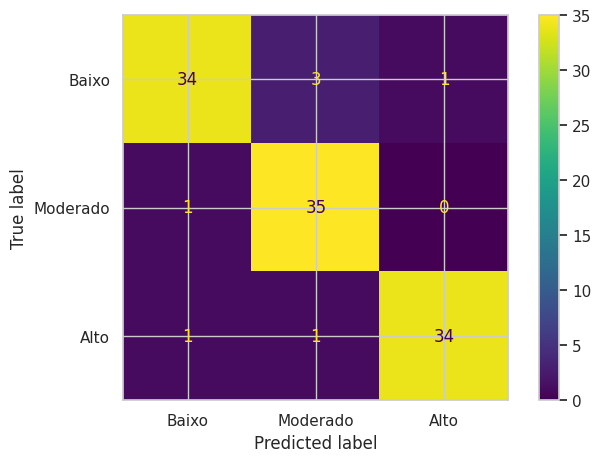

,5,7,9,4,10
param_clf__C,0.1,1.0,5.0,0.1,10.0
param_clf__class_weight,balanced,balanced,balanced,None,None
split0_test_score,0.897727,0.863636,0.897727,0.886364,0.886364
split1_test_score,0.875,0.909091,0.909091,0.875,0.909091
split2_test_score,0.909091,0.886364,0.886364,0.897727,0.886364
split3_test_score,0.886364,0.897727,0.875,0.886364,0.875
split4_test_score,0.897727,0.886364,0.875,0.886364,0.875
mean_test_score,0.893182,0.888636,0.888636,0.886364,0.886364
rank_test_score,1,2,2,4,4


Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['anxiety_level',
                                                   'self_esteem',
                                                   'mental_health_history',
                                                   'depression', 'headache',
                                                   'blood_pressure',
                                                   'sleep_quality',
                                                   'breathing_problem',
                                                   'noise_level',
                                                   'living_conditions',
                                                   'safety', 'basic_needs',
                                                   'academic_performance',
                                                   'study_load',
                                                   'teacher_student_relationship',
                                                   'future_career_concerns',
                                                   'social_support',
                                                   'peer_pressure',
                                                   'extracurricular_activities',
                                                   'bullying'])])),
                ('clf',
                 SVC(C=0.1, cache_size=1000, class_weight='balanced',
                     kernel='linear', random_state=42))],
         verbose=True)

None

=============== Treinando SVM_SIGMOID... ===============
Fitting 5 folds for each of 160 candidates, totalling 800 fits
[Pipeline] .............. (step 1 of 2) Processing prep, total=   0.0s
[Pipeline] ............... (step 2 of 2) Processing clf, total=   0.0s
Modelo treinado em 0.73s


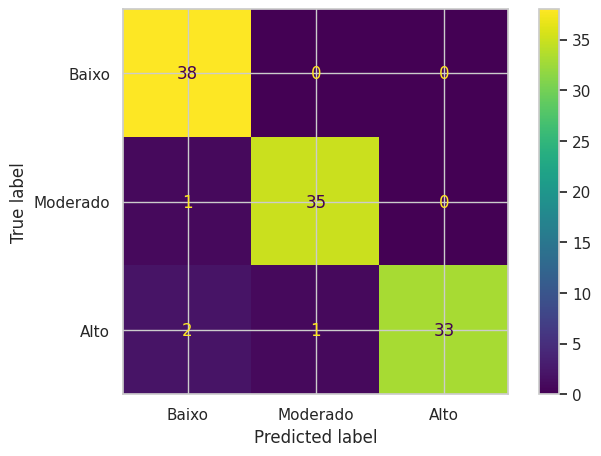

,129,109,52,68,156
param_clf__C,1.0,0.75,0.5,0.5,1.0
param_clf__class_weight,None,balanced,None,balanced,balanced
param_clf__coef0,1.0,1.0,1.5,1.0,2.0
param_clf__gamma,0.05,0.05,0.01,0.01,0.01
split0_test_score,0.886364,0.875,0.909091,0.886364,0.897727
split1_test_score,0.863636,0.863636,0.875,0.863636,0.875
split2_test_score,0.897727,0.886364,0.875,0.897727,0.875
split3_test_score,0.943182,0.954545,0.886364,0.886364,0.897727
split4_test_score,0.886364,0.875,0.897727,0.909091,0.897727
mean_test_score,0.895455,0.890909,0.888636,0.888636,0.888636


Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['anxiety_level',
                                                   'self_esteem',
                                                   'mental_health_history',
                                                   'depression', 'headache',
                                                   'blood_pressure',
                                                   'sleep_quality',
                                                   'breathing_problem',
                                                   'noise_level',
                                                   'living_conditions',
                                                   'safety', 'basic_needs',
                                                   'academic_performance',
                                                   'study_load',
                                                   'teacher_student_relationship',
                                                   'future_career_concerns',
                                                   'social_support',
                                                   'peer_pressure',
                                                   'extracurricular_activities',
                                                   'bullying'])])),
                ('clf',
                 SVC(C=1, cache_size=1000, coef0=1, gamma=0.05,
                     kernel='sigmoid', random_state=42))],
         verbose=True)

None

=============== Treinando SVM_RBF... ===============
Fitting 5 folds for each of 30 candidates, totalling 150 fits
[Pipeline] .............. (step 1 of 2) Processing prep, total=   0.0s
[Pipeline] ............... (step 2 of 2) Processing clf, total=   0.0s
Modelo treinado em 0.16s


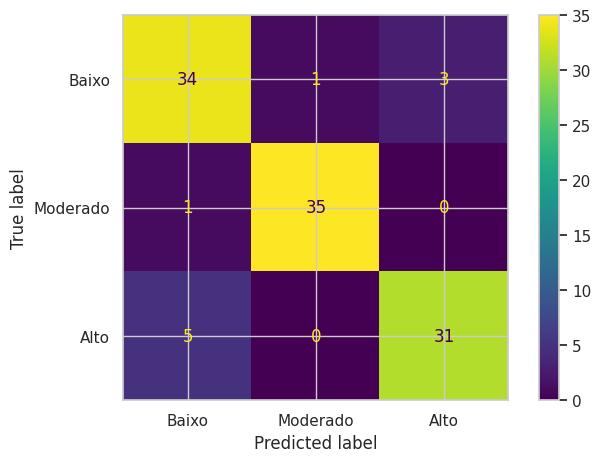

,8,6,7,0,1
param_clf__C,1.0,1.0,1.0,0.1,0.1
param_clf__class_weight,None,None,None,None,None
param_clf__gamma,0.1,scale,auto,scale,auto
split0_test_score,0.852273,0.852273,0.852273,0.875,0.875
split1_test_score,0.886364,0.875,0.875,0.863636,0.863636
split2_test_score,0.909091,0.886364,0.886364,0.875,0.875
split3_test_score,0.886364,0.897727,0.897727,0.875,0.875
split4_test_score,0.875,0.886364,0.886364,0.886364,0.886364
mean_test_score,0.881818,0.879545,0.879545,0.875,0.875
rank_test_score,1,2,2,4,4


Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['anxiety_level',
                                                   'self_esteem',
                                                   'mental_health_history',
                                                   'depression', 'headache',
                                                   'blood_pressure',
                                                   'sleep_quality',
                                                   'breathing_problem',
                                                   'noise_level',
                                                   'living_conditions',
                                                   'safety', 'basic_needs',
                                                   'academic_performance',
                                                   'study_load',
                                                   'teacher_student_relationship',
                                                   'future_career_concerns',
                                                   'social_support',
                                                   'peer_pressure',
                                                   'extracurricular_activities',
                                                   'bullying'])])),
                ('clf', SVC(C=1, cache_size=1000, gamma=0.1, random_state=42))],
         verbose=True)

None

=============== Treinando DECISION_TREE... ===============
Fitting 5 folds for each of 192 candidates, totalling 960 fits
[Pipeline] .............. (step 1 of 2) Processing prep, total=   0.0s
[Pipeline] ............... (step 2 of 2) Processing clf, total=   0.0s
Modelo treinado em 0.54s


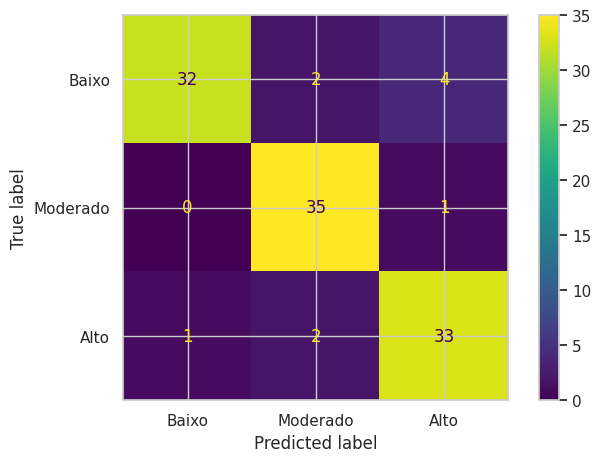

,123,122,99,98,111
param_clf__class_weight,balanced,balanced,balanced,balanced,balanced
param_clf__criterion,gini,gini,gini,gini,gini
param_clf__max_depth,20,20,None,None,10
param_clf__max_features,None,None,None,None,None
param_clf__min_samples_leaf,4,4,4,4,4
param_clf__min_samples_split,5,2,5,2,5
split0_test_score,0.863636,0.863636,0.863636,0.863636,0.863636
split1_test_score,0.897727,0.897727,0.897727,0.897727,0.897727
split2_test_score,0.897727,0.897727,0.897727,0.897727,0.897727
split3_test_score,0.897727,0.897727,0.897727,0.897727,0.897727


Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['anxiety_level',
                                                   'self_esteem',
                                                   'mental_health_history',
                                                   'depression', 'headache',
                                                   'blood_pressure',
                                                   'sleep_quality',
                                                   'breathing_problem',
                                                   'noise_level',
                                                   'living_conditions',
                                                   'safety', 'basic_needs',
                                                   'academic_performance',
                                                   'study_load',
                                                   'teacher_student_relationship',
                                                   'future_career_concerns',
                                                   'social_support',
                                                   'peer_pressure',
                                                   'extracurricular_activities',
                                                   'bullying'])])),
                ('clf',
                 DecisionTreeClassifier(class_weight='balanced',
                                        min_samples_leaf=4, random_state=42))],
         verbose=True)

None

=============== Treinando RANDOM_FOREST... ===============
Fitting 5 folds for each of 48 candidates, totalling 240 fits
[Pipeline] .............. (step 1 of 2) Processing prep, total=   0.0s
[Pipeline] ............... (step 2 of 2) Processing clf, total=   0.1s
Modelo treinado em 8.16s


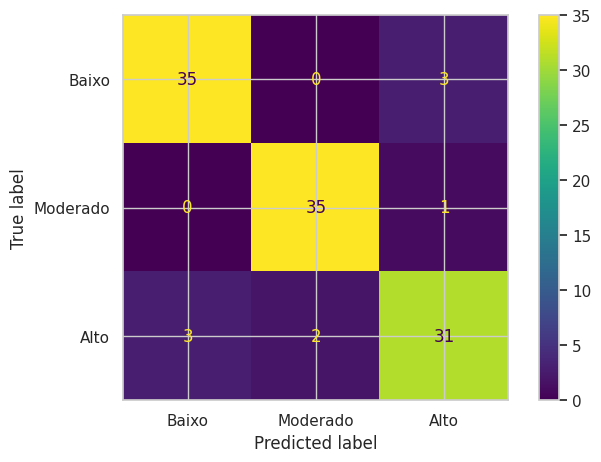

,2,10,26,18,42
param_clf__class_weight,None,None,None,None,None
param_clf__max_depth,None,None,20,20,50
param_clf__max_features,sqrt,log2,log2,sqrt,log2
param_clf__min_samples_leaf,1,1,1,1,1
param_clf__min_samples_split,5,5,5,5,5
param_clf__n_estimators,200,200,200,200,200
split0_test_score,0.863636,0.863636,0.863636,0.863636,0.863636
split1_test_score,0.875,0.875,0.875,0.875,0.875
split2_test_score,0.886364,0.886364,0.886364,0.886364,0.886364
split3_test_score,0.897727,0.897727,0.897727,0.897727,0.897727


Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['anxiety_level',
                                                   'self_esteem',
                                                   'mental_health_history',
                                                   'depression', 'headache',
                                                   'blood_pressure',
                                                   'sleep_quality',
                                                   'breathing_problem',
                                                   'noise_level',
                                                   'living_conditions',
                                                   'safety', 'basic_needs',
                                                   'academic_performance',
                                                   'study_load',
                                                   'teacher_student_relationship',
                                                   'future_career_concerns',
                                                   'social_support',
                                                   'peer_pressure',
                                                   'extracurricular_activities',
                                                   'bullying'])])),
                ('clf',
                 RandomForestClassifier(min_samples_split=5, n_estimators=200,
                                        n_jobs=8, random_state=42))],
         verbose=True)

None

=============== Treinando XGBOOST... ===============
Fitting 5 folds for each of 48 candidates, totalling 240 fits
[Pipeline] .............. (step 1 of 2) Processing prep, total=   0.0s
[Pipeline] ............... (step 2 of 2) Processing clf, total=   0.1s
Modelo treinado em 4.30s


/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [00:08:55] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "cache_size", "predictor" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


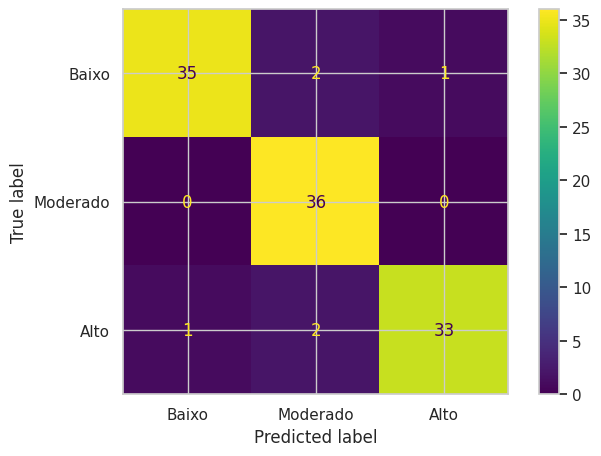

,22,18,28,24,26
param_clf__colsample_bytree,0.010000,0.010000,0.100000,0.100000,0.100000
param_clf__learning_rate,2.000000,2.000000,0.500000,0.500000,0.500000
param_clf__max_depth,10.000000,6.000000,10.000000,6.000000,6.000000
param_clf__n_estimators,500.000000,500.000000,500.000000,500.000000,500.000000
param_clf__reg_lambda,1.000000,1.000000,0.500000,0.500000,1.000000
param_clf__subsample,0.500000,0.500000,0.500000,0.500000,0.500000
split0_test_score,0.897727,0.897727,0.897727,0.886364,0.875000
split1_test_score,0.909091,0.909091,0.897727,0.886364,0.886364
split2_test_score,0.931818,0.931818,0.886364,0.909091,0.909091
split3_test_score,0.886364,0.886364,0.931818,0.909091,0.920455


Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['anxiety_level',
                                                   'self_esteem',
                                                   'mental_health_history',
                                                   'depression', 'headache',
                                                   'blood_pressure',
                                                   'sleep_quality',
                                                   'breathing_problem',
                                                   'noise_level',
                                                   'living_conditions',
                                                   'safety', 'basic_needs',
                                                   'academic_performance',
                                                   'study_load',
                                                   'teacher_student_relationship',
                                                   'future_career...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=2,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=6, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=500, n_jobs=8, ...))],
         verbose=True)

None

In [70]:
params_dict = {
    "svm_linear": (SVC(kernel="linear", cache_size=CACHE, random_state=RANDOM_STATE), {
        "clf__C": [0.001, 0.01, 0.1, 1, 5, 10],
        "clf__class_weight": [None, "balanced"]
    }),
    "svm_sigmoid": (SVC(kernel="sigmoid", cache_size=CACHE, random_state=RANDOM_STATE), {
        "clf__C": [0.25, 0.5, 0.75, 1],
        "clf__class_weight": [None, "balanced"],
        "clf__coef0": [0, 0.5, 1, 1.5, 2],
        "clf__gamma": [0.01, 0.05, 0.1, 1],
    }),
    "svm_rbf": (SVC(kernel="rbf", cache_size=CACHE, random_state=RANDOM_STATE), {
        "clf__C": [0.1, 1, 10, 75, 100],
        "clf__class_weight": [None],
        "clf__gamma": ["scale", "auto", 0.1, 1, 5, 10],
    }),
    "decision_tree": (DecisionTreeClassifier(random_state=RANDOM_STATE), {
        'clf__class_weight': [None, 'balanced'],
        'clf__criterion': ['gini', 'entropy'],
        'clf__max_depth': [None, 10, 20, 40],
        'clf__max_features': [None, 'sqrt', 'log2'],
        'clf__min_samples_leaf': [2, 4],
        'clf__min_samples_split': [2, 5],
    }),
    "random_forest": (RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=N_JOBS), {
        'clf__class_weight': [None],
        'clf__max_depth': [None, 20, 50],
        'clf__max_features': ['sqrt', 'log2'],
        'clf__min_samples_leaf': [1, 2],
        'clf__min_samples_split': [2, 5],
        'clf__n_estimators': [200, 500],
    }),
    "xgboost": (XGBClassifier(
        objective='binary:logistic',
        predictor='gpu_predictor',
        eval_metric='mlogloss',
        tree_method='hist',   # fast and Kaggle-friendly
        random_state=RANDOM_STATE,
        n_jobs=N_JOBS,
        cache_size=CACHE,
    ), {
        'clf__colsample_bytree': [0.01, 0.1],
        'clf__learning_rate': [0.5, 1, 2],
        'clf__max_depth': [6, 10],
        'clf__n_estimators': [500],
        'clf__reg_lambda': [0.5, 1.0],
        'clf__subsample': [0.5, 1.0],
    }),
}

# Pré-processamento das colunas numéricas para aplicar escalonamento
preprocessing = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), list(x.select_dtypes(include=["number"]).columns))
    ]
)

cv = StratifiedKFold(n_splits=CV_SPLITS, shuffle=True, random_state=RANDOM_STATE)
results, cv_tables = [], {}

for classifier, (clf, params_grid) in params_dict.items():
    print("=" * 15, f"Treinando {classifier.upper()}...", "=" * 15)

    # Pipeline para pré-processamento
    pipeline = Pipeline([
        ("prep", preprocessing),
        ("clf", clf),
    ], verbose=True)

    # Prepara GridSearchCV com pontuação baseada em acurácia
    search = GridSearchCV(pipeline,  param_grid=params_grid, cv=cv, scoring="accuracy", n_jobs=N_JOBS, refit=True, verbose=VERBOSE)

    # Treina e cronometra o modelo
    start = time.monotonic()
    search.fit(x_train, y_train)
    elapsed = time.monotonic() - start

    print(f"Modelo treinado em {elapsed:.2f}s")

    # Utiliza o modelo para prever as amostras de teste e apresenta as métricas
    y_pred = search.predict(x_test)

    cv_tables[classifier] = pd.DataFrame(search.cv_results_).sort_values(by="rank_test_score")
    ConfusionMatrixDisplay(confusion_matrix=confusion_matrix(y_test, y_pred), display_labels=["Baixo", "Moderado", "Alto"]).plot()

    display(
        cv_tables[classifier].drop(columns=["params", "mean_fit_time", "std_fit_time", "mean_score_time", "std_score_time", "std_test_score"])[:5].transpose(),
        search.best_estimator_,
        plt.show()
    )

    results.append({
        "classifier": classifier,
        "cv_best_score": search.best_score_,
    })

In [71]:
results_df = pd.DataFrame(results)

print("Melhores pontuações de cada modelo, baseadas em acurácia média das validações cruzadas:")
results_df.set_index(keys="classifier").sort_values(by=["cv_best_score"], ascending=False)

Melhores pontuações de cada modelo, baseadas em acurácia média das validações cruzadas:


,cv_best_score
classifier,
xgboost,0.906818
svm_sigmoid,0.895455
svm_linear,0.893182
decision_tree,0.888636
random_forest,0.886364
svm_rbf,0.881818


In [72]:
del classifier, clf, correlation, cv, cv_tables, df, elapsed, params_dict, params_grid, path, pipeline, preprocessing, results, results_df, search, start, x, x_test, x_train, y, y_pred, y_test, y_train

# Breast Cancer Dataset

In [73]:
path = dataset_download("uciml/breast-cancer-wisconsin-data")

data = pd.read_csv(path + "/data.csv")
# data = pd.read_csv('/kaggle/input/datasets/uciml/breast-cancer-wisconsin-data/data.csv')
# data = pd.read_csv('../data.csv', index_col=0)

data = data.dropna(how='all',axis='columns')

data.head()

Using Colab cache for faster access to the 'breast-cancer-wisconsin-data' dataset.


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [74]:
TARGET = "diagnosis"

x = data.drop(columns=[TARGET])
y = data[TARGET]

x.head()

,id,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,842302,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


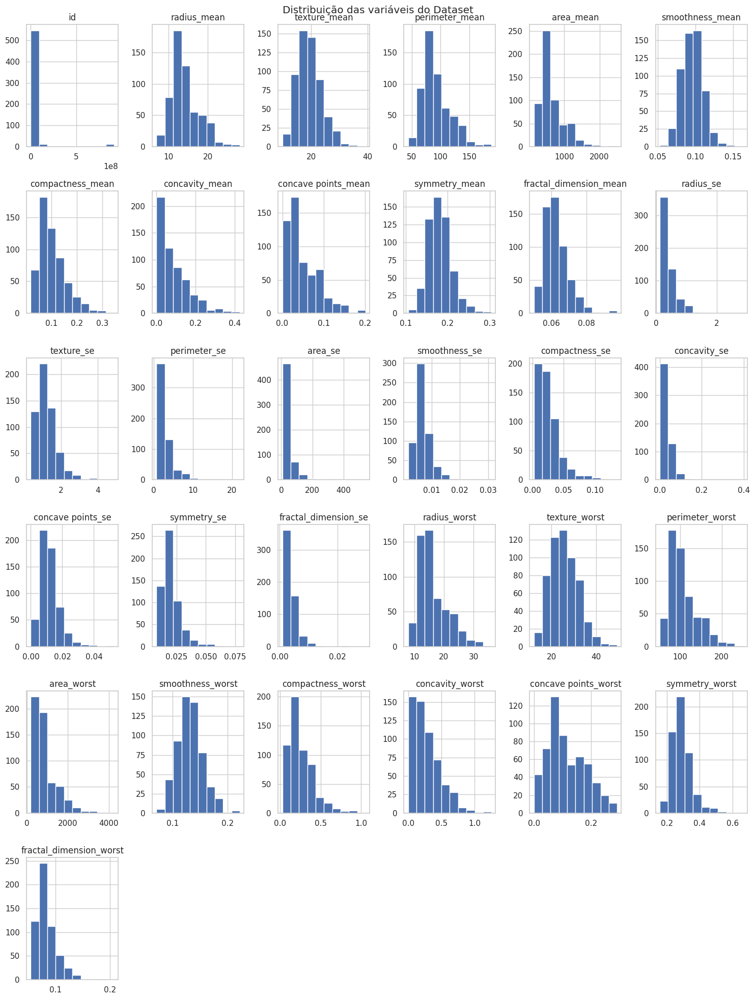

In [75]:
x[x.columns].hist(figsize=(15, 20))
plt.suptitle("Distribuição das variáveis do Dataset")
plt.tight_layout()
plt.show()

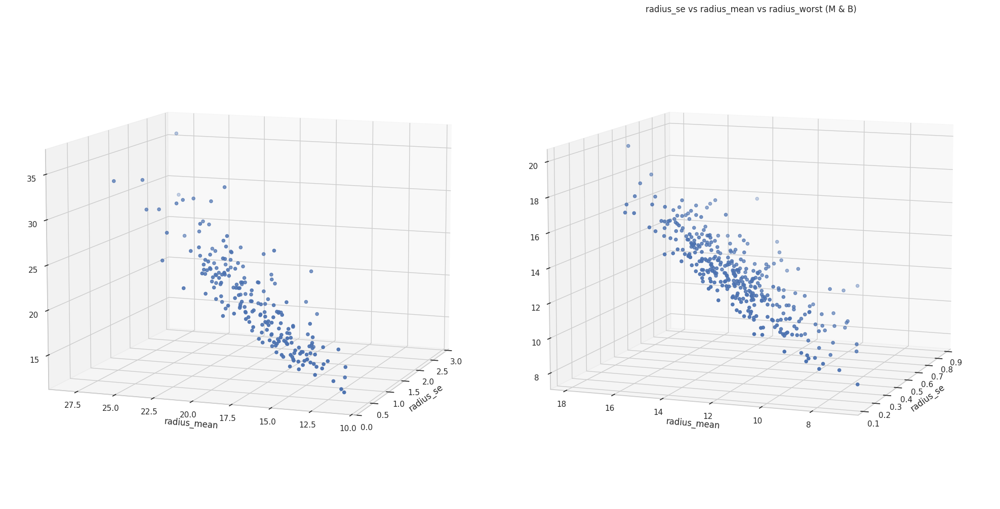

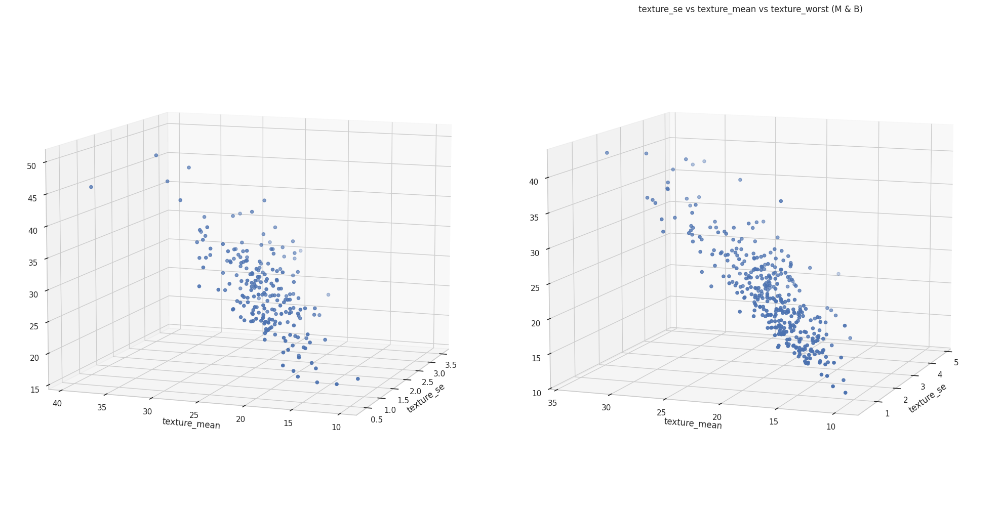

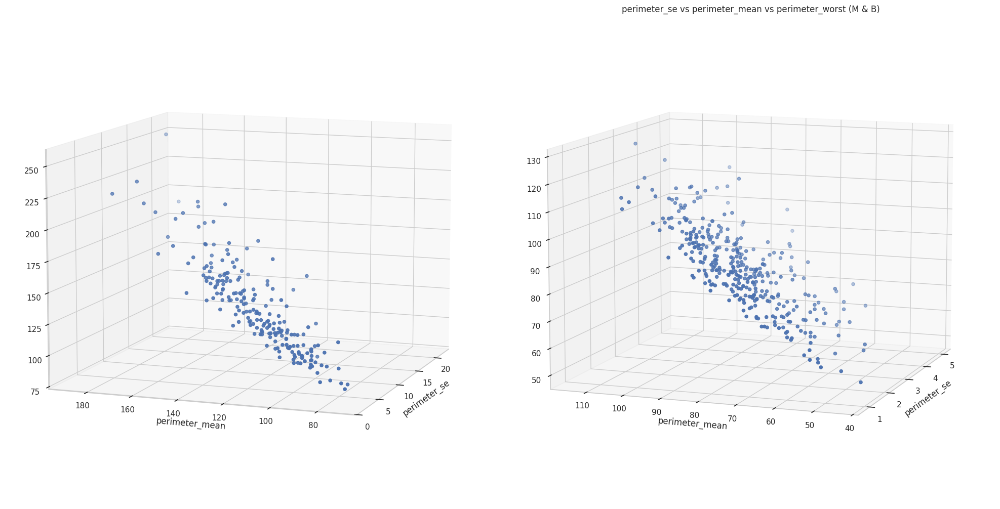

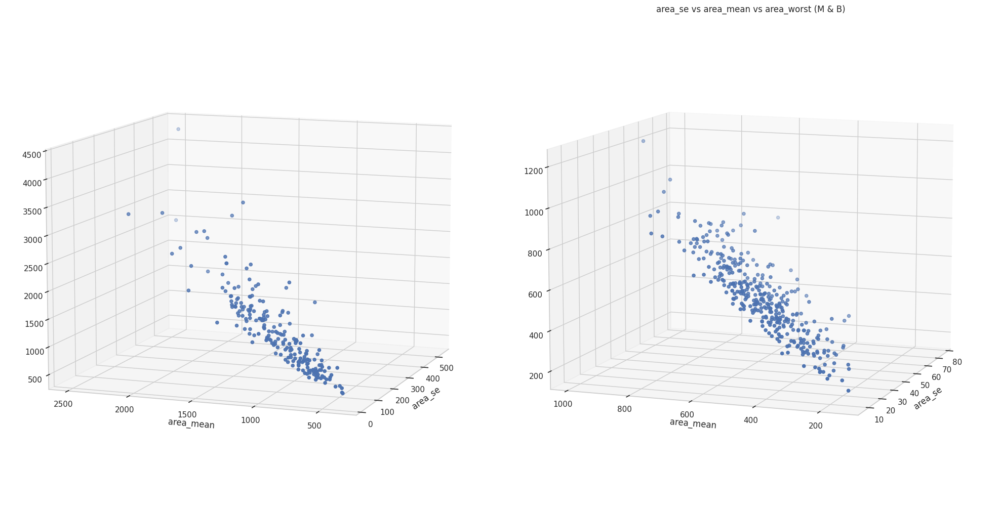

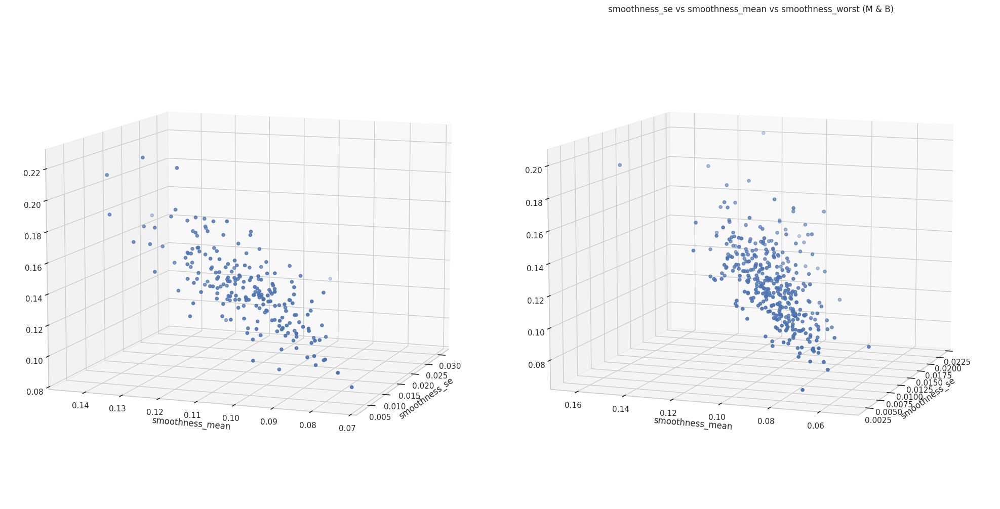

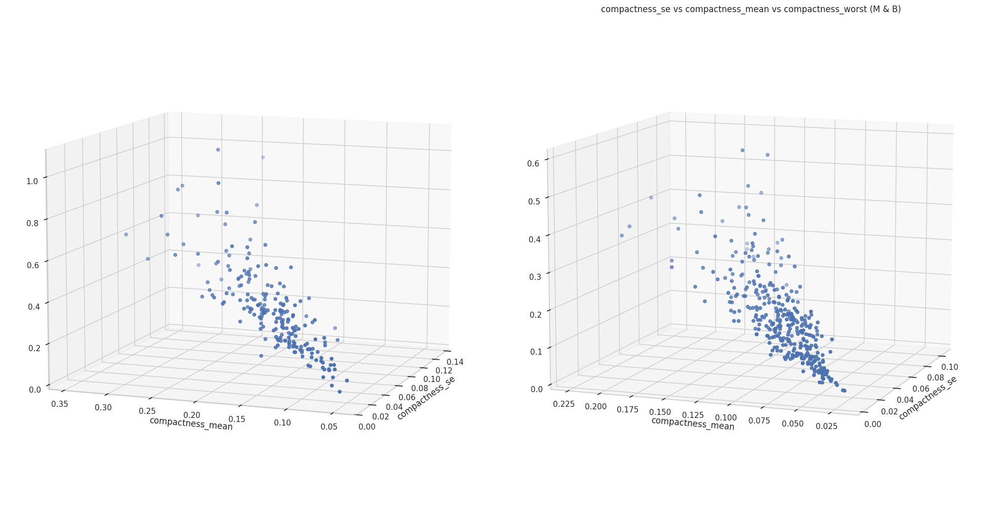

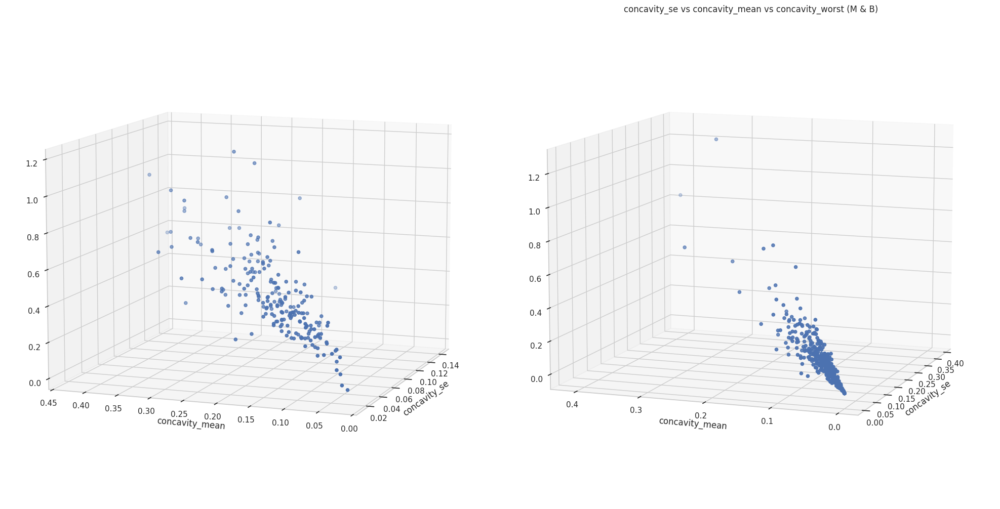

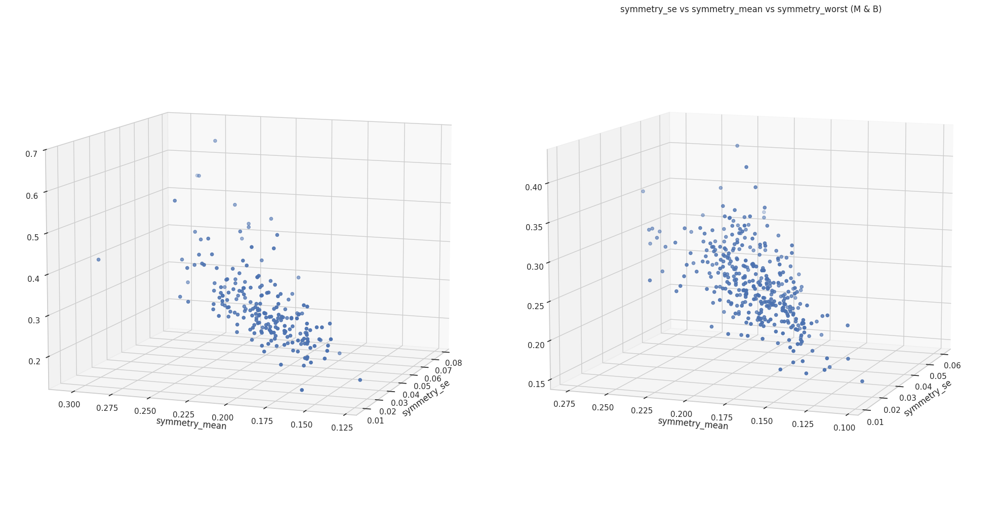

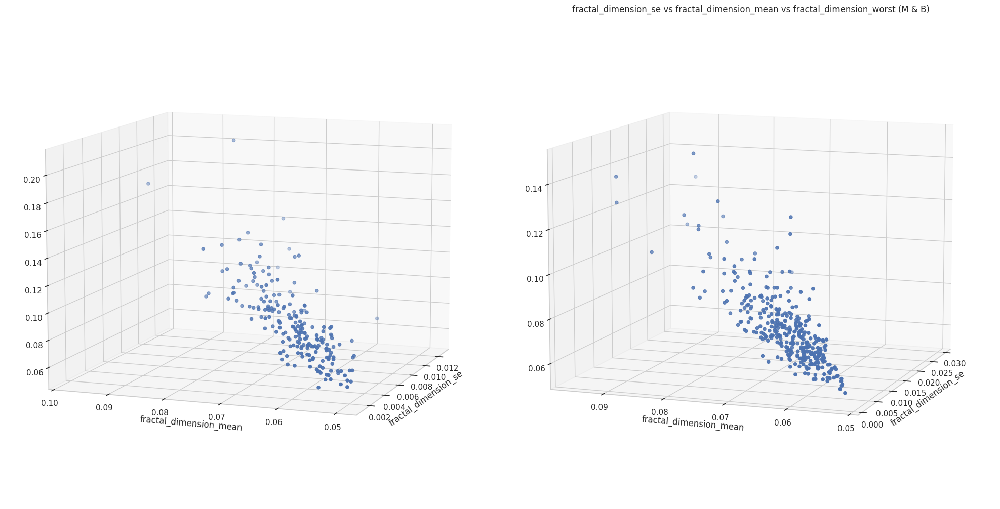

In [76]:
pairs: list[tuple[str, str]] = [
    ('radius_se', 'radius_mean', 'radius_worst'),
    ('texture_se', 'texture_mean', 'texture_worst'),
    ('perimeter_se', 'perimeter_mean', 'perimeter_worst'),
    ('area_se', 'area_mean', 'area_worst'),
    ('smoothness_se', 'smoothness_mean', 'smoothness_worst'),
    ('compactness_se', 'compactness_mean', 'compactness_worst'),
    ('concavity_se', 'concavity_mean', 'concavity_worst'),
    ('symmetry_se', 'symmetry_mean', 'symmetry_worst'),
    ('fractal_dimension_se', 'fractal_dimension_mean', 'fractal_dimension_worst'),
]

for x_col, y_col, z_col in pairs:
    figure, axis = plt.subplots(1, 2, subplot_kw={'projection': '3d'})
    figure.set_figheight(10)
    figure.set_figwidth(20)
    plt.title(f"{x_col} vs {y_col} vs {z_col} (M & B)")

    subset1 = data[data['diagnosis'] == 'M']
    subset2 = data[data['diagnosis'] == 'B']
    axis[0].set_xlabel(x_col)
    axis[1].set_xlabel(x_col)
    axis[0].set_ylabel(y_col)
    axis[1].set_ylabel(y_col)
    axis[0].scatter(subset1[x_col], subset1[y_col], subset1[z_col])
    axis[1].scatter(subset2[x_col], subset2[y_col], subset2[z_col])

    axis[0].view_init(elev=10, azim=200, roll=0)
    axis[1].view_init(elev=10, azim=200, roll=0)

    plt.tight_layout()
    plt.show()

In [77]:
y = pd.Series([0 if diagnosis == "B" else 1 for diagnosis in y.values], dtype=bool)

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y)

In [78]:
print('Formato de x:', x.shape)
print('Formato de y:', y.shape)

print("\nx_train:", x_train.shape)
print("x_test :", x_test.shape)

print("\nDistribuição em y_train: (False = B, True = M)")
print(y_train.value_counts())
print("\nDistribuição em y_test: (False = B, True = M)")
print(y_test.value_counts())

Formato de x: (569, 31)
Formato de y: (569,)

x_train: (455, 31)
x_test : (114, 31)

Distribuição em y_train: (False = B, True = M)
False    285
True     170
Name: count, dtype: int64

Distribuição em y_test: (False = B, True = M)
False    72
True     42
Name: count, dtype: int64


In [79]:
params_dict = {
    "svm_linear": (SVC(kernel="linear", cache_size=CACHE, random_state=RANDOM_STATE), {
        "clf__C": [0.001, 0.01, 0.1, 1, 10],
        "clf__class_weight": [None, "balanced"],
    }),
    "svm_rbf": (SVC(kernel="rbf", cache_size=CACHE, random_state=RANDOM_STATE), {
        "clf__C": [10, 75, 100, 125, 200],
        "clf__class_weight": [None],
        "clf__gamma": ["scale", "auto", 0.1, 1, 2, 10],
    }),
    "svm_poly": (SVC(kernel="poly", cache_size=CACHE, random_state=RANDOM_STATE), {
        "clf__C": [0.01, 0.1, 1, 10, 20],
        "clf__class_weight": [None, "balanced"],
        "clf__coef0": [1, 3, 5],
        "clf__gamma": [0.01, 0.1, 0.5],
    }),
    "svm_sigmoid": (SVC(kernel="sigmoid", cache_size=CACHE, random_state=RANDOM_STATE), {
        "clf__C": [1, 10, 50, 100],
        "clf__class_weight": [None, "balanced"],
        "clf__coef0": [0, 0.5, 1],
        "clf__gamma": [0.0001, 0.001, 0.01],
    }),
    "decision_tree": (DecisionTreeClassifier(random_state=RANDOM_STATE), {
        'clf__class_weight': ['balanced'],
        'clf__criterion': ['gini', 'entropy'],
        'clf__max_depth': [None, 10, 20, 40],
        'clf__max_features': [None, 'sqrt', 'log2'],
        'clf__min_samples_leaf': [2, 4, 10],
        'clf__min_samples_split': [2, 5, 10],
    }),
    "random_forest": (RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=N_JOBS), {
        'clf__class_weight': [None, 'balanced'],
        'clf__max_depth': [None, 10, 20],
        'clf__max_features': ['sqrt', 'log2'],
        'clf__min_samples_leaf': [1, 2],
        'clf__min_samples_split': [2, 5],
        'clf__n_estimators': [200, 500],
    }),
    "xgboost": (XGBClassifier(
        objective='binary:logistic',
        predictor='gpu_predictor',
        eval_metric='mlogloss',
        tree_method='hist',   # fast and Kaggle-friendly
        random_state=RANDOM_STATE,
        n_jobs=N_JOBS,
        cache_size=CACHE,
    ), {
        'clf__colsample_bytree': [0.1, 0.5],
        'clf__learning_rate': [0.1, 0.5, 1],
        'clf__max_depth': [4, 6, 8, 10],
        'clf__n_estimators': [200, 500],
        'clf__reg_lambda': [0.1, 0.5, 1.0],
        'clf__subsample': [0.5, 1.0],
    }),
}

=============== Treinando SVM_LINEAR... ===============
Fitting 5 folds for each of 10 candidates, totalling 50 fits
[Pipeline] .............. (step 1 of 2) Processing prep, total=   0.0s
[Pipeline] ............... (step 2 of 2) Processing clf, total=   0.0s
Modelo treinado em 0.06s


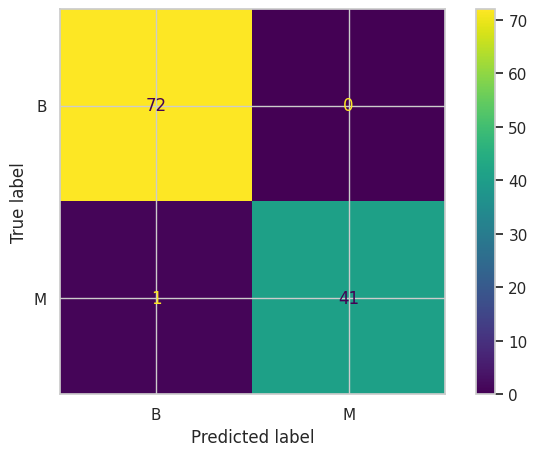

,3,4,5,6,7
mean_fit_time,0.003159,0.002363,0.003426,0.00287,0.002468
std_fit_time,0.0006,0.000134,0.000482,0.00068,0.000052
mean_score_time,0.00153,0.001132,0.001558,0.001313,0.00112
std_score_time,0.000313,0.000034,0.000205,0.000279,0.000041
param_clf__C,0.01,0.1,0.1,1.0,1.0
param_clf__class_weight,balanced,None,balanced,None,balanced
params,"{'clf__C': 0.01, 'clf__class_weight': 'balanced'}","{'clf__C': 0.1, 'clf__class_weight': None}","{'clf__C': 0.1, 'clf__class_weight': 'balanced'}","{'clf__C': 1, 'clf__class_weight': None}","{'clf__C': 1, 'clf__class_weight': 'balanced'}"
split0_test_score,0.967033,0.956044,0.945055,0.945055,0.956044
split1_test_score,0.967033,0.978022,0.967033,0.978022,0.978022
split2_test_score,0.978022,0.978022,0.989011,0.967033,0.967033


Pipeline(steps=[('prep', StandardScaler()),
                ('clf',
                 SVC(C=0.01, cache_size=1000, class_weight='balanced',
                     kernel='linear', random_state=42))],
         verbose=True)

None

=============== Treinando SVM_RBF... ===============
Fitting 5 folds for each of 30 candidates, totalling 150 fits
[Pipeline] .............. (step 1 of 2) Processing prep, total=   0.0s
[Pipeline] ............... (step 2 of 2) Processing clf, total=   0.0s
Modelo treinado em 0.16s


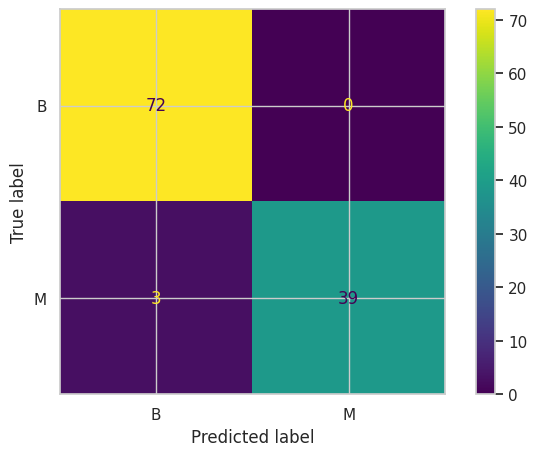

,0,1,6,7,12
mean_fit_time,0.00359,0.003339,0.00307,0.00255,0.003537
std_fit_time,0.000555,0.00078,0.000621,0.000073,0.000521
mean_score_time,0.001639,0.001581,0.001513,0.00134,0.001664
std_score_time,0.000224,0.000253,0.000234,0.000029,0.000207
param_clf__C,10,10,75,75,100
param_clf__class_weight,None,None,None,None,None
param_clf__gamma,scale,auto,scale,auto,scale
params,"{'clf__C': 10, 'clf__class_weight': None, 'clf...","{'clf__C': 10, 'clf__class_weight': None, 'clf...","{'clf__C': 75, 'clf__class_weight': None, 'clf...","{'clf__C': 75, 'clf__class_weight': None, 'clf...","{'clf__C': 100, 'clf__class_weight': None, 'cl..."
split0_test_score,0.967033,0.967033,0.956044,0.956044,0.956044
split1_test_score,0.989011,0.989011,0.956044,0.956044,0.956044


Pipeline(steps=[('prep', StandardScaler()),
                ('clf', SVC(C=10, cache_size=1000, random_state=42))],
         verbose=True)

None

=============== Treinando SVM_POLY... ===============
Fitting 5 folds for each of 90 candidates, totalling 450 fits
[Pipeline] .............. (step 1 of 2) Processing prep, total=   0.0s
[Pipeline] ............... (step 2 of 2) Processing clf, total=   0.0s
Modelo treinado em 0.28s


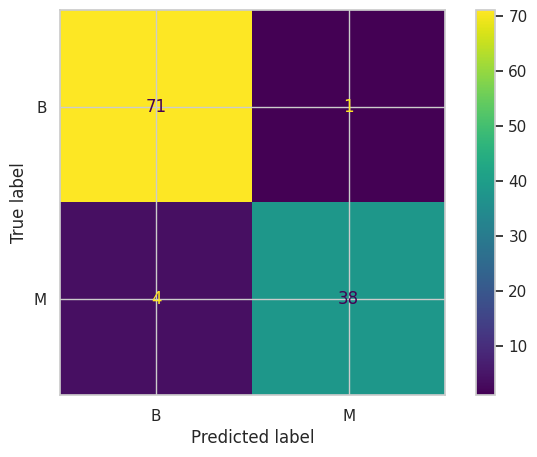

,22,28,16,19,54
mean_fit_time,0.002872,0.002458,0.00234,0.002283,0.002235
std_fit_time,0.000563,0.000204,0.000104,0.000102,0.000149
mean_score_time,0.001441,0.001143,0.001101,0.001156,0.00108
std_score_time,0.000252,0.000027,0.000029,0.000024,0.000038
param_clf__C,0.1,0.1,0.01,0.1,10.0
param_clf__class_weight,None,balanced,balanced,None,None
param_clf__coef0,3,1,5,1,1
param_clf__gamma,0.1,0.1,0.1,0.1,0.01
params,"{'clf__C': 0.1, 'clf__class_weight': None, 'cl...","{'clf__C': 0.1, 'clf__class_weight': 'balanced...","{'clf__C': 0.01, 'clf__class_weight': 'balance...","{'clf__C': 0.1, 'clf__class_weight': None, 'cl...","{'clf__C': 10, 'clf__class_weight': None, 'clf..."
split0_test_score,0.967033,0.967033,0.956044,0.956044,0.967033


Pipeline(steps=[('prep', StandardScaler()),
                ('clf',
                 SVC(C=0.1, cache_size=1000, coef0=3, gamma=0.1, kernel='poly',
                     random_state=42))],
         verbose=True)

None

=============== Treinando SVM_SIGMOID... ===============
Fitting 5 folds for each of 72 candidates, totalling 360 fits
[Pipeline] .............. (step 1 of 2) Processing prep, total=   0.0s
[Pipeline] ............... (step 2 of 2) Processing clf, total=   0.0s
Modelo treinado em 0.27s


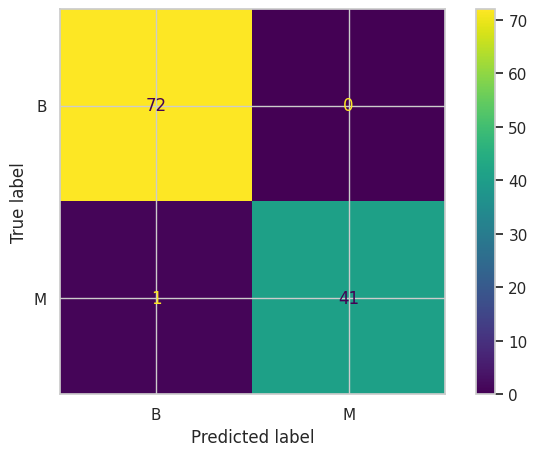

,28,63,52,31,66
mean_fit_time,0.003056,0.002953,0.003327,0.002927,0.003565
std_fit_time,0.000224,0.000065,0.000492,0.000091,0.000799
mean_score_time,0.001368,0.001312,0.00145,0.001315,0.001536
std_score_time,0.000081,0.000041,0.000243,0.000062,0.000313
param_clf__C,10,100,50,10,100
param_clf__class_weight,balanced,balanced,balanced,balanced,balanced
param_clf__coef0,0.0,0.0,1.0,0.5,0.5
param_clf__gamma,0.001,0.0001,0.001,0.001,0.0001
params,"{'clf__C': 10, 'clf__class_weight': 'balanced'...","{'clf__C': 100, 'clf__class_weight': 'balanced...","{'clf__C': 50, 'clf__class_weight': 'balanced'...","{'clf__C': 10, 'clf__class_weight': 'balanced'...","{'clf__C': 100, 'clf__class_weight': 'balanced..."
split0_test_score,0.967033,0.967033,0.956044,0.967033,0.967033


Pipeline(steps=[('prep', StandardScaler()),
                ('clf',
                 SVC(C=10, cache_size=1000, class_weight='balanced', coef0=0,
                     gamma=0.001, kernel='sigmoid', random_state=42))],
         verbose=True)

None

=============== Treinando DECISION_TREE... ===============
Fitting 5 folds for each of 216 candidates, totalling 1080 fits
[Pipeline] .............. (step 1 of 2) Processing prep, total=   0.0s
[Pipeline] ............... (step 2 of 2) Processing clf, total=   0.0s
Modelo treinado em 0.78s


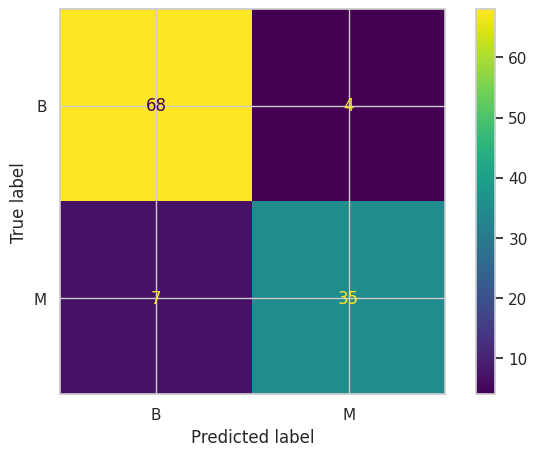

,3,4,5,31,30
mean_fit_time,0.006713,0.006423,0.007134,0.006612,0.006414
std_fit_time,0.000624,0.000511,0.000791,0.000687,0.0005
mean_score_time,0.001167,0.001086,0.001285,0.001172,0.0011
std_score_time,0.000164,0.00001,0.000211,0.000077,0.000035
param_clf__class_weight,balanced,balanced,balanced,balanced,balanced
param_clf__criterion,gini,gini,gini,gini,gini
param_clf__max_depth,None,None,None,10,10
param_clf__max_features,None,None,None,None,None
param_clf__min_samples_leaf,4,4,4,4,4
param_clf__min_samples_split,2,5,10,5,2


Pipeline(steps=[('prep', StandardScaler()),
                ('clf',
                 DecisionTreeClassifier(class_weight='balanced',
                                        min_samples_leaf=4, random_state=42))],
         verbose=True)

None

=============== Treinando RANDOM_FOREST... ===============
Fitting 5 folds for each of 96 candidates, totalling 480 fits
[Pipeline] .............. (step 1 of 2) Processing prep, total=   0.0s
[Pipeline] ............... (step 2 of 2) Processing clf, total=   0.1s
Modelo treinado em 16.12s


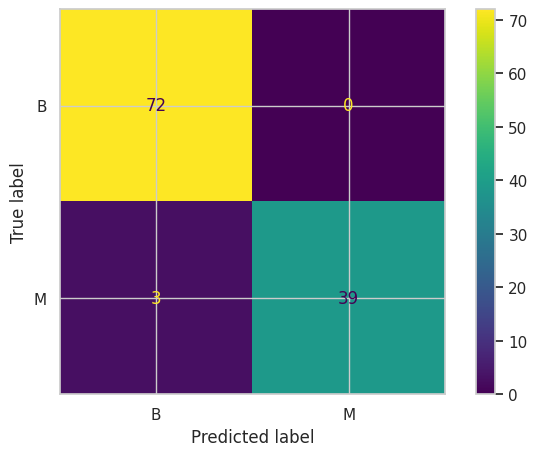

,58,74,90,49,65
mean_fit_time,0.134689,0.144289,0.136038,0.311377,0.320266
std_fit_time,0.008033,0.004122,0.005487,0.005813,0.006737
mean_score_time,0.024041,0.023939,0.023816,0.040858,0.040643
std_score_time,0.000446,0.000239,0.000546,0.005335,0.005548
param_clf__class_weight,balanced,balanced,balanced,balanced,balanced
param_clf__max_depth,None,10,20,None,10
param_clf__max_features,log2,log2,log2,sqrt,sqrt
param_clf__min_samples_leaf,1,1,1,1,1
param_clf__min_samples_split,5,5,5,2,2
param_clf__n_estimators,200,200,200,500,500


Pipeline(steps=[('prep', StandardScaler()),
                ('clf',
                 RandomForestClassifier(class_weight='balanced',
                                        max_features='log2',
                                        min_samples_split=5, n_estimators=200,
                                        n_jobs=8, random_state=42))],
         verbose=True)

None

=============== Treinando XGBOOST... ===============
Fitting 5 folds for each of 288 candidates, totalling 1440 fits
[Pipeline] .............. (step 1 of 2) Processing prep, total=   0.0s
[Pipeline] ............... (step 2 of 2) Processing clf, total=   0.0s
Modelo treinado em 10.53s


/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [00:10:50] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "cache_size", "predictor" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


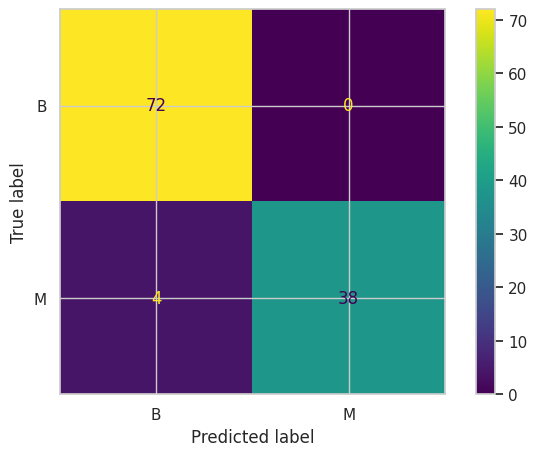

,224,236,212,230,206
mean_fit_time,0.052534,0.059387,0.060024,0.036808,0.041036
std_fit_time,0.001034,0.01251,0.00299,0.011566,0.023081
mean_score_time,0.00234,0.002197,0.002651,0.003479,0.002443
std_score_time,0.00021,0.000183,0.00036,0.001579,0.000397
param_clf__colsample_bytree,0.5,0.5,0.5,0.5,0.5
param_clf__learning_rate,0.5,0.5,0.5,0.5,0.5
param_clf__max_depth,8,10,6,10,6
param_clf__n_estimators,500,500,500,200,200
param_clf__reg_lambda,0.5,0.5,0.5,0.5,0.5
param_clf__subsample,0.5,0.5,0.5,0.5,0.5


Pipeline(steps=[('prep', StandardScaler()),
                ('clf',
                 XGBClassifier(base_score=None, booster=None, cache_size=1000,
                               callbacks=None, colsample_bylevel=None,
                               colsample_bynode=None, colsample_bytree=0.5,
                               device=None, early_stopping_rounds=None,
                               enable_categorical=True, eval_metric='mlogloss',
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.5,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=6, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=500, n_jobs=8, ...))],
         verbose=True)

None

In [80]:
cv = StratifiedKFold(n_splits=CV_SPLITS, shuffle=True, random_state=RANDOM_STATE)
results, cv_tables = [], {}

for classifier, (clf, param_grid) in params_dict.items():
    print("=" * 15, f"Treinando {classifier.upper()}...", "=" * 15)

    pipeline: Pipeline = Pipeline([
        ('prep', StandardScaler()),
        ('clf', clf)
    ], verbose=True)

    search = GridSearchCV(pipeline,  param_grid=param_grid, cv=cv, scoring="accuracy", n_jobs=N_JOBS, refit=True, verbose=VERBOSE)

    start = time.monotonic()
    search.fit(x_train, y_train)
    elapsed = time.monotonic() - start

    print(f"Modelo treinado em {elapsed:.2f}s")

    y_pred = search.predict(x_test)

    cv_tables[classifier] = pd.DataFrame(search.cv_results_).sort_values(by="rank_test_score")

    ConfusionMatrixDisplay(confusion_matrix=confusion_matrix(y_test, y_pred), display_labels=["B", "M"]).plot()

    display(
        cv_tables[classifier][:5].transpose(),
        search.best_estimator_,
        plt.show()
    )

    results.append({
        "classifier": classifier,
        "cv_best_score": search.best_score_,
    })

In [81]:
results_df = pd.DataFrame(results)

results_df.set_index(keys="classifier").sort_values(by=["cv_best_score"], ascending=False)

,cv_best_score
classifier,
xgboost,0.984615
svm_poly,0.982418
svm_rbf,0.975824
svm_linear,0.973626
svm_sigmoid,0.973626
random_forest,0.967033
decision_tree,0.949451


In [83]:
del axis, classifier, clf, cv, cv_tables, data, elapsed, figure, pairs, param_grid, params_dict, path, pipeline, results, results_df, search, start, subset1, subset2, x, x_col, x_test, x_train, y, y_col, y_pred, y_test, y_train, z_col

# Fishmorph

In [138]:
FILES = ["FISHMORPH_Order_Dataset.csv", "FISHMORPH_Family_Dataset.csv"]
TARGETS = ["Order", "Family"]
local_file = None
path = "./"
df_dict = {}

for file_name in FILES:
    candidates = [
        Path("../" + file_name),
        Path(f"{path}{file_name}"),
        Path("/kaggle/input/menegidio/fishmorph-dataset/versions/1/" + file_name),
        Path("/kaggle/input/menegidio/fishmorph-dataset/" + file_name),
    ]
    local_file = next((candidate for candidate in candidates if candidate.exists()), None)

    if local_file is None:
        path = Path(dataset_download("menegidio/fishmorph-dataset"))
        candidates = sorted(path.rglob("*.csv"))
        if not candidates:
            raise FileNotFoundError("CSV não encontrado no download do Kaggle.")
        local_file = next((file for file in candidates if file.name.lower() == file_name.lower()), None)

    print("\nArquivo:", local_file, "\n")

    df_dict[file_name] = pd.read_csv(local_file, dtype={
        'MBl': np.float32,
        'BEl': np.float32,
        'VEp': np.float32,
        'REs': np.float32,
        'OGp': np.float32,
        'RMl': np.float32,
        'BLs': np.float32,
        'PFv': np.float32,
        'PFs': np.float32,
        'CPt': np.float32,
    })
    df_dict[file_name].info()

ord_df, fam_df = df_dict.values()
del local_file, path, df_dict, FILES

Using Colab cache for faster access to the 'fishmorph-dataset' dataset.

Arquivo: /kaggle/input/fishmorph-dataset/FISHMORPH_Order_Dataset.csv 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8342 entries, 0 to 8341
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   MBl     8342 non-null   float32
 1   BEl     8342 non-null   float32
 2   VEp     8342 non-null   float32
 3   REs     8342 non-null   float32
 4   OGp     8342 non-null   float32
 5   RMl     8342 non-null   float32
 6   BLs     8342 non-null   float32
 7   PFv     8342 non-null   float32
 8   PFs     8342 non-null   float32
 9   CPt     8342 non-null   float32
 10  Order   8342 non-null   object 
dtypes: float32(10), object(1)
memory usage: 391.2+ KB
Using Colab cache for faster access to the 'fishmorph-dataset' dataset.

Arquivo: /kaggle/input/fishmorph-dataset/FISHMORPH_Family_Dataset.csv 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8342 entries, 0 to

In [139]:
MIN_CLASS_COUNT = 10

def filter_rare_classes(df, target):
    classes_count = df[target].value_counts()

    print(f"Classes de \"{target}\" excluídas por aparições insuficientes:")
    display(classes_count[classes_count < MIN_CLASS_COUNT].to_frame())

    above_minimum = classes_count[classes_count >= MIN_CLASS_COUNT].index
    return df[df[target].isin(above_minimum)].reset_index(drop=True)

In [140]:
def prepare_samples(df, target):
    print("=" * 15, f"Dataset da coluna alvo \"{target}\"", "=" * 15)
    assert target in df.columns, f"Coluna-alvo não encontrada no dataset: \"{target}\" em {list(df.columns)}"

    df = df.sample(n=len(df.values)//SPLIT_SAMPLES_BY, random_state=RANDOM_STATE, replace=False)
    df = filter_rare_classes(df, target)

    x = df.drop(columns=[target])
    y = df[target]
    assert x.notna().all().all() and y.notna().all(), f"Existem valores ausentes nas amostras: \nX:\n{x.values[x.notna()]}\n\nY:\n{y[[not boolean for boolean in y.notna()]]}"

    print("Dimensões:", x.shape, "| Classes:", y.nunique())
    print("Uso de memória das amostras cruas:", df.memory_usage().sum() / 1000, "KB")
    display((df.memory_usage() / 1000).rename("KB").to_frame().transpose())

    print("Primeiras 5 amostras:")
    display(x.head())

    return x, y

x_ord, y_ord = prepare_samples(ord_df, TARGETS[0])
x_fam, y_fam = prepare_samples(fam_df, TARGETS[1])

=============== Dataset da coluna alvo "Order" ===============
Classes de "Order" excluídas por aparições insuficientes:


,count
Order,
Mugiliformes,9
Syngnathiformes,8
Esociformes,6
Polypteriformes,6
Anguilliformes,6
Gonorynchiformes,4
Percopsiformes,4
Elopiformes,2
Batrachoidiformes,2


Dimensões: (4120, 10) | Classes: 18
Uso de memória das amostras cruas: 197.892 KB


,Index,MBl,BEl,VEp,REs,OGp,RMl,BLs,PFv,PFs,CPt,Order
KB,0.132,16.48,16.48,16.48,16.48,16.48,16.48,16.48,16.48,16.48,16.48,32.96


Primeiras 5 amostras:


,MBl,BEl,VEp,REs,OGp,RMl,BLs,PFv,PFs,CPt
0,4.9,3.570231,0.609119,0.450424,0.449641,0.415711,0.653850,0.566776,0.228959,1.666948
1,51.0,4.209456,0.603144,0.292672,0.219525,0.184593,0.541878,0.209731,0.185695,2.901687
2,82.0,3.105530,0.441475,0.411882,0.269645,0.543565,0.398438,0.250000,0.193187,2.312547
3,65.0,4.694873,0.454828,0.264794,0.000000,0.685132,0.555463,0.233216,0.179713,2.800205
4,20.0,4.241331,0.472095,0.415518,0.301116,0.539768,0.496405,0.209845,0.199581,2.150899


... (2 outputs left out)

Dimensões: (3854, 10) | Classes: 66
Uso de memória das amostras cruas: 185.124 KB


,Index,MBl,BEl,VEp,REs,OGp,RMl,BLs,PFv,PFs,CPt,Family
KB,0.132,15.416,15.416,15.416,15.416,15.416,15.416,15.416,15.416,15.416,15.416,30.832


Primeiras 5 amostras:


,MBl,BEl,VEp,REs,OGp,RMl,BLs,PFv,PFs,CPt
0,4.9,3.570231,0.609119,0.450424,0.449641,0.415711,0.653850,0.566776,0.228959,1.666948
1,51.0,4.209456,0.603144,0.292672,0.219525,0.184593,0.541878,0.209731,0.185695,2.901687
2,82.0,3.105530,0.441475,0.411882,0.269645,0.543565,0.398438,0.250000,0.193187,2.312547
3,65.0,4.694873,0.454828,0.264794,0.000000,0.685132,0.555463,0.233216,0.179713,2.800205
4,20.0,4.241331,0.472095,0.415518,0.301116,0.539768,0.496405,0.209845,0.199581,2.150899


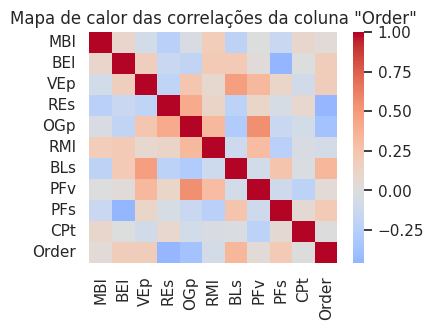

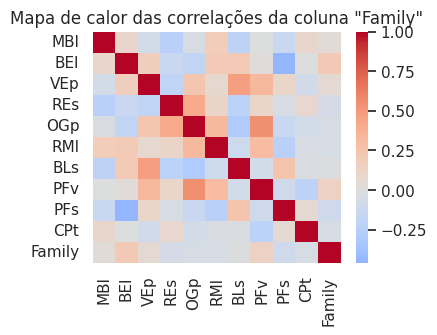

In [141]:
def draw_heatmap(df, target = ""):
    str_columns = df.select_dtypes(include=["object", "string"])

    for column in str_columns.columns:
        df[column] = LabelEncoder().fit_transform(pd.Series(str_columns[column]))

    correlation = df.corr()
    plt.figure(figsize=(4, 3))
    heatmap(correlation, cmap="coolwarm", center=0)
    plt.title(f"Mapa de calor das correlações da coluna \"{target}\"")
    plt.show()
    return correlation

ord_correlation = draw_heatmap(ord_df, TARGETS[0])
fam_correlation = draw_heatmap(fam_df, TARGETS[1])

=============== Order ===============
Colunas irrelevantes: []
Amostras atualizadas:


,MBl,BEl,VEp,REs,OGp,RMl,BLs,PFv,PFs,CPt
0,4.9,3.570231,0.609119,0.450424,0.449641,0.415711,0.653850,0.566776,0.228959,1.666948
1,51.0,4.209456,0.603144,0.292672,0.219525,0.184593,0.541878,0.209731,0.185695,2.901687
2,82.0,3.105530,0.441475,0.411882,0.269645,0.543565,0.398438,0.250000,0.193187,2.312547


Uso de memória das amostras filtradas: 164.93 KB



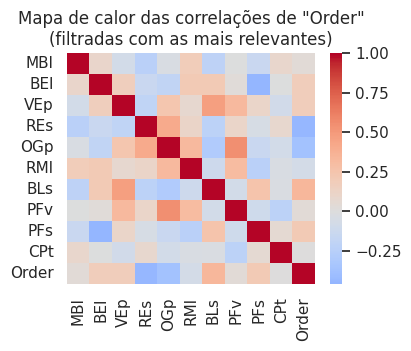

=============== Family ===============
Colunas irrelevantes: []
Amostras atualizadas:


,MBl,BEl,VEp,REs,OGp,RMl,BLs,PFv,PFs,CPt
0,4.9,3.570231,0.609119,0.450424,0.449641,0.415711,0.653850,0.566776,0.228959,1.666948
1,51.0,4.209456,0.603144,0.292672,0.219525,0.184593,0.541878,0.209731,0.185695,2.901687
2,82.0,3.105530,0.441475,0.411882,0.269645,0.543565,0.398438,0.250000,0.193187,2.312547


Uso de memória das amostras filtradas: 154.29 KB



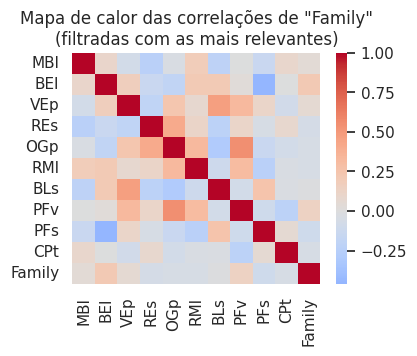

In [142]:
CORRELATION_THRESHOLD = 0.2

def drop_irrelevant_cols(df, x, correlation, target):
    irrelevant_cols = set()
    for column_name in correlation.drop(columns=[target]).columns:
        column = correlation[column_name].drop(column_name)
        direct_correlation = column[column >= CORRELATION_THRESHOLD]
        inverse_correlation = column[column <= -CORRELATION_THRESHOLD]
        if len(direct_correlation) + len(inverse_correlation) == 0: irrelevant_cols.add(column_name)
    print("=" * 15, target, "=" * 15)
    print("Colunas irrelevantes:", list(irrelevant_cols))

    correlation = df.drop(columns=irrelevant_cols).corr()
    plt.figure(figsize=(4, 3))
    heatmap(correlation, annot=False, cmap="coolwarm", center=0)
    plt.title(f"Mapa de calor das correlações de \"{target}\"\n(filtradas com as mais relevantes)")

    updated_x = x.drop(columns=irrelevant_cols)

    print("Amostras atualizadas:")
    display(updated_x.head(3))
    print(f"Uso de memória das amostras filtradas: {(updated_x.memory_usage() / 1000).sum():.2f} KB\n")
    plt.show()

    return updated_x

x_ord = drop_irrelevant_cols(ord_df, x_ord, ord_correlation, TARGETS[0])
x_fam = drop_irrelevant_cols(fam_df, x_fam, fam_correlation, TARGETS[1])

del ord_correlation, fam_correlation, CORRELATION_THRESHOLD

In [143]:
def split_samples(x, y, target):
    x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y)

    print(f"Dataset da coluna \"{target}\"")
    print("Treino:", x_train.shape, f"Uso de memória: {(x_train.memory_usage() / 1000).sum():.2f} KB")
    print("Teste:", x_test.shape, f"Uso de memória: {x_test.memory_usage().sum() / 1000:.2f} KB")
    print(f"\nImpacto de memória definitivo: {(x_train.memory_usage().sum() + x_test.memory_usage().sum()) / 1000:.2f} KB")

    return x_train, x_test, y_train, y_test

x_train_ord, x_test_ord, y_train_ord, y_test_ord = split_samples(x_ord, y_ord, TARGETS[0])
print("=" * 50)
x_train_fam, x_test_fam, y_train_fam, y_test_fam = split_samples(x_fam, y_fam, TARGETS[1])

Dataset da coluna "Order"
Treino: (3296, 10) Uso de memória: 158.21 KB
Teste: (824, 10) Uso de memória: 39.55 KB

Impacto de memória definitivo: 197.76 KB
Dataset da coluna "Family"
Treino: (3083, 10) Uso de memória: 147.98 KB
Teste: (771, 10) Uso de memória: 37.01 KB

Impacto de memória definitivo: 184.99 KB


In [144]:
params_dict = {
    'svm linear': (SVC(kernel="linear", cache_size=CACHE, random_state=RANDOM_STATE), {
        'clf__C': [100, 700, 1000, 1500],
        'clf__class_weight': [None, 'balanced'],
    }),
    'svm rbf': (SVC(kernel="rbf", cache_size=CACHE, random_state=RANDOM_STATE), {
        'clf__C': [10, 100],
        'clf__gamma': ['auto', 'scale', 0.01, 0.1, 1, 10],
        'clf__class_weight': [None]
    }),
    'svm sigmoid': (SVC(kernel="sigmoid", cache_size=CACHE, random_state=RANDOM_STATE), {
        'clf__C': [1, 10],
        'clf__gamma': ['auto', 'scale', 0.001, 0.01, 0.1],
        'clf__coef0': [0, 1],
        'clf__class_weight': [None, 'balanced']
    }),
    'decision tree': (DecisionTreeClassifier(random_state=RANDOM_STATE), {
        'clf__criterion': ['gini', 'entropy'],
        'clf__max_depth': [None, 10, 20, 40],
        'clf__min_samples_split': [2, 5, 10],
        'clf__min_samples_leaf': [1, 2, 4],
        'clf__max_features': [None, 'sqrt', 'log2'],
        # 'clf__class_weight': [None, 'balanced']  # enable if imbalance is severe
    }),
    "random_forest": (RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=N_JOBS), {
        'clf__class_weight': [None, 'balanced'],
        'clf__max_depth': [None, 10, 20],
        'clf__max_features': ['sqrt', 'log2'],
        'clf__min_samples_leaf': [1, 2],
        'clf__min_samples_split': [2, 5],
        'clf__n_estimators': [200, 500],
    }),
    "xgboost": (XGBClassifier(
        objective='binary:logistic',
        predictor='gpu_predictor',
        eval_metric='mlogloss',
        tree_method='hist',   # fast and Kaggle-friendly
        random_state=RANDOM_STATE,
        n_jobs=N_JOBS,
        cache_size=CACHE,
    ), {
        'clf__colsample_bytree': [0.5, 1.0],
        'clf__learning_rate': [0.1, 0.5, 1],
        'clf__max_depth': [6, 8],
        'clf__n_estimators': [200, 500],
        'clf__reg_lambda': [0.1, 0.5],
        'clf__subsample': [1.0],
    }),
}

iterations_df = pd.DataFrame()
for clf, (_, values) in params_dict.items():
    combinations = CV_SPLITS
    for value in values.values():
        combinations *= len(value)
    iterations_df[clf.upper()] = [combinations]

iterations_df["Total Fam + Ord"] = iterations_df.values.sum() * 2
iterations_df = iterations_df.transpose()
iterations_df.columns = ["Iterações"]
iterations_df["Cálculos Ord"] = iterations_df["Iterações"] * len(x_train_ord)
iterations_df["Cálculos Fam"] = iterations_df["Iterações"] * len(x_train_fam)
iterations_df

,Iterações,Cálculos Ord,Cálculos Fam
SVM LINEAR,40,131840,123320
SVM RBF,60,197760,184980
SVM SIGMOID,200,659200,616600
DECISION TREE,1080,3559680,3329640
RANDOM_FOREST,480,1582080,1479840
XGBOOST,240,791040,739920
Total Fam + Ord,4200,13843200,12948600


In [145]:
def train_predict_models(x, x_train, x_test, y_train, target):
    preprocessing = ColumnTransformer(
        transformers=[
            ('num', StandardScaler(copy=False), list(x.select_dtypes(include="number").columns)),
        ]
    )

    cv = StratifiedKFold(n_splits=CV_SPLITS, shuffle=True, random_state=RANDOM_STATE)
    results, predictions, fitted, cv_tables = [], {}, {}, {}

    for classifier, (clf, param_grid) in params_dict.items():
        print('=' * 15, f'Executando {classifier.upper()} para {target.upper()}...', '=' * 15)

        pipeline = Pipeline([
            ('prep', preprocessing),
            ('clf', clf),
        ], verbose=True)
        search = GridSearchCV(pipeline, param_grid=param_grid, cv=cv, scoring='accuracy', n_jobs=N_JOBS, refit=True, verbose=VERBOSE)

        label_encoder = LabelEncoder().fit(y_train)
        y_train_enc = label_encoder.transform(y_train)

        start = time.monotonic()
        search.fit(x_train, y_train_enc)
        elapsed = time.monotonic() - start
        print(f'Modelo treinado em {elapsed:.2f}s')

        y_pred_enc = search.best_estimator_.predict(x_test)
        y_pred = label_encoder.inverse_transform(y_pred_enc)

        fitted[classifier] = search
        predictions[classifier] = y_pred
        cv_tables[classifier] = pd.DataFrame(search.cv_results_).sort_values(by=['rank_test_score']).drop(columns=['params', 'std_test_score', 'std_fit_time', 'std_score_time', 'mean_fit_time', 'mean_score_time'])
        results.append({
            'classifier': classifier,
            'cv_best_score': float(search.best_score_),
            'cv_accuracy': float(cv_tables[classifier]['mean_test_score'][0]),
        })

        display(
            cv_tables[classifier][:5].transpose(),
            search.best_estimator_,
        )
    return results, predictions, fitted, cv_tables

results_ord, predictions_ord, fitted_ord, cv_tables_ord = train_predict_models(x_ord, x_train_ord, x_test_ord, y_train_ord, TARGETS[0])
results_fam, predictions_fam, fitted_fam, cv_tables_fam = train_predict_models(x_fam, x_train_fam, x_test_fam, y_train_fam, TARGETS[1])

=============== Executando SVM LINEAR para ORDER... ===============
Fitting 5 folds for each of 8 candidates, totalling 40 fits
[Pipeline] .............. (step 1 of 2) Processing prep, total=   0.0s
[Pipeline] ............... (step 2 of 2) Processing clf, total=  21.2s
Modelo treinado em 76.81s


,4,2,6,0,5
param_clf__C,1000,700,1500,100,1000
param_clf__class_weight,None,None,None,None,balanced
split0_test_score,0.710606,0.710606,0.709091,0.709091,0.659091
split1_test_score,0.698027,0.698027,0.698027,0.698027,0.644917
split2_test_score,0.717754,0.717754,0.717754,0.717754,0.644917
split3_test_score,0.69044,0.69044,0.688923,0.69044,0.640364
split4_test_score,0.694992,0.693475,0.694992,0.693475,0.622155
mean_test_score,0.702364,0.702061,0.701757,0.701757,0.642289
rank_test_score,1,2,3,4,5


Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num',
                                                  StandardScaler(copy=False),
                                                  ['MBl', 'BEl', 'VEp', 'REs',
                                                   'OGp', 'RMl', 'BLs', 'PFv',
                                                   'PFs', 'CPt'])])),
                ('clf',
                 SVC(C=1000, cache_size=1000, kernel='linear',
                     random_state=42))],
         verbose=True)

=============== Executando SVM RBF para ORDER... ===============
Fitting 5 folds for each of 12 candidates, totalling 60 fits
[Pipeline] .............. (step 1 of 2) Processing prep, total=   0.1s
[Pipeline] ............... (step 2 of 2) Processing clf, total=   0.1s
Modelo treinado em 2.62s


,0,1,3,8,6
param_clf__C,10,10,10,100,100
param_clf__class_weight,None,None,None,None,None
param_clf__gamma,auto,scale,0.1,0.01,auto
split0_test_score,0.769697,0.769697,0.769697,0.772727,0.742424
split1_test_score,0.775417,0.775417,0.775417,0.757208,0.757208
split2_test_score,0.805766,0.805766,0.805766,0.802731,0.766313
split3_test_score,0.764795,0.764795,0.764795,0.738998,0.769347
split4_test_score,0.748103,0.748103,0.748103,0.758725,0.751138
mean_test_score,0.772756,0.772756,0.772756,0.766078,0.757286
rank_test_score,1,1,1,4,5


Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num',
                                                  StandardScaler(copy=False),
                                                  ['MBl', 'BEl', 'VEp', 'REs',
                                                   'OGp', 'RMl', 'BLs', 'PFv',
                                                   'PFs', 'CPt'])])),
                ('clf',
                 SVC(C=10, cache_size=1000, gamma='auto', random_state=42))],
         verbose=True)

... (34 outputs left out)

/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [01:09:47] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "cache_size", "predictor" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


[Pipeline] ............... (step 2 of 2) Processing clf, total=   3.4s
Modelo treinado em 128.99s


,5,7,4,3,1
param_clf__colsample_bytree,0.500000,0.500000,0.500000,0.500000,0.500000
param_clf__learning_rate,0.100000,0.100000,0.100000,0.100000,0.100000
param_clf__max_depth,8.000000,8.000000,8.000000,6.000000,6.000000
param_clf__n_estimators,200.000000,500.000000,200.000000,500.000000,200.000000
param_clf__reg_lambda,0.500000,0.500000,0.100000,0.500000,0.500000
param_clf__subsample,1.000000,1.000000,1.000000,1.000000,1.000000
split0_test_score,0.628849,0.630470,0.632091,0.627229,0.636953
split1_test_score,0.628849,0.620746,0.623987,0.620746,0.625608
split2_test_score,0.620746,0.617504,0.630470,0.615883,0.615883
split3_test_score,0.649351,0.650974,0.631494,0.652597,0.637987


Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num',
                                                  StandardScaler(copy=False),
                                                  ['MBl', 'BEl', 'VEp', 'REs',
                                                   'OGp', 'RMl', 'BLs', 'PFv',
                                                   'PFs', 'CPt'])])),
                ('clf',
                 XGBClassifier(base_score=None, booster=None, cache_size=1000,
                               callbacks=None, colsample_bylevel=None,
                               colsample_bynode=None, colsample_bytree=0.5,
                               device=None, early_stopping_rounds=None,
                               enable_c...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.1,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=8, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=200, n_jobs=8, ...))],
         verbose=True)

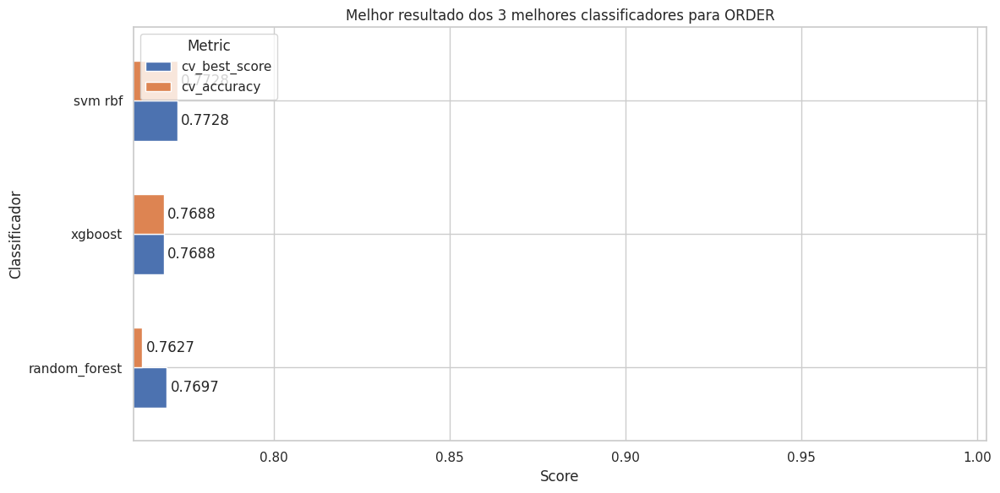

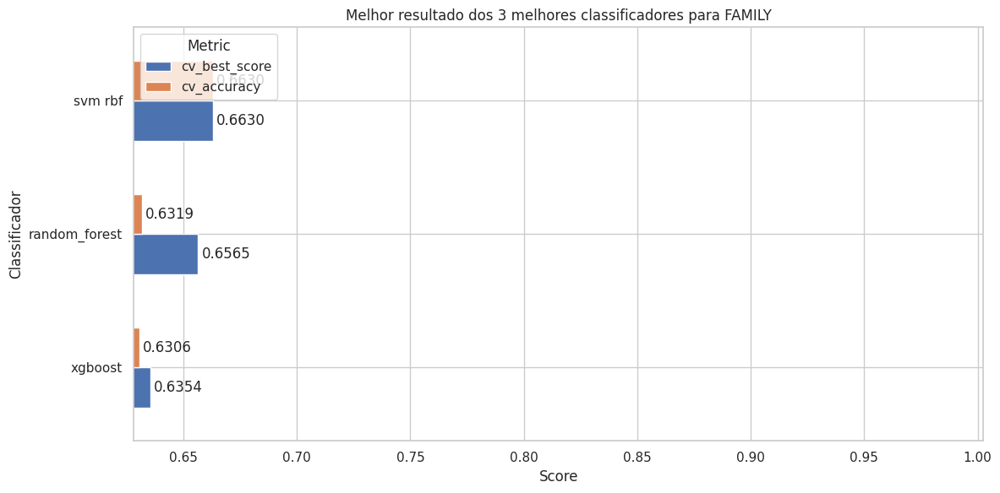

In [146]:
def plot_results(results, target):
  results_df = pd.DataFrame(results)

  plot_data = results_df.set_index('classifier')[results_df.columns[1:]].sort_values(by=['cv_accuracy', 'cv_best_score'])[-3:]

  ax = plot_data.plot(kind='barh', figsize=(12,6), width=0.6)

  ax.set(
    title=f"Melhor resultado dos 3 melhores classificadores para {target.upper()}",
    xlabel="Score",
    ylabel="Classificador",
    xlim=(plot_data.min().min() - 0.0025, 1.0025),
  )
  ax.legend(loc='upper left', ncols=1, title='Metric')

  for bars in ax.containers:
      ax.bar_label(bars, fmt='%.4f', padding=3)

  plt.tight_layout()
  plt.show()

plot_results(results_ord, TARGETS[0])
plot_results(results_fam, TARGETS[1])

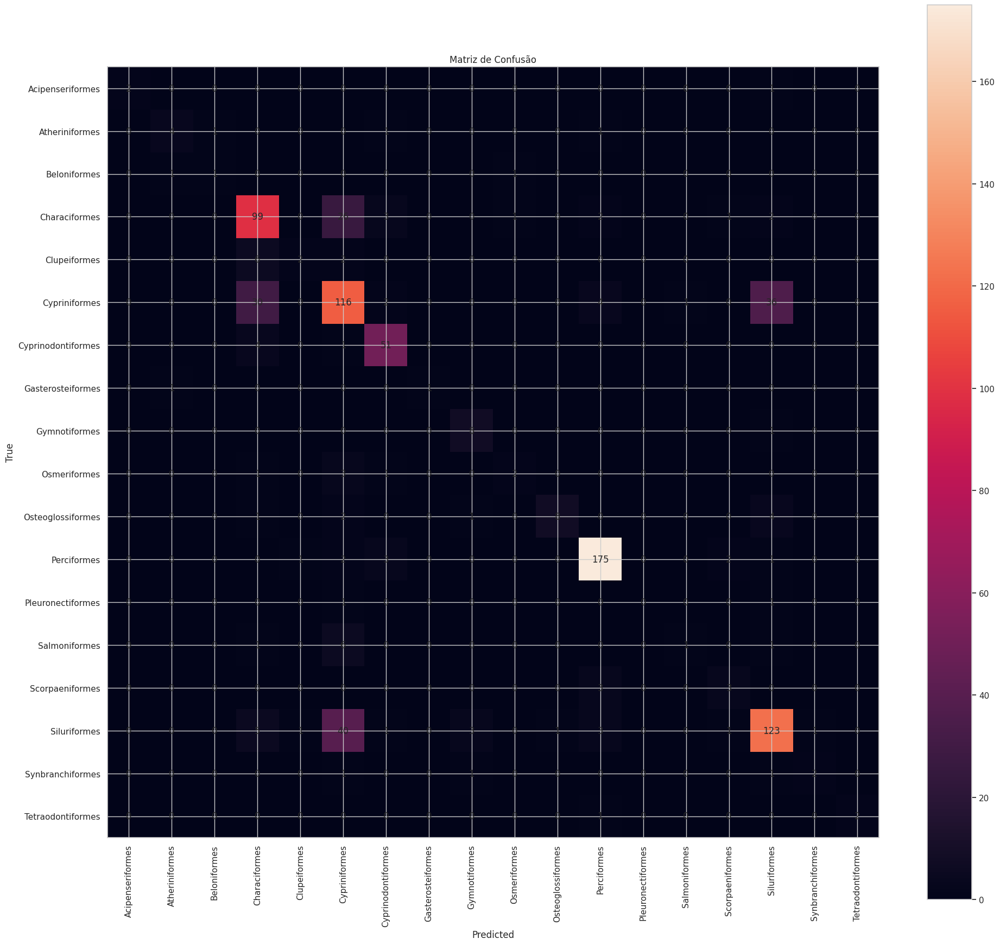

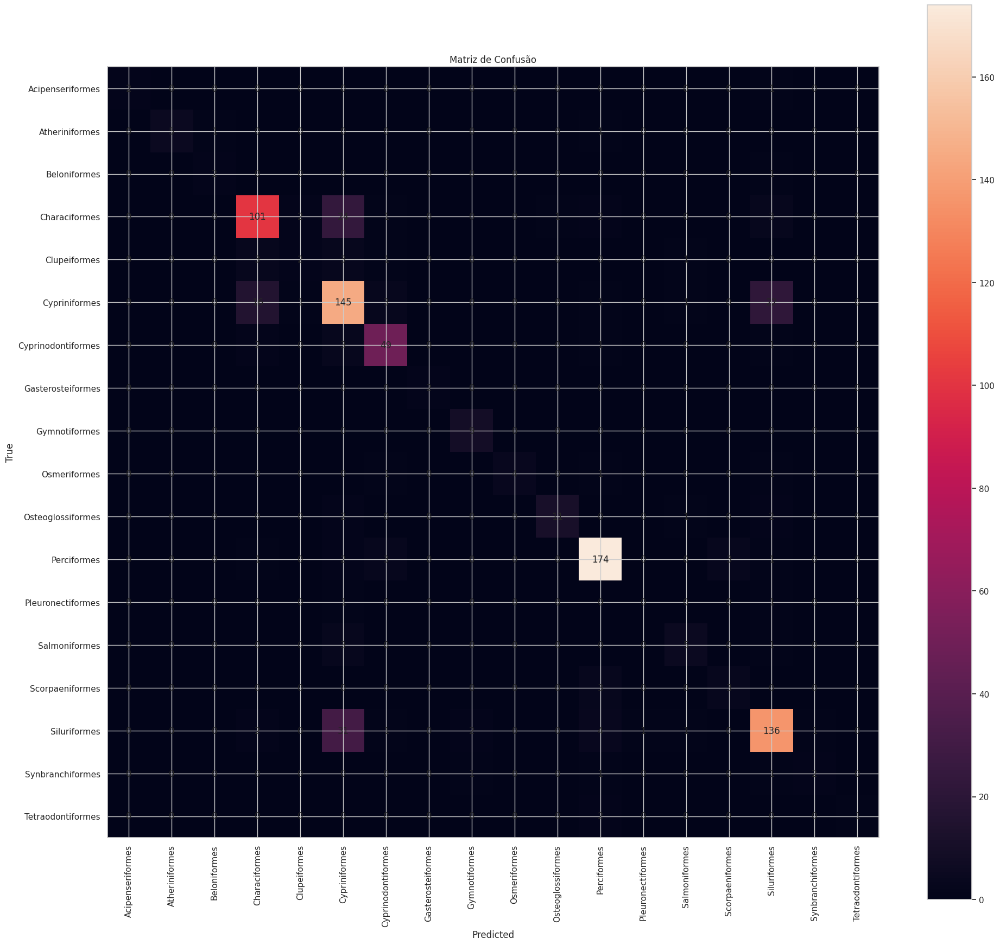

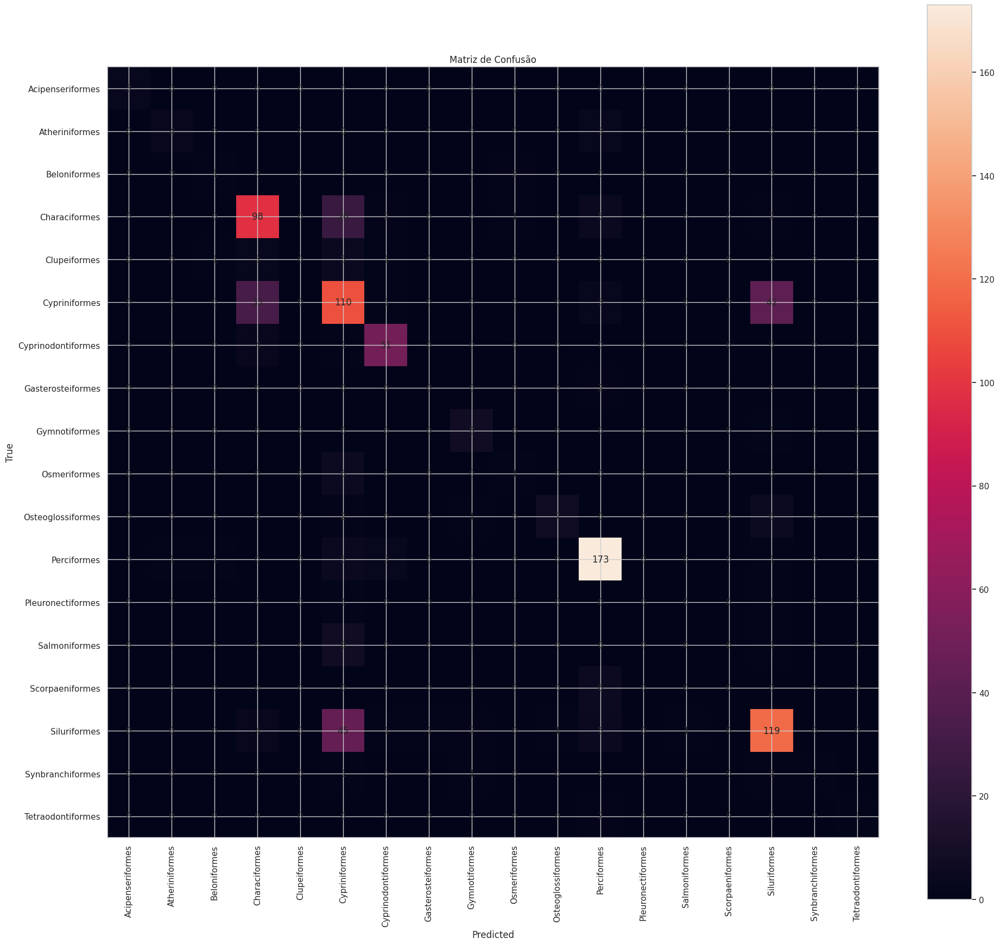

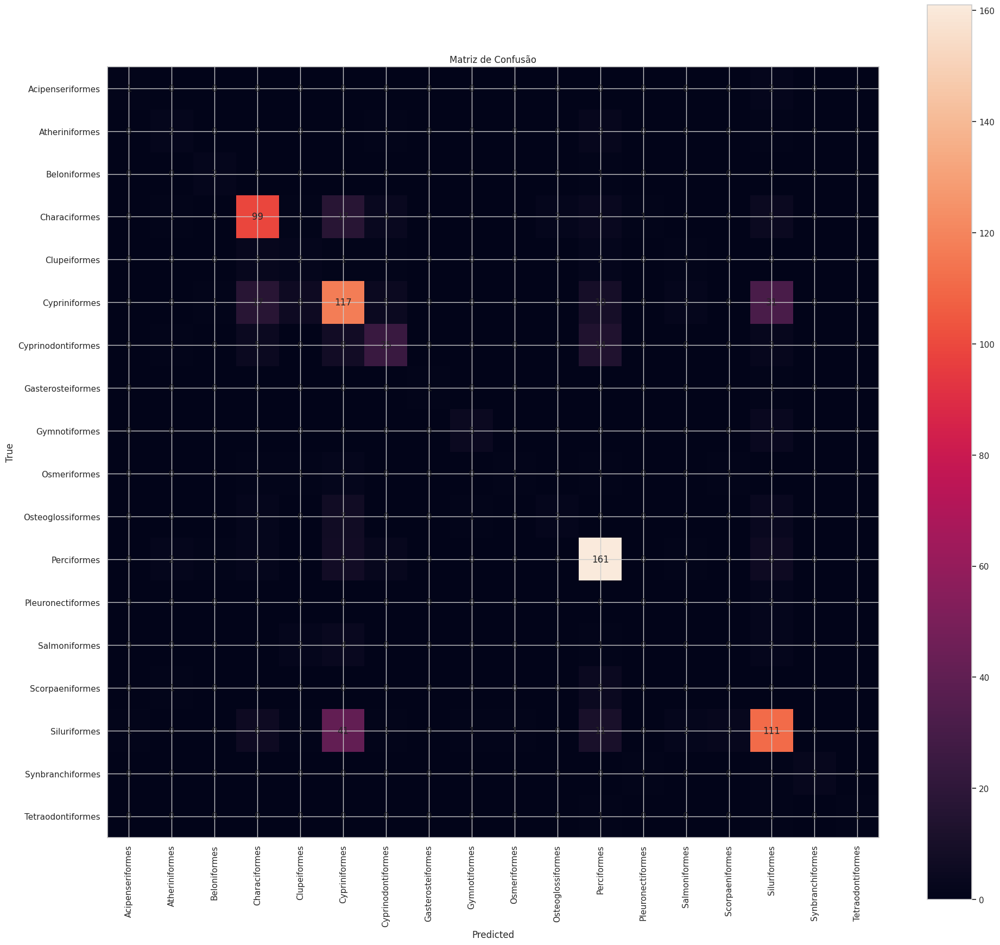

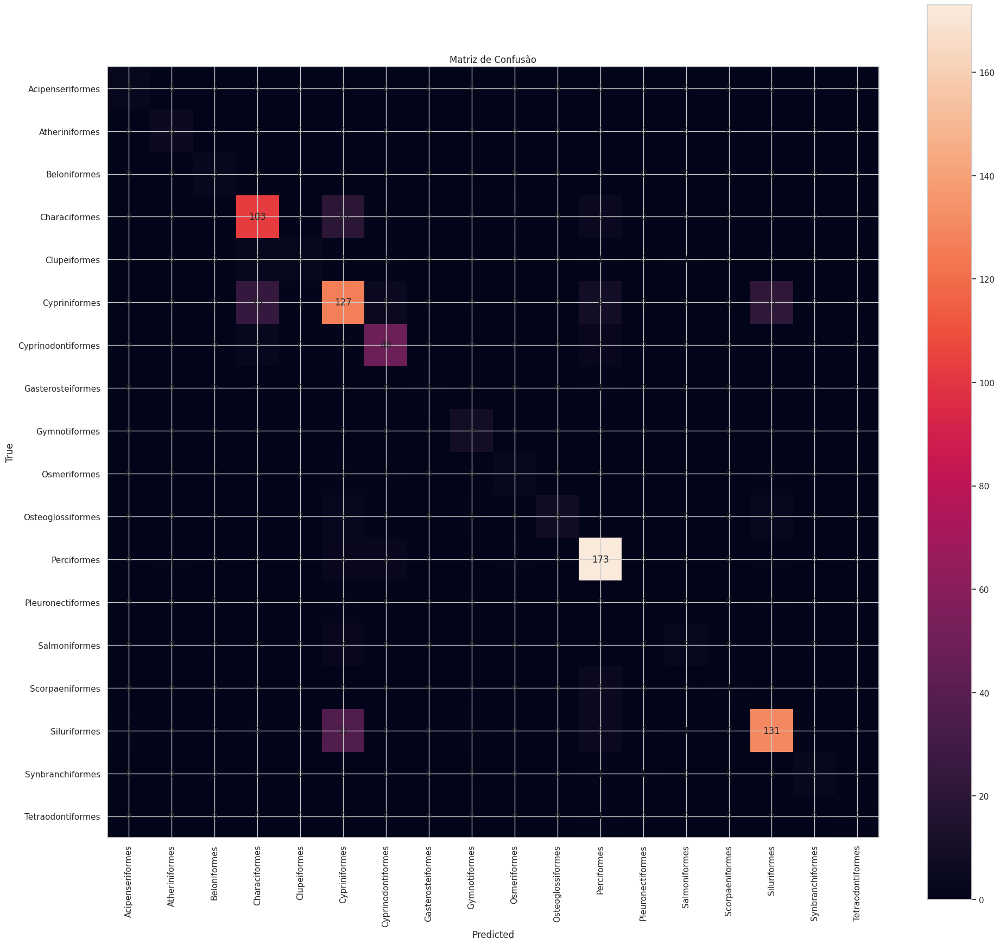

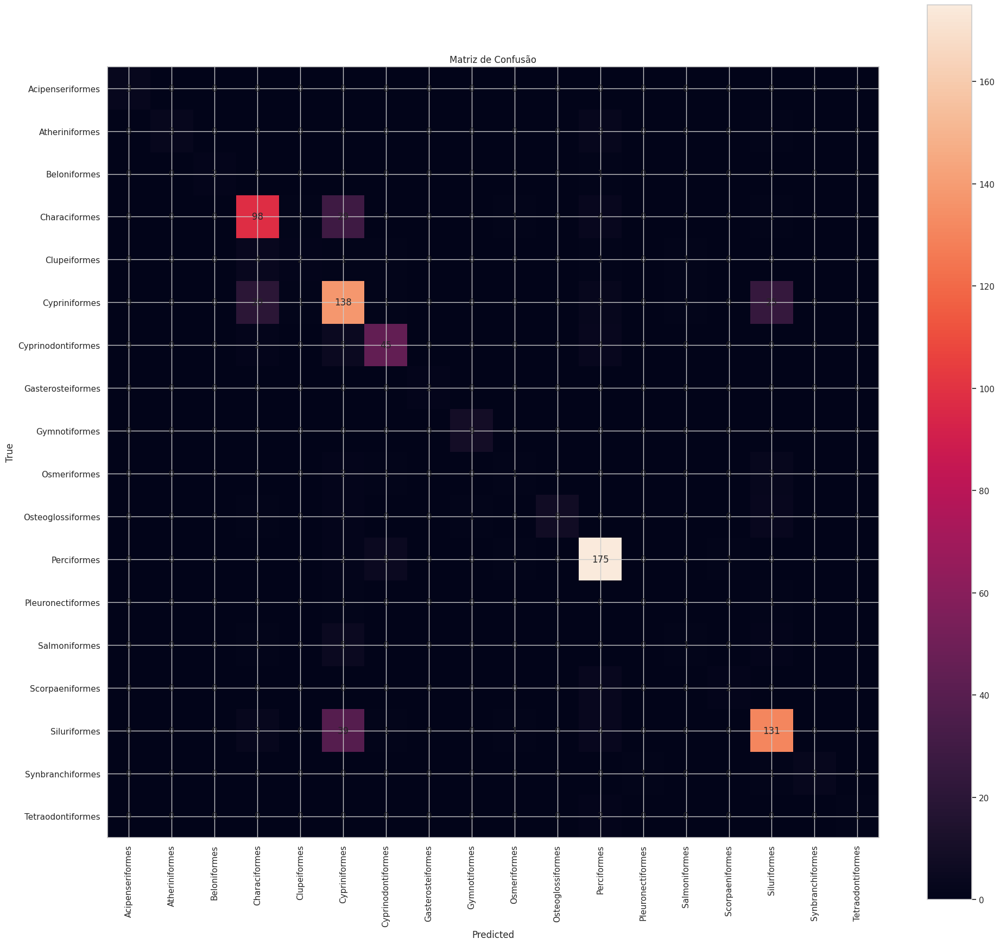

<Figure size 800x500 with 0 Axes>

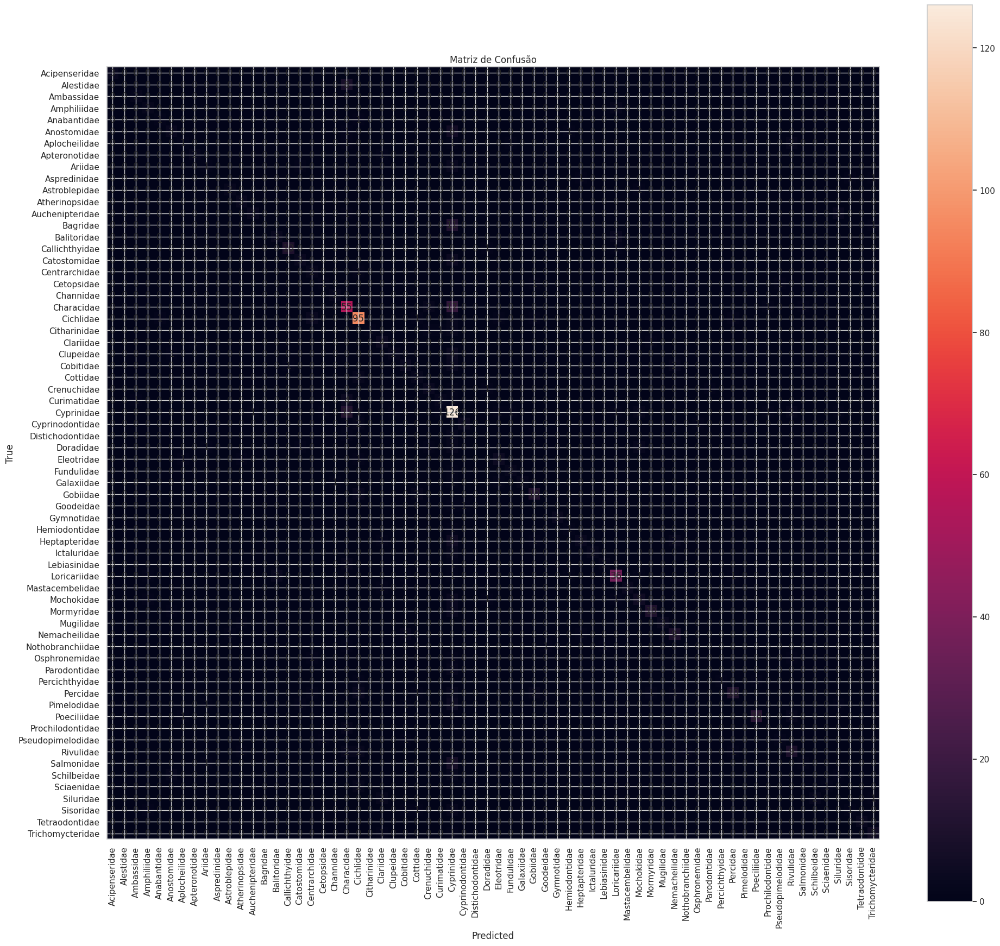

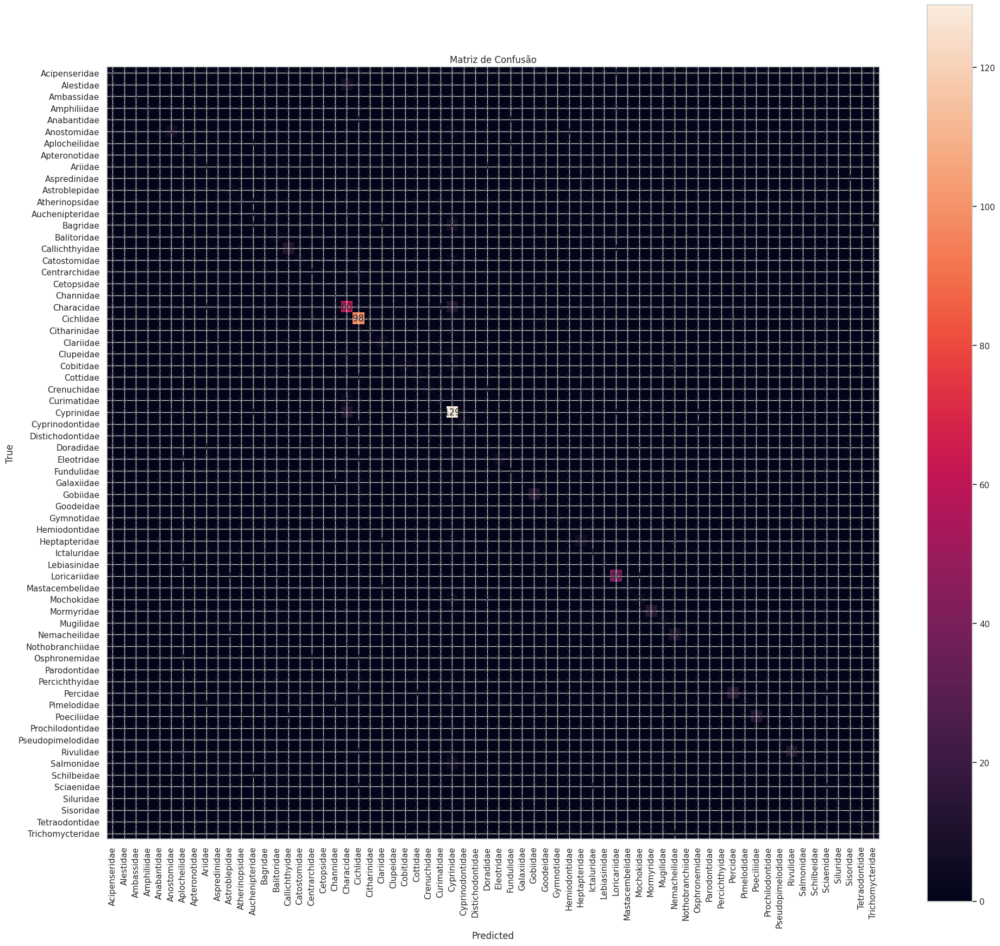

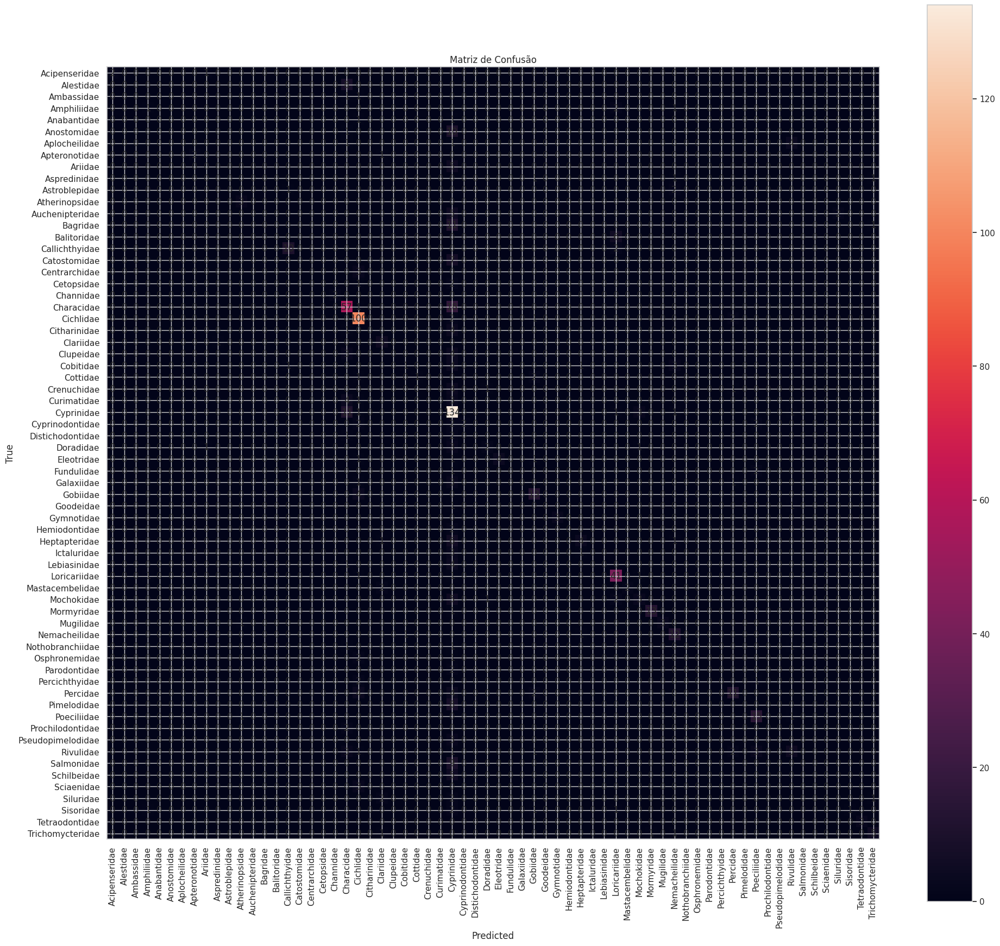

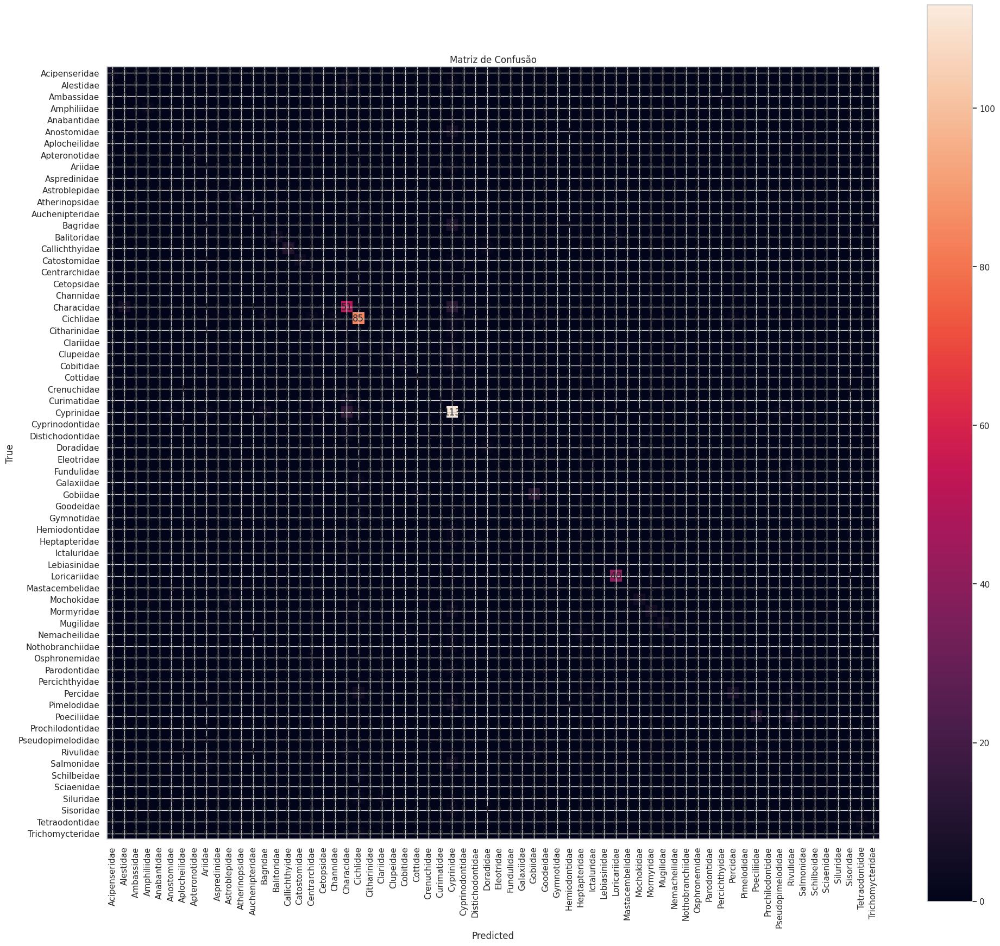

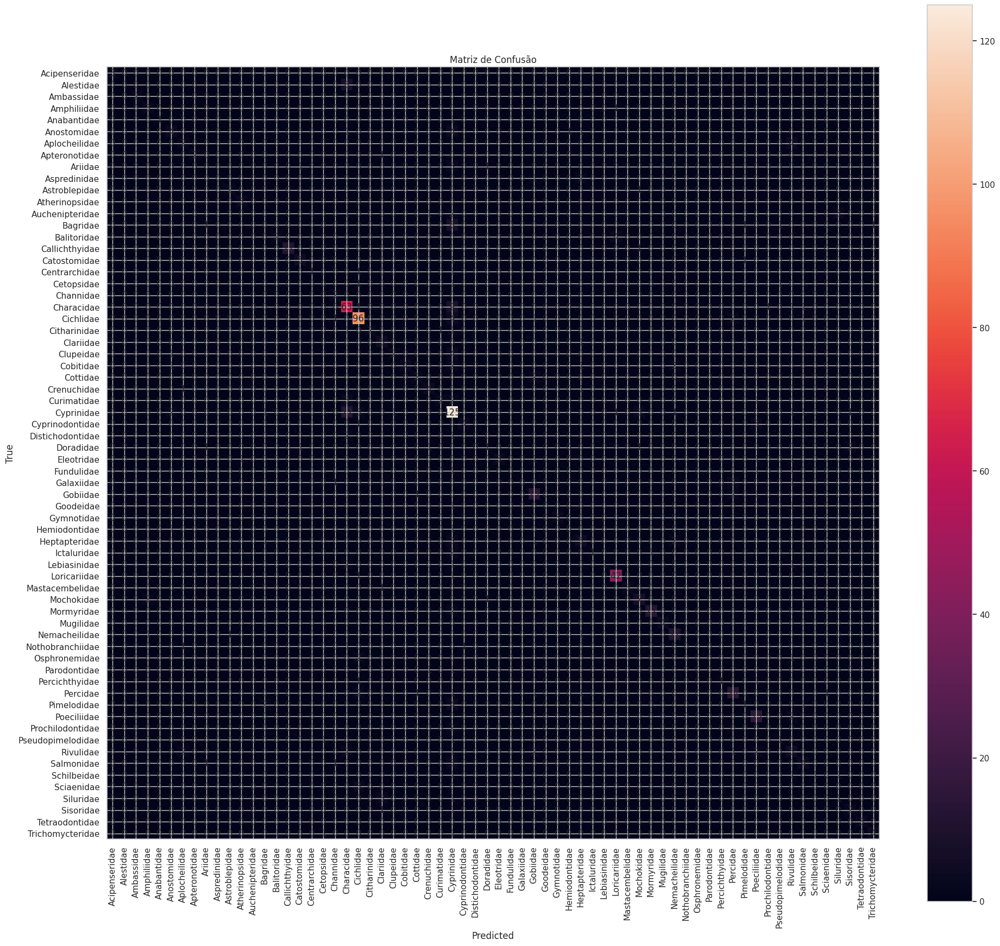

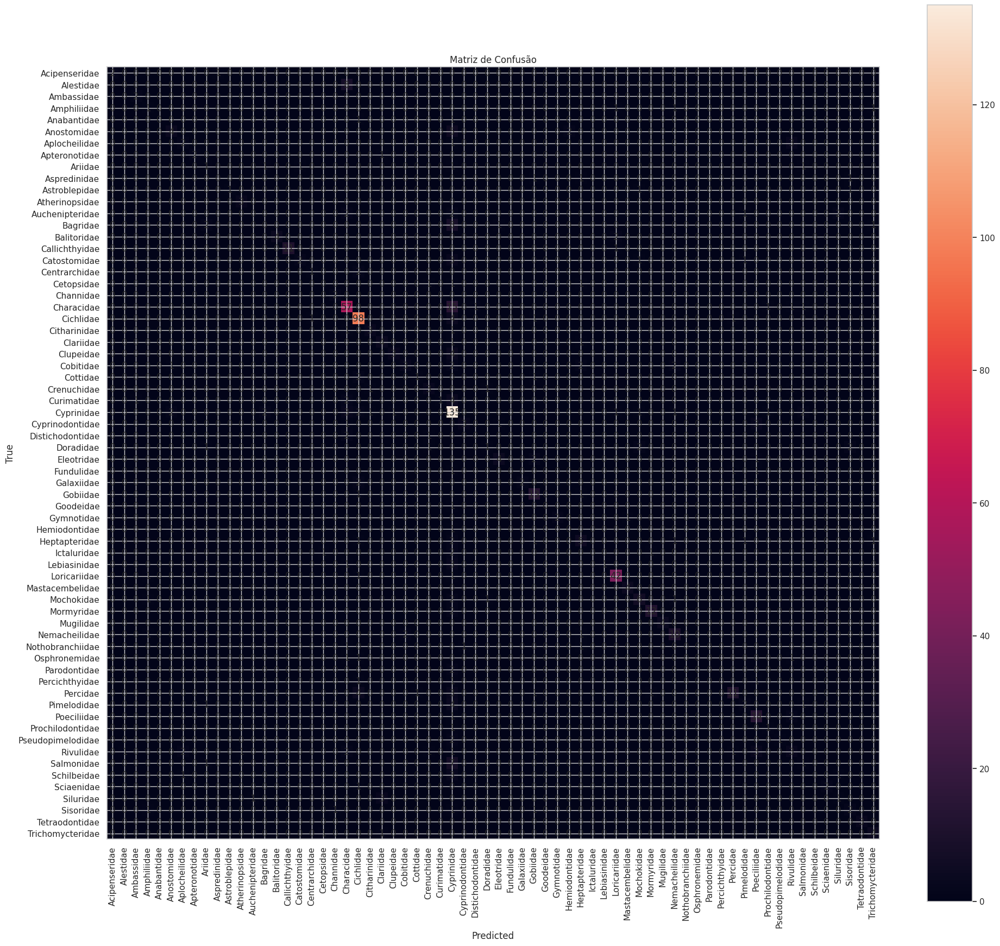

<Figure size 800x500 with 0 Axes>

In [165]:
def plot_confusion_matrices(predictions, x, x_test, y_test, target):
    for svm_type, prediction in predictions.items():
        labels = np.unique(np.concatenate([y_test, prediction]))

        cm = confusion_matrix(y_test, prediction, labels=labels)
        fig, ax = plt.subplots(figsize=(20, 18))
        im = ax.imshow(cm, interpolation='nearest')
        ax.figure.colorbar(im, ax=ax)
        ax.set_title("Matriz de Confusão")
        tick_marks = np.arange(len(labels))
        ax.set_xticks(tick_marks)
        ax.set_yticks(tick_marks)
        ax.set_xticklabels(labels, rotation=90)
        ax.set_yticklabels(labels)
        ax.set_xlabel('Predicted')
        ax.set_ylabel('True')
        for i in range(cm.shape[0]):
            for j in range(cm.shape[1]):
                ax.text(j, i, format(cm[i, j], 'd'),
                        ha="center", va="center")
        plt.tight_layout()
        plt.show()

    plt.tight_layout()
    plt.show()

plot_confusion_matrices(predictions_ord, x_ord, x_test_ord, y_test_ord, TARGETS[0])
plot_confusion_matrices(predictions_fam, x_fam, x_test_fam, y_test_fam, TARGETS[1])

In [148]:
# del candidates, clf, combinations, fam_df, file_name, iterations_df, ord_df, params_dict, value, values, x_fam, x_ord, x_test_ord, x_test_fam, x_train_ord, x_train_fam, y_ord, y_fam, y_test_ord, y_test_fam, y_train_ord, y_train_fam, cv_tables_fam, cv_tables_ord, fitted_fam, fitted_ord, predictions_fam, predictions_ord, results_fam, results_ord